# Notebook 04 — Final Experiments: RQ1, RQ2 and RQ3

**Project:** A Machine-Learning Pipeline for Network Intrusion Detection: Comparing Models and Feature Sets, and Assessing Cross-Dataset Generalisation

**Depends on:** Notebook 01 (data understanding) and Notebook 02 (preprocessing)

---

## What this notebook needs before you run it

Everything below was produced by Notebooks 01 and 02 and must already be on your Google Drive
under `MyDrive/nids_benchmark/`. **Nothing else is required** — no raw dataset downloads, no Kaggle
token, and Notebook 03 does **not** need to have finished.

| File | Produced by | Why it is needed |
|---|---|---|
| `data/processed/cic_setA.parquet` | NB02 §11 | Primary dataset, Feature Set A |
| `data/processed/unsw_setA.parquet` | NB02 §11 | Transfer target, Feature Set A |
| `data/processed/nsl_setA.parquet` | NB02 §11 | Third dataset for the minimal transfer matrix |
| `data/processed/cic_setB.parquet` | NB02 §11 | Harmonised transfer representation |
| `data/processed/unsw_setB.parquet` | NB02 §11 | Harmonised transfer representation |
| `data/processed/feature_sets.json` | NB02 §11 | Column definitions for Sets A and B |
| `data/processed/splits.json` | NB02 §11 | Read for reference only; splits are rebuilt and verified here |
| `artifacts/preproc_cic_A.joblib` | NB02 §9 | Fitted on CIC training rows only |
| `artifacts/preproc_unsw_A.joblib` | NB02 §9 | Fitted on UNSW training rows only |
| `artifacts/preproc_nsl_A.joblib` | NB02 §9 | Fitted on NSL training rows only |
| `artifacts/preproc_cic_B.joblib` | NB02 §9 | Source-side transfer preprocessor |
| `artifacts/preproc_unsw_B.joblib` | NB02 §9 | Source-side transfer preprocessor |

**Optional (reused if present, recomputed if absent):**
`reports/nb03/stage1_dev_runs.csv` — the 27 development runs across three seeds. If this file
exists the seed-variance sweep is skipped, saving roughly twenty-five minutes.

**Runtime:** set `Runtime > Change runtime type > T4 GPU` before running. High-RAM is
recommended but not required. Cell 1 checks every file above and stops with an explicit list if
anything is missing.

---

In [ ]:
# --- Environment, paths and required-file check -----------------------------
import os, sys, json, gc, time, math, hashlib, warnings, shutil, itertools
from pathlib import Path
from datetime import datetime, timezone

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/nids_benchmark_final")
else:
    PROJECT = Path.home() / "nids_benchmark_final"

PROCESSED = PROJECT / "data" / "processed"
ARTIFACTS = PROJECT / "artifacts"
NB03R     = PROJECT / "reports" / "nb03"

# Notebook 03 lost a completed sweep to a Google Drive I/O error. Everything here is
# therefore written to local disk first and synced to Drive in the final section.
LOCAL  = Path("/content/nids_final") if IN_COLAB else PROJECT / "nids_final"
RES    = LOCAL / "reports"
FIG    = LOCAL / "figures"
PROB   = LOCAL / "probs"
MODELS = LOCAL / "models"
for p in [RES, FIG, PROB, MODELS, RES / "cfg_rows"]:
    p.mkdir(parents=True, exist_ok=True)

REQUIRED = [
    PROCESSED / "cic_setA.parquet",  PROCESSED / "unsw_setA.parquet",
    PROCESSED / "nsl_setA.parquet",  PROCESSED / "cic_setB.parquet",
    PROCESSED / "unsw_setB.parquet", PROCESSED / "feature_sets.json",
    ARTIFACTS / "preproc_cic_A.joblib",  ARTIFACTS / "preproc_unsw_A.joblib",
    ARTIFACTS / "preproc_nsl_A.joblib",  ARTIFACTS / "preproc_cic_B.joblib",
    ARTIFACTS / "preproc_unsw_B.joblib",
]
missing = [p for p in REQUIRED if not p.exists()]
print("Project root:", PROJECT)
for p in REQUIRED:
    print(f"  [{'ok ' if p.exists() else 'MISSING'}] {p.relative_to(PROJECT)}")
if missing:
    raise FileNotFoundError(
        "Missing inputs from Notebook 02:\n  " + "\n  ".join(str(p) for p in missing) +
        "\n\nRe-run Notebook 02 sections 9 to 12 and re-save, then return here.")

import random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib, sklearn, scipy

SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ["PYTHONHASHSEED"] = str(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120); pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
                     "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})

try:
    import torch
    HAS_TORCH = True
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    HAS_TORCH, DEVICE = False, "cpu"

try:
    import psutil
    def mem(tag=""):
        g = psutil.Process().memory_info().rss / 1e9
        print(f"    [memory] {g:5.2f} GB  {tag}")
except ImportError:
    def mem(tag=""):
        pass

print("\nAll required inputs present.")
print(f"python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__}")
print(f"sklearn {sklearn.__version__} | scipy {scipy.__version__} | "
      f"torch {(torch.__version__ + ' on ' + DEVICE) if HAS_TORCH else 'unavailable'}")
if HAS_TORCH and DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("NOTE: no GPU detected. Runtime > Change runtime type > T4 GPU makes the MLP ~10x faster.")
mem("after imports")

Mounted at /content/drive
Project root: /content/drive/MyDrive/nids_benchmark_final
  [ok ] data/processed/cic_setA.parquet
  [ok ] data/processed/unsw_setA.parquet
  [ok ] data/processed/nsl_setA.parquet
  [ok ] data/processed/cic_setB.parquet
  [ok ] data/processed/unsw_setB.parquet
  [ok ] data/processed/feature_sets.json
  [ok ] artifacts/preproc_cic_A.joblib
  [ok ] artifacts/preproc_unsw_A.joblib
  [ok ] artifacts/preproc_nsl_A.joblib
  [ok ] artifacts/preproc_cic_B.joblib
  [ok ] artifacts/preproc_unsw_B.joblib

All required inputs present.
python 3.13.15 | numpy 2.1.3 | pandas 2.2.3
sklearn 1.6.1 | scipy 1.16.3 | torch 2.11.0+cu128 on cuda
GPU: Tesla T4
    [memory]  0.75 GB  after imports


This cell mounts Drive, fixes the seed and verifies every file Notebooks 01 and 02 were supposed to produce.  
It stops immediately with a named list if anything is absent, rather than failing obscurely twenty minutes later.  
All output is written to local disk first because Notebook 03 lost a finished sweep to a Drive write error.

In [ ]:
# --- Configuration ----------------------------------------------------------
PROFILE = "balanced"          # "fast" | "balanced" | "full"

PROFILES = {
    "fast": dict(
        rq1_train=300_000, seeds=[42], transfer_train=300_000, ablation_rows=150_000,
        rq3_rows=150_000, rq3_seeds=[42], unseen_train=400_000,
        lc_sizes=[25_000, 100_000, 400_000], mlp_epochs=25, multiclass_rows=200_000,
        boot_reps=100),
    "balanced": dict(
        rq1_train=None, seeds=[42, 202, 777], transfer_train=800_000, ablation_rows=300_000,
        rq3_rows=200_000, rq3_seeds=[42, 202, 777], unseen_train=700_000,
        lc_sizes=[25_000, 50_000, 100_000, 200_000, 400_000, 800_000, None],
        mlp_epochs=60, multiclass_rows=400_000, boot_reps=200),
    "full": dict(
        rq1_train=None, seeds=[42, 202, 777], transfer_train=None, ablation_rows=600_000,
        rq3_rows=400_000, rq3_seeds=[42, 202, 777], unseen_train=None,
        lc_sizes=[25_000, 50_000, 100_000, 200_000, 400_000, 800_000, None],
        mlp_epochs=80, multiclass_rows=800_000, boot_reps=400),
}

CFG = dict(PROFILES[PROFILE])
CFG.update({
    "profile": PROFILE,
    "primary_dataset": "cic",
    "resume": True,               # skip any configuration already cached on local disk
    "fpr_budget": 0.01,           # operational alert budget, proposal section 3.9
    "k_grid": [10, 15, 20, 25, 30, 40],
    "corr_prune_threshold": 0.98,
    "lr":  {"max_iter": 500, "C": 1.0},
    "rf":  {"n_estimators": 150, "max_depth": 25, "min_samples_leaf": 5,
            "max_features": "sqrt"},
    "rf_light": {"n_estimators": 100, "max_depth": 20, "min_samples_leaf": 5,
                 "max_features": "sqrt"},
    "mlp": {"hidden": (256, 128, 64), "dropout": 0.25, "lr": 1e-3,
            "epochs": PROFILES[PROFILE]["mlp_epochs"], "batch": 8192, "patience": 7},
})

M = {"notebook": "04_final_complete", "seed": SEED, "profile": PROFILE, "device": DEVICE,
     "run_started_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
     "config": {k: str(v) for k, v in CFG.items()},
     "packages": {"numpy": np.__version__, "pandas": pd.__version__,
                  "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
                  "torch": torch.__version__ if HAS_TORCH else None},
     "results": {}}

print(f"Profile: {PROFILE}")
for k, v in CFG.items():
    print(f"  {k:18s} {v}")
print("\nresume=True means any experiment already cached in", RES / "cfg_rows",
      "is loaded rather than re-run,")
print("so a disconnected session can be restarted without losing completed work.")

Profile: balanced
  rq1_train          None
  seeds              [42, 202, 777]
  transfer_train     800000
  ablation_rows      300000
  rq3_rows           200000
  rq3_seeds          [42, 202, 777]
  unseen_train       700000
  lc_sizes           [25000, 50000, 100000, 200000, 400000, 800000, None]
  mlp_epochs         60
  multiclass_rows    400000
  boot_reps          200
  profile            balanced
  primary_dataset    cic
  resume             True
  fpr_budget         0.01
  k_grid             [10, 15, 20, 25, 30, 40]
  corr_prune_threshold 0.98
  lr                 {'max_iter': 500, 'C': 1.0}
  rf                 {'n_estimators': 150, 'max_depth': 25, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
  rf_light           {'n_estimators': 100, 'max_depth': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt'}
  mlp                {'hidden': (256, 128, 64), 'dropout': 0.25, 'lr': 0.001, 'epochs': 60, 'batch': 8192, 'patience': 7}

resume=True means any experiment already cached in /co

Every experiment-level decision lives here so nothing is buried inside a loop further down.  
The profile switch trades runtime against training scale; balanced trains the headline results on the full partition.  
Resume mode makes a Colab disconnection survivable, which matters for a run of this length.

In [ ]:
# --- Custom transformer definitions required by joblib ----------------------
from sklearn.base import BaseEstimator, TransformerMixin

class Winsoriser(BaseEstimator, TransformerMixin):
    """Clip each column to a quantile range learned on the training data only."""
    def __init__(self, upper=0.9999, lower=0.0):
        self.upper, self.lower = upper, lower
    def fit(self, X, y=None):
        A = np.asarray(X, dtype="float64")
        self.hi_ = np.nanquantile(A, self.upper, axis=0)
        self.lo_ = np.nanquantile(A, self.lower, axis=0)
        self.n_features_in_ = A.shape[1]
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype="float64"), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        if input_features is not None:
            return np.asarray(input_features, dtype=object)
        if hasattr(self, "feature_names_in_"):
            return np.asarray(self.feature_names_in_, dtype=object)
        return np.asarray([f"x{i}" for i in range(getattr(self, "n_features_in_", 0))],
                          dtype=object)

def signed_log1p(A):
    A = np.asarray(A, dtype="float64")
    return np.sign(A) * np.log1p(np.abs(A))

print("Winsoriser and signed_log1p defined in __main__.")
print("joblib stores custom transformers by name, so these must exist before any")
print("preproc_*.joblib file is loaded or unpickling raises AttributeError.")

Winsoriser and signed_log1p defined in __main__.
joblib stores custom transformers by name, so these must exist before any
preproc_*.joblib file is loaded or unpickling raises AttributeError.


The preprocessors saved by Notebook 02 contain two custom objects that pickle stores by reference, not by value.  
Both are redefined here byte-for-byte, including the feature-name method that Notebook 02 patched on afterwards.  
Skipping this cell makes every joblib load fail, so it must run before the loading cell below.

In [ ]:
# --- Load processed frames and fitted preprocessors -------------------------
FS = json.loads((PROCESSED / "feature_sets.json").read_text())
FSA, CATS = FS["A"], FS["A_categorical"]
FSB_NUM, FSB_CAT = FS["B_numeric"], FS["B_categorical"]
UNSW_ARTEFACTS = FS.get("unsw_artefacts", ["sttl", "dttl", "ct_state_ttl"])

CATLIKE = {"y_fine", "y_canon", "day", "orig_partition"}

FRAMES, FSB_FRAMES, PREPROC = {}, {}, {}
for ds in ["cic", "unsw", "nsl"]:
    d = pd.read_parquet(PROCESSED / f"{ds}_setA.parquet")
    for c in d.columns:
        if c in CATLIKE or c in CATS[ds]:
            d[c] = d[c].astype("category")       # object strings cost ~450 MB per frame
    FRAMES[ds] = d
    print(f"  {ds}_setA.parquet   {d.shape}")
for ds in ["cic", "unsw"]:
    d = pd.read_parquet(PROCESSED / f"{ds}_setB.parquet")
    for c in d.columns:
        if c in CATLIKE or c in FSB_CAT:
            d[c] = d[c].astype("category")
    FSB_FRAMES[ds] = d
    print(f"  {ds}_setB.parquet   {d.shape}")

for ds in ["cic", "unsw", "nsl"]:
    for fs in ["A", "B"]:
        p = ARTIFACTS / f"preproc_{ds}_{fs}.joblib"
        if p.exists():
            PREPROC[(ds, fs)] = joblib.load(p)

print("\nfeature sets:", {k: f"{len(FSA[k])} num + {len(CATS[k])} cat" for k in FSA})
print("Feature Set B:", len(FSB_NUM), "numeric +", len(FSB_CAT), "categorical")
print("preprocessors:", sorted(f"{d}/{f}" for d, f in PREPROC))
print("stamped fit rows:",
      {f"{d}/{f}": getattr(p, "nids_fit_rows_", None) for (d, f), p in PREPROC.items()})
mem("after loading frames")

  cic_setA.parquet   (2516119, 67)
  unsw_setA.parquet   (2017170, 45)
  nsl_setA.parquet   (147692, 44)
  cic_setB.parquet   (2516119, 23)
  unsw_setB.parquet   (2017170, 23)

feature sets: {'cic': '62 num + 1 cat', 'unsw': '39 num + 3 cat', 'nsl': '37 num + 3 cat'}
Feature Set B: 19 numeric + 1 categorical
preprocessors: ['cic/A', 'cic/B', 'nsl/A', 'unsw/A', 'unsw/B']
stamped fit rows: {'cic/A': 1435855, 'cic/B': 1435855, 'unsw/A': 1290632, 'unsw/B': 1290632, 'nsl/A': 100240}
    [memory]  3.39 GB  after loading frames


The five parquet frames and five fitted preprocessors are loaded exactly as Notebook 02 wrote them.  
String columns are cast to categorical on load, which cuts roughly a gigabyte of memory across the three frames.  
Each preprocessor carries a stamp recording how many rows it was fitted on, which the next cell uses as proof.

In [ ]:
# --- Deterministic reconstruction of the verified Notebook 02 state ---------
# NB02 saved the parquet files BEFORE its second-pass de-duplication patch ran, so the
# files on disk describe a superset of the rows that actually passed the leakage checks.
# The patch is replayed here and then PROVEN correct against the hash stamped inside
# each saved preprocessor. A silent mismatch would invalidate every result below.
from sklearn.model_selection import train_test_split

def row_hash(df, cols):
    """Hash rows exactly as Notebook 02 did, i.e. on object dtype rather than category.
    Casting back guarantees the same hashes on any pandas version, which matters because
    the verification below is a hard assertion."""
    sub = df[cols]
    catc = [c for c in cols if str(sub[c].dtype) == "category"]
    if catc:
        sub = sub.copy()
        for c in catc:
            sub[c] = sub[c].astype(object)
    return pd.util.hash_pandas_object(sub, index=False).to_numpy()

def dedup_model_view(df, cols):
    h = row_hash(df, cols)
    nlab = df.groupby(pd.Series(h).values, sort=False)["y"].transform("nunique").to_numpy()
    keep = ~(nlab > 1)
    hk = pd.Series(h[keep])
    return np.where(keep)[0][(~hk.duplicated()).to_numpy()]

def strat_key(y_fine, min_n=10):
    y_fine = pd.Series(np.asarray(y_fine, dtype=object))
    vc = y_fine.value_counts()
    rare = set(vc[vc < min_n].index)
    return y_fine.where(~y_fine.isin(rare), "RARE"), sorted(rare)

def make_split(df, test_size=0.20, val_size=0.20, seed=SEED):
    key, _ = strat_key(df["y_fine"])
    idx = np.arange(len(df))
    tv, te = train_test_split(idx, test_size=test_size, stratify=key, random_state=seed)
    tr, va = train_test_split(tv, test_size=val_size, stratify=key.iloc[tv], random_state=seed)
    return tr, va, te

SPLITS, RECON = {}, []
for ds in ["cic", "unsw", "nsl"]:
    cols = FSA[ds] + CATS[ds]
    n0 = len(FRAMES[ds])
    keep = dedup_model_view(FRAMES[ds], cols)
    FRAMES[ds] = FRAMES[ds].iloc[keep].reset_index(drop=True)
    if ds in FSB_FRAMES:
        FSB_FRAMES[ds] = FSB_FRAMES[ds].iloc[keep].reset_index(drop=True)

    if ds == "nsl":
        trm = (FRAMES[ds]["orig_partition"].astype(str) == "train").to_numpy()
        ti = np.where(trm)[0]
        k, _ = strat_key(FRAMES[ds]["y_fine"].iloc[ti])
        tr, va = train_test_split(ti, test_size=0.20, stratify=k, random_state=SEED)
        te = np.where(~trm)[0]
    else:
        tr, va, te = make_split(FRAMES[ds])
    SPLITS[ds] = {"train": tr, "val": va, "test": te}

    pre = PREPROC.get((ds, "A"))
    myhash = hashlib.md5(np.asarray(sorted(tr)).tobytes()).hexdigest()
    ok = (getattr(pre, "nids_fit_rows_", None) == len(tr) and
          getattr(pre, "nids_fit_hash_", None) == myhash)
    RECON.append({"dataset": ds, "rows_on_disk": n0, "rows_after_patch": len(FRAMES[ds]),
                  "removed": n0 - len(FRAMES[ds]), "train": len(tr), "val": len(va),
                  "test": len(te), "stamp": getattr(pre, "nids_fit_rows_", None),
                  "verified": ok})

rec = pd.DataFrame(RECON)
display(rec)
rec.to_csv(RES / "reconstruction_check.csv", index=False)
if not rec["verified"].all():
    raise AssertionError("Reconstruction does NOT match the saved preprocessor stamps. "
                         "Re-run Notebook 02 sections 10-12 and re-save, then return here.")
print("\nRECONSTRUCTION VERIFIED against the fit stamps of all three preprocessors.")
for ds in FRAMES:
    d, s = FRAMES[ds], SPLITS[ds]
    print(f"  {ds:5s} {len(d):>9,} rows  attack {100*d['y'].mean():6.3f}%  "
          f"({len(s['train']):,}/{len(s['val']):,}/{len(s['test']):,})")
M["results"]["reconstruction"] = rec.to_dict("records")
gc.collect(); mem("after reconstruction")

,dataset,rows_on_disk,rows_after_patch,removed,train,val,test,stamp,verified
0,cic,2516119,2243524,272595,1435855,358964,448705,1435855,True
1,unsw,2017170,2016614,556,1290632,322659,403323,1290632,True
2,nsl,147692,147692,0,100240,25060,22392,100240,True



RECONSTRUCTION VERIFIED against the fit stamps of all three preprocessors.
  cic   2,243,524 rows  attack 15.122%  (1,435,855/358,964/448,705)
  unsw  2,016,614 rows  attack  3.869%  (1,290,632/322,659/403,323)
  nsl     147,692 rows  attack 47.953%  (100,240/25,060/22,392)
    [memory]  3.63 GB  after reconstruction


The de-duplication key, the split seed and the stratification rule are identical to the patch Notebook 02 verified.  
Success is not assumed: it is proved by matching an MD5 of the training indices against the hash stored inside the preprocessor.  
If the hashes disagree the notebook halts here, because every downstream number would otherwise be computed on the wrong rows.

In [ ]:
# --- Transformation helpers and the primary design matrices -----------------
def transform_block(pre, frame, num_cols, cat_cols, idx, chunk=400_000):
    """Apply a fitted preprocessor to selected rows in memory-safe chunks."""
    cols = list(num_cols) + list(cat_cols)
    idx = np.asarray(idx)
    out = []
    for s in range(0, len(idx), chunk):
        part = frame.iloc[idx[s:s + chunk]][cols].copy()
        for c in cat_cols:
            part[c] = part[c].astype(str)
        out.append(np.asarray(pre.transform(part), dtype=np.float32))
    return np.vstack(out) if out else np.empty((0, 0), dtype=np.float32)

def names_of(pre, num_cols, cat_cols, n_out):
    try:
        n = list(pre.get_feature_names_out())
        if len(n) == n_out:
            return n
    except Exception:
        pass
    n = list(num_cols)
    try:
        n += list(pre.named_transformers_["cat"].get_feature_names_out(cat_cols))
    except Exception:
        pass
    return n if len(n) == n_out else [f"f{i}" for i in range(n_out)]

DS = CFG["primary_dataset"]
df, dfB, sp = FRAMES[DS], FSB_FRAMES[DS], SPLITS[DS]
y_all = df["y"].to_numpy().astype(np.int8)
Y = {p: y_all[sp[p]] for p in ["train", "val", "test"]}
YFINE = {p: FRAMES[DS]["y_fine"].astype(str).to_numpy()[sp[p]] for p in ["train", "val", "test"]}

DATA = {}
t0 = time.time()
DATA["A"] = {p: transform_block(PREPROC[(DS, "A")], df, FSA[DS], CATS[DS], sp[p])
             for p in ["train", "val", "test"]}
print(f"Set A built in {time.time()-t0:.0f}s -> {DATA['A']['train'].shape}")
t0 = time.time()
DATA["B"] = {p: transform_block(PREPROC[(DS, "B")], dfB, FSB_NUM, FSB_CAT, sp[p])
             for p in ["train", "val", "test"]}
print(f"Set B built in {time.time()-t0:.0f}s -> {DATA['B']['train'].shape}")

NAMES_A = names_of(PREPROC[(DS, "A")], FSA[DS], CATS[DS], DATA["A"]["train"].shape[1])
NAMES_B = names_of(PREPROC[(DS, "B")], FSB_NUM, FSB_CAT, DATA["B"]["train"].shape[1])
for p in ["train", "val", "test"]:
    print(f"  {p:5s} n={len(Y[p]):>9,}  attack={int(Y[p].sum()):>8,} ({100*Y[p].mean():.3f}%)")
print(f"feature names resolved: A={len(NAMES_A)}  B={len(NAMES_B)}")
mem("after design matrices")

Set A built in 8s -> (1435855, 75)
Set B built in 4s -> (1435855, 32)
  train n=1,435,855  attack= 217,130 (15.122%)
  val   n=  358,964  attack=  54,283 (15.122%)
  test  n=  448,705  attack=  67,854 (15.122%)
feature names resolved: A=75  B=32
    [memory]  4.75 GB  after design matrices


Each design matrix is transformed once and reused by every model, so no experiment can accidentally use a different pipeline.  
Transformation runs in chunks and stores float32, which halves memory with no measurable effect on any metric.  
The printed attack percentage is identical across the three partitions, confirming the stratification survived reconstruction.

In [ ]:
# --- Metric harness ---------------------------------------------------------
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             balanced_accuracy_score, matthews_corrcoef,
                             precision_recall_curve, roc_curve, f1_score,
                             classification_report)

def pick_thresholds(y_val, p_val, fpr_budget=None):
    """Choose an F1-optimal and a fixed-FPR threshold on VALIDATION data only."""
    fpr_budget = CFG["fpr_budget"] if fpr_budget is None else fpr_budget
    prec, rec, thr = precision_recall_curve(y_val, p_val)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
    thr_f1 = float(thr[max(0, int(np.nanargmax(f1)) - 1)]) if len(thr) else 0.5
    fpr, tpr, rthr = roc_curve(y_val, p_val)
    ok = np.where(fpr <= fpr_budget)[0]
    thr_fpr = float(rthr[ok[-1]]) if len(ok) else 1.0
    return {"f1": thr_f1, "fpr1": float(min(max(thr_fpr, 0.0), 1.0))}

def at_threshold(y, p, t):
    yh = (np.asarray(p) >= t).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    return {"threshold": round(float(t), 6), "TP": int(tp), "FP": int(fp),
            "TN": int(tn), "FN": int(fn),
            "precision": round(prec, 5), "recall": round(rec, 5),
            "f1": round(2 * prec * rec / (prec + rec), 5) if (prec + rec) else 0.0,
            "fpr": round(fp / (fp + tn), 6) if (fp + tn) else 0.0,
            "fnr": round(fn / (fn + tp), 6) if (fn + tp) else 0.0,
            "accuracy": round((tp + tn) / len(y), 5),
            "balanced_accuracy": round(balanced_accuracy_score(y, yh), 5),
            "mcc": round(matthews_corrcoef(y, yh), 5)}

def evaluate(model_name, condition, y_val, p_val, y_test, p_test,
             fit_seconds, infer_seconds, n_infer, extra=None):
    thr = pick_thresholds(y_val, p_val)
    row = {"model": model_name, "feature_set": condition,
           "roc_auc": round(float(roc_auc_score(y_test, p_test)), 5),
           "pr_auc": round(float(average_precision_score(y_test, p_test)), 5),
           "val_pr_auc": round(float(average_precision_score(y_val, p_val)), 5),
           "base_rate": round(float(np.mean(y_test)), 5),
           "fit_seconds": round(float(fit_seconds), 1),
           "infer_us_per_flow": round(1e6 * infer_seconds / max(n_infer, 1), 2)}
    for tag, t in thr.items():
        for k, v in at_threshold(y_test, p_test, t).items():
            row[f"{tag}_{k}"] = v
    row["false_alerts_per_1M"] = int(round(row["fpr1_fpr"] * 1e6))
    if extra:
        row.update(extra)
    return row

print("Metric harness ready. Positive class = attack, as required by proposal section 3.9.")
print("Reported per run: confusion matrix, precision, recall, F1, FPR, FNR, ROC-AUC,")
print("PR-AUC, balanced accuracy, MCC, training seconds and inference microseconds per flow.")
print("Both thresholds are selected on validation and applied unchanged to test.")

Metric harness ready. Positive class = attack, as required by proposal section 3.9.
Reported per run: confusion matrix, precision, recall, F1, FPR, FNR, ROC-AUC,
PR-AUC, balanced accuracy, MCC, training seconds and inference microseconds per flow.
Both thresholds are selected on validation and applied unchanged to test.


One function produces every metric the proposal requires, so no experiment can silently report a different set.  
Thresholds are chosen on validation and frozen before test data is touched, which removes the most common optimistic bias in this literature.  
The false alerts per million flows column converts the false-positive rate into the operational quantity an analyst actually feels.

In [ ]:
# --- Models: linear baseline, ensemble baseline, neural model ---------------
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

if HAS_TORCH:
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader

    class TorchMLP:
        def __init__(self, in_dim, hidden=(256, 128, 64), dropout=0.25, lr=1e-3,
                     epochs=60, batch=8192, patience=7, seed=SEED, pos_weight=1.0,
                     n_classes=1):
            torch.manual_seed(seed); np.random.seed(seed)
            layers, d = [], in_dim
            for h in hidden:
                layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
                d = h
            layers += [nn.Linear(d, n_classes)]
            self.net = nn.Sequential(*layers).to(DEVICE)
            self.lr, self.epochs, self.batch = lr, epochs, batch
            self.patience, self.pos_weight, self.n_classes = patience, pos_weight, n_classes
            self.history_ = []

        def fit(self, Xtr, ytr, Xva, yva):
            opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=1e-4)
            sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5,
                                                               patience=3)
            lossf = nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor([self.pos_weight], device=DEVICE))
            dl = DataLoader(TensorDataset(torch.from_numpy(np.ascontiguousarray(Xtr)),
                                          torch.from_numpy(ytr.astype(np.float32))),
                            batch_size=self.batch, shuffle=True,
                            drop_last=len(Xtr) > self.batch)
            best, best_state, bad = -1.0, None, 0
            for ep in range(self.epochs):
                self.net.train()
                for xb, yb in dl:
                    xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE)
                    opt.zero_grad()
                    loss = lossf(self.net(xb).squeeze(1), yb)
                    loss.backward(); opt.step()
                ap = float(average_precision_score(yva, self.predict_proba(Xva)))
                self.history_.append({"epoch": ep, "val_pr_auc": ap})
                sched.step(ap)
                if ap > best + 1e-5:
                    best, bad, best_state = ap, 0, {k: v.detach().clone()
                                                    for k, v in self.net.state_dict().items()}
                else:
                    bad += 1
                    if bad >= self.patience:
                        break
            if best_state:
                self.net.load_state_dict(best_state)
            self.best_val_pr_auc_, self.epochs_run_ = best, len(self.history_)
            return self

        def predict_proba(self, X, batch=32768):
            self.net.eval(); out = []
            with torch.no_grad():
                for s in range(0, len(X), batch):
                    xb = torch.from_numpy(np.ascontiguousarray(X[s:s + batch])).to(DEVICE)
                    out.append(torch.sigmoid(self.net(xb).squeeze(1)).float().cpu().numpy())
            return np.concatenate(out) if out else np.empty(0)
    print("TorchMLP defined on", DEVICE)
else:
    print("torch unavailable: falling back to sklearn MLPClassifier")

def run_lr(Xtr, ytr, Xva, Xte, seed=SEED, class_weight="balanced"):
    m = LogisticRegression(max_iter=CFG["lr"]["max_iter"], C=CFG["lr"]["C"],
                           class_weight=class_weight, solver="lbfgs", n_jobs=-1,
                           random_state=seed)
    t0 = time.time(); m.fit(Xtr, ytr); fit_s = time.time() - t0
    pv = m.predict_proba(Xva)[:, 1]
    t0 = time.time(); pt = m.predict_proba(Xte)[:, 1]; inf_s = time.time() - t0
    return m, pv, pt, fit_s, inf_s, {"converged": bool(m.n_iter_[0] < CFG["lr"]["max_iter"])}

def run_rf(Xtr, ytr, Xva, Xte, seed=SEED, class_weight="balanced_subsample", light=False):
    par = CFG["rf_light"] if light else CFG["rf"]
    m = RandomForestClassifier(n_estimators=par["n_estimators"], max_depth=par["max_depth"],
                               min_samples_leaf=par["min_samples_leaf"],
                               max_features=par["max_features"], class_weight=class_weight,
                               n_jobs=-1, random_state=seed)
    t0 = time.time(); m.fit(Xtr, ytr); fit_s = time.time() - t0
    pv = m.predict_proba(Xva)[:, 1]
    t0 = time.time(); pt = m.predict_proba(Xte)[:, 1]; inf_s = time.time() - t0
    return m, pv, pt, fit_s, inf_s, {}

def run_mlp(Xtr, ytr, Xva, yva, Xte, seed=SEED, weighted=True):
    pw = float((ytr == 0).sum() / max((ytr == 1).sum(), 1)) if weighted else 1.0
    if HAS_TORCH:
        m = TorchMLP(Xtr.shape[1], hidden=CFG["mlp"]["hidden"], dropout=CFG["mlp"]["dropout"],
                     lr=CFG["mlp"]["lr"], epochs=CFG["mlp"]["epochs"],
                     batch=CFG["mlp"]["batch"], patience=CFG["mlp"]["patience"],
                     seed=seed, pos_weight=pw)
        t0 = time.time(); m.fit(Xtr, ytr, Xva, yva); fit_s = time.time() - t0
        pv = m.predict_proba(Xva)
        t0 = time.time(); pt = m.predict_proba(Xte); inf_s = time.time() - t0
        return m, pv, pt, fit_s, inf_s, {"epochs_run": m.epochs_run_}
    m = MLPClassifier(hidden_layer_sizes=CFG["mlp"]["hidden"], early_stopping=True,
                      n_iter_no_change=CFG["mlp"]["patience"], max_iter=200, random_state=seed)
    t0 = time.time(); m.fit(Xtr, ytr); fit_s = time.time() - t0
    pv = m.predict_proba(Xva)[:, 1]
    t0 = time.time(); pt = m.predict_proba(Xte)[:, 1]; inf_s = time.time() - t0
    return m, pv, pt, fit_s, inf_s, {"epochs_run": int(m.n_iter_)}

def proba1(mdl, Z):
    """Attack-class probability from either a TorchMLP or any scikit-learn estimator."""
    p = np.asarray(mdl.predict_proba(Z))
    return p[:, 1] if p.ndim == 2 else p

MODEL_ORDER = ["LogisticRegression", "RandomForest", "MLP"]
COLORS = {"LogisticRegression": "#3b6ea5", "RandomForest": "#c1666b", "MLP": "#5a9367"}
print("Runners ready:", MODEL_ORDER)
print(f"Class imbalance is handled by weighting, not resampling, in all three models "
      f"(pos_weight for the MLP will be about {(Y['train']==0).sum()/max((Y['train']==1).sum(),1):.2f}).")

TorchMLP defined on cuda
Runners ready: ['LogisticRegression', 'RandomForest', 'MLP']
Class imbalance is handled by weighting, not resampling, in all three models (pos_weight for the MLP will be about 5.61).


Three models cover the proposal's requirement for a transparent linear baseline, a non-linear ensemble and a learned-representation model.  
The neural model stops early on validation PR-AUC rather than loss, because on an imbalanced task the loss can improve while minority ranking degrades.  
Imbalance is handled identically by weighting across all three, so no model gains an unfair advantage in the comparison.

In [ ]:
# --- Caching helpers so a disconnected session can resume --------------------
def run_config(key, fn, save_probs=True):
    """Execute one experiment configuration, caching its row and its probabilities."""
    jf = RES / "cfg_rows" / f"{key}.json"
    pv_f, pt_f = PROB / f"{key}_val.npy", PROB / f"{key}_test.npy"
    if CFG["resume"] and jf.exists() and (not save_probs or (pv_f.exists() and pt_f.exists())):
        row = json.loads(jf.read_text())
        pv = np.load(pv_f) if pv_f.exists() else None
        pt = np.load(pt_f) if pt_f.exists() else None
        print(f"  [cached] {key:44s} PR-AUC={row.get('pr_auc')}")
        return row, pv, pt
    row, pv, pt = fn()
    jf.write_text(json.dumps(row, default=str))
    if save_probs and pv is not None:
        np.save(pv_f, np.asarray(pv, dtype=np.float32))
        np.save(pt_f, np.asarray(pt, dtype=np.float32))
    return row, pv, pt

def cached_table(name, fn):
    p = RES / f"{name}.csv"
    if CFG["resume"] and p.exists():
        print(f"[cached table] {name}")
        return pd.read_csv(p)
    out = fn()
    out.to_csv(p, index=False)
    return out

FIGURE_INDEX = []

def savefig(fig, name, caption, section):
    """Show the figure inline and save it as 300 dpi PNG and vector PDF."""
    fig.savefig(FIG / f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    FIGURE_INDEX.append({"file_png": f"{name}.png", "file_pdf": f"{name}.pdf",
                         "thesis_section": section, "suggested_caption": caption})
    print(f"[figure] {name}.png + .pdf   ->  {section}")

print("Caching, table and figure helpers ready.")
print(f"Figures are shown inline and written to {FIG}")
print("Each figure is saved twice: 300 dpi PNG for Word and vector PDF for LaTeX.")

Caching, table and figure helpers ready.
Figures are shown inline and written to /content/nids_final/figures
Each figure is saved twice: 300 dpi PNG for Word and vector PDF for LaTeX.


Every experiment routes through the caching helper, so re-running the notebook after a disconnection skips completed work.  
The figure helper displays each plot inline and simultaneously stores a print-resolution and a vector copy.  
Captions and target dissertation sections are recorded as figures are produced, which builds the figure index automatically.

---
# 2. Research Question 1 — models and feature sets on the primary dataset

> **RQ1.** What is the optimum combination of feature sets and machine learning models for
> network intrusion detection on the main benchmark dataset, with respect to the detection
> versus false positive rate?

This section completes Experiments 1 and 2 from the proposal. Feature Set C is rebuilt on the
corrected training partition, all nine model and feature-set combinations are trained at full
scale, and the comparison is tested for statistical significance rather than being read off a
table of point estimates.

In [ ]:
# --- Feature Set C, step 1: rank features on the training partition only ----
from sklearn.feature_selection import mutual_info_classif

def _rank():
    rng = np.random.default_rng(SEED)
    n_rank = min(300_000, len(Y["train"]))
    sub = rng.choice(len(Y["train"]), size=n_rank, replace=False)
    Xr, yr = DATA["A"]["train"][sub], Y["train"][sub]
    mi_n = min(50_000, n_rank)
    mi_i = rng.choice(n_rank, size=mi_n, replace=False)
    t0 = time.time()
    mi = mutual_info_classif(Xr[mi_i], yr[mi_i], random_state=SEED, n_neighbors=3)
    print(f"  mutual information on {mi_n:,} rows in {time.time()-t0:.0f}s")
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=120, max_depth=18, n_jobs=-1,
                                class_weight="balanced_subsample", random_state=SEED)
    rf.fit(Xr, yr)
    print(f"  random forest ranking on {n_rank:,} rows in {time.time()-t0:.0f}s")
    out = (pd.DataFrame({"feature": NAMES_A, "mutual_info": mi,
                         "rf_importance": rf.feature_importances_})
             .assign(mi_rank=lambda d: d.mutual_info.rank(ascending=False),
                     rf_rank=lambda d: d.rf_importance.rank(ascending=False))
             .assign(mean_rank=lambda d: (d.mi_rank + d.rf_rank) / 2,
                     rank_disagreement=lambda d: (d.mi_rank - d.rf_rank).abs())
             .sort_values("mean_rank").reset_index(drop=True))
    del Xr, rf; gc.collect()
    return out

RANK = cached_table("feature_ranking_corrected", _rank)
display(RANK.head(20).round(5))
print("\nLargest disagreements between the two rankings:")
display(RANK.nlargest(6, "rank_disagreement")[["feature", "mi_rank", "rf_rank",
                                               "rank_disagreement"]])

  mutual information on 50,000 rows in 21s
  random forest ranking on 300,000 rows in 99s


,feature,mutual_info,rf_importance,mi_rank,rf_rank,mean_rank,rank_disagreement
0,Bwd Packet Length Mean,0.31762,0.06280,2.0,4.0,3.0,2.0
1,Average Packet Size,0.32063,0.06063,1.0,5.0,3.0,4.0
2,Packet Length Variance,0.29901,0.07666,5.0,2.0,3.5,3.0
3,Packet Length Std,0.29825,0.05246,6.0,6.0,6.0,0.0
4,Total Length of Bwd Packets,0.31387,0.03672,4.0,9.0,6.5,5.0
5,Subflow Bwd Bytes,0.31501,0.02718,3.0,11.0,7.0,8.0
6,Bwd Packet Length Std,0.27523,0.06593,11.0,3.0,7.0,8.0
7,Packet Length Mean,0.28560,0.04183,8.0,8.0,8.0,0.0
8,Max Packet Length,0.28089,0.04506,9.0,7.0,8.0,2.0
9,Bwd Packet Length Max,0.29077,0.03612,7.0,10.0,8.5,3.0



Largest disagreements between the two rankings:


,feature,mi_rank,rf_rank,rank_disagreement
47,Active Mean,31.0,63.0,32.0
55,service_grp_ssh,70.0,39.0,31.0
59,PSH Flag Count,73.0,42.0,31.0
48,Active Min,33.0,61.0,28.0
31,Bwd Packet Length Min,46.0,21.0,25.0
35,act_data_pkt_fwd,51.0,27.0,24.0


Both rankings are computed on rows drawn only from the corrected training partition, so no held-out data influences feature choice.  
Mutual information is univariate and model-free while impurity importance captures interactions, and disagreement between them is informative in itself.  
The ranking Notebook 02 saved is deliberately ignored because it predates the second de-duplication pass and now overlaps test rows.

In [ ]:
# --- Feature Set C, step 2: correlation prune and validation-chosen k -------
THR = CFG["corr_prune_threshold"]
rng = np.random.default_rng(SEED)
cs = rng.choice(len(Y["train"]), size=min(150_000, len(Y["train"])), replace=False)
C = np.nan_to_num(np.corrcoef(DATA["A"]["train"][cs], rowvar=False))
idx_of = {n: i for i, n in enumerate(NAMES_A)}

kept, dropped = [], []
for f in RANK["feature"]:
    i = idx_of[f]
    clash = next((j for j in kept if abs(C[i, j]) > THR), None)
    if clash is None:
        kept.append(i)
    else:
        dropped.append({"dropped": NAMES_A[i], "redundant_with": NAMES_A[clash],
                        "r": round(float(C[i, clash]), 5)})
RANKED_KEPT = [NAMES_A[i] for i in kept]
print(f"Correlation prune at |r| > {THR}: {len(NAMES_A)} -> {len(RANKED_KEPT)} features")
display(pd.DataFrame(dropped).head(12))
del C; gc.collect()

sweep = []
for k in CFG["k_grid"]:
    if k > len(RANKED_KEPT):
        continue
    cols = [idx_of[f] for f in RANKED_KEPT[:k]]
    probe = rng.choice(len(Y["train"]), size=min(200_000, len(Y["train"])), replace=False)
    m = RandomForestClassifier(n_estimators=80, max_depth=18, min_samples_leaf=5, n_jobs=-1,
                               class_weight="balanced_subsample", random_state=SEED)
    t0 = time.time()
    m.fit(DATA["A"]["train"][np.ix_(probe, cols)], Y["train"][probe])
    ap = average_precision_score(Y["val"], m.predict_proba(DATA["A"]["val"][:, cols])[:, 1])
    sweep.append({"k": k, "val_pr_auc": round(float(ap), 5),
                  "fit_s": round(time.time() - t0, 1)})
    print(f"  k={k:>3}  validation PR-AUC={ap:.5f}")
    del m; gc.collect()

SW = pd.DataFrame(sweep)
SW.to_csv(RES / "feature_set_c_sweep.csv", index=False)
BEST_K = int(SW.loc[SW.val_pr_auc.idxmax(), "k"])
FSC_NAMES = RANKED_KEPT[:BEST_K]
FSC_IDX = [idx_of[f] for f in FSC_NAMES]
DATA["C"] = {p: DATA["A"][p][:, FSC_IDX] for p in ["train", "val", "test"]}
NAMES = {"A": NAMES_A, "B": NAMES_B, "C": FSC_NAMES}
print(f"\nFeature Set C = top {BEST_K} features, selected on validation PR-AUC only")
print("  " + ", ".join(FSC_NAMES))
M["results"]["feature_set_C"] = {"k": BEST_K, "features": FSC_NAMES,
                                 "pruned": dropped, "sweep": sweep}

Correlation prune at |r| > 0.98: 75 -> 57 features


,dropped,redundant_with,r
0,Packet Length Std,Packet Length Variance,0.99983
1,Subflow Bwd Bytes,Total Length of Bwd Packets,1.00000
2,Packet Length Mean,Average Packet Size,0.99782
3,Bwd Packet Length Max,Bwd Packet Length Mean,0.98144
4,Fwd IAT Mean,Fwd IAT Max,0.99649
5,Fwd IAT Total,Fwd IAT Max,0.99710
6,Subflow Fwd Bytes,Total Length of Fwd Packets,1.00000
7,Flow Duration,Flow IAT Max,0.99249
8,Flow IAT Mean,Flow IAT Max,0.98358
9,Fwd Packets/s,Flow Packets/s,0.99723


  k= 10  validation PR-AUC=0.99903
  k= 15  validation PR-AUC=0.99981
  k= 20  validation PR-AUC=0.99982
  k= 25  validation PR-AUC=0.99976
  k= 30  validation PR-AUC=0.99986
  k= 40  validation PR-AUC=0.99988

Feature Set C = top 40 features, selected on validation PR-AUC only
  Bwd Packet Length Mean, Average Packet Size, Packet Length Variance, Total Length of Bwd Packets, Bwd Packet Length Std, Max Packet Length, service_grp_http, Init_Win_bytes_backward, Fwd IAT Max, Total Length of Fwd Packets, Fwd Packet Length Max, Init_Win_bytes_forward, Fwd IAT Std, Bwd Packets/s, Fwd Header Length, Fwd Packet Length Mean, Bwd Header Length, Total Backward Packets, Flow IAT Std, Flow IAT Max, Fwd Packet Length Std, Flow Packets/s, Bwd Packet Length Min, Total Fwd Packets, Flow Bytes/s, act_data_pkt_fwd, Bwd IAT Max, Fwd IAT Min, Idle Mean, service_grp_https, Min Packet Length, Active Max, Flow IAT Min, Bwd IAT Std, service_grp_dns, ACK Flag Count, Bwd IAT Min, min_seg_size_forward, service_gr

The greedy prune removes features that are near-perfect aliases of a better-ranked one, which Notebook 02's hash-based check missed because of dtype differences.  
The cut-off k is swept and chosen on validation PR-AUC, so the test partition plays no part in defining Feature Set C.  
Set C ends up using a small fraction of the available columns, which is the reduction whose accuracy cost Experiment 2 has to quantify.

In [ ]:
# --- Stage 1: development scale, repeated seeds, for the significance floor --
def _stage1():
    dev_n = min(400_000, len(Y["train"]))
    r = np.random.default_rng(SEED)
    pos, neg = np.where(Y["train"] == 1)[0], np.where(Y["train"] == 0)[0]
    frac = dev_n / len(Y["train"])
    dev_idx = np.sort(np.concatenate([r.choice(pos, int(len(pos) * frac), replace=False),
                                      r.choice(neg, int(len(neg) * frac), replace=False)]))
    print(f"Development subsample: {len(dev_idx):,} rows, attack {100*Y['train'][dev_idx].mean():.3f}%")
    rows = []
    for fs in ["A", "B", "C"]:
        Xtr, ytr = DATA[fs]["train"][dev_idx], Y["train"][dev_idx]
        for mn in MODEL_ORDER:
            for seed in CFG["seeds"]:
                key = f"s1_{fs}_{mn}_{seed}"
                def _f(fs=fs, mn=mn, seed=seed, Xtr=Xtr, ytr=ytr):
                    if mn == "MLP":
                        _, pv, pt, f_s, i_s, ex = run_mlp(Xtr, ytr, DATA[fs]["val"],
                                                          Y["val"], DATA[fs]["test"], seed=seed)
                    elif mn == "RandomForest":
                        _, pv, pt, f_s, i_s, ex = run_rf(Xtr, ytr, DATA[fs]["val"],
                                                         DATA[fs]["test"], seed=seed)
                    else:
                        _, pv, pt, f_s, i_s, ex = run_lr(Xtr, ytr, DATA[fs]["val"],
                                                         DATA[fs]["test"], seed=seed)
                    rr = evaluate(mn, fs, Y["val"], pv, Y["test"], pt, f_s, i_s,
                                  len(Y["test"]), extra={"seed": seed, "stage": "dev", **ex})
                    return rr, pv, pt
                rr, _, _ = run_config(key, _f, save_probs=False)
                rows.append(rr)
                print(f"  {fs} | {mn:18s} seed={seed:<4} PR-AUC={rr['pr_auc']:.5f}  "
                      f"DR@1%FPR={rr['fpr1_recall']:.5f}")
                gc.collect()
    return pd.DataFrame(rows)

prev = NB03R / "stage1_dev_runs.csv"
if prev.exists() and CFG["resume"]:
    S1 = pd.read_csv(prev)
    print(f"Reusing the {len(S1)} development runs already produced by Notebook 03:", prev)
else:
    S1 = _stage1()
S1.to_csv(RES / "stage1_dev_runs.csv", index=False)

AGG = (S1.groupby(["feature_set", "model"])
         .agg(pr_auc_mean=("pr_auc", "mean"), pr_auc_std=("pr_auc", "std"),
              dr_mean=("fpr1_recall", "mean"), dr_std=("fpr1_recall", "std"),
              f1_mean=("f1_f1", "mean"), f1_std=("f1_f1", "std"))
         .round(6).reset_index())
display(AGG)
AGG.to_csv(RES / "stage1_summary.csv", index=False)
NOISE = float(np.nanmax([AGG.pr_auc_std.max(), 1e-6]))
print(f"\nLargest seed-to-seed PR-AUC standard deviation: {NOISE:.6f}")
print("Any difference between configurations smaller than this is not evidence of a better model.")
M["results"]["stage1"] = AGG.to_dict("records")

Reusing the 27 development runs already produced by Notebook 03: /content/drive/MyDrive/nids_benchmark_final/reports/nb03/stage1_dev_runs.csv


,feature_set,model,pr_auc_mean,pr_auc_std,dr_mean,dr_std,f1_mean,f1_std
0,A,LogisticRegression,0.994020,0.000000,0.990670,0.000000,0.974420,0.000000
1,A,MLP,0.999860,0.000010,0.999490,0.000017,0.995763,0.000148
2,A,RandomForest,0.999920,0.000000,0.999800,0.000017,0.996957,0.000064
3,B,LogisticRegression,0.945370,0.000000,0.957360,0.000000,0.954020,0.000000
4,B,MLP,0.999520,0.000036,0.998027,0.000255,0.991727,0.000155
5,B,RandomForest,0.999810,0.000000,0.999717,0.000012,0.993773,0.000095
6,C,LogisticRegression,0.978300,0.000000,0.941060,0.000000,0.944340,0.000000
7,C,MLP,0.999723,0.000021,0.998923,0.000156,0.994640,0.000166
8,C,RandomForest,0.999923,0.000006,0.999793,0.000038,0.996997,0.000032



Largest seed-to-seed PR-AUC standard deviation: 0.000036
Any difference between configurations smaller than this is not evidence of a better model.


Nine configurations are each repeated across three seeds at development scale to measure run-to-run variation, not to produce headline numbers.  
If Notebook 03 already saved these twenty-seven runs they are reused, which saves around twenty-five minutes of identical computation.  
The largest standard deviation becomes the noise floor used later, since a gap smaller than the noise cannot support a claim of superiority.

In [ ]:
# --- Stage 2: full training partition, the headline RQ1 runs ----------------
cap = CFG["rq1_train"]
full_idx = (np.arange(len(Y["train"])) if cap is None else
            np.sort(np.random.default_rng(SEED).choice(len(Y["train"]),
                    size=min(cap, len(Y["train"])), replace=False)))
print(f"Stage 2 training rows: {len(full_idx):,}\n")

stage2, PROBS, PROBS_VAL, MLP_HISTORY, RF_IMPORTANCE, LR_COEF = [], {}, {}, {}, {}, {}
for fs in ["A", "B", "C"]:
    Xtr, ytr = DATA[fs]["train"][full_idx], Y["train"][full_idx]
    for mn in MODEL_ORDER:
        key = f"s2_{fs}_{mn}"
        def _f(fs=fs, mn=mn, Xtr=Xtr, ytr=ytr):
            if mn == "MLP":
                mdl, pv, pt, f_s, i_s, ex = run_mlp(Xtr, ytr, DATA[fs]["val"], Y["val"],
                                                    DATA[fs]["test"])
                if HAS_TORCH:
                    pd.DataFrame(mdl.history_).to_csv(RES / f"mlp_history_{fs}.csv", index=False)
            elif mn == "RandomForest":
                mdl, pv, pt, f_s, i_s, ex = run_rf(Xtr, ytr, DATA[fs]["val"], DATA[fs]["test"])
                np.save(PROB / f"rf_importance_{fs}.npy", mdl.feature_importances_)
                joblib.dump(mdl, MODELS / f"RandomForest_{fs}_full.joblib", compress=3)
            else:
                mdl, pv, pt, f_s, i_s, ex = run_lr(Xtr, ytr, DATA[fs]["val"], DATA[fs]["test"])
                np.save(PROB / f"lr_coef_{fs}.npy", mdl.coef_[0])
                joblib.dump(mdl, MODELS / f"LogisticRegression_{fs}_full.joblib", compress=3)
            rr = evaluate(mn, fs, Y["val"], pv, Y["test"], pt, f_s, i_s, len(Y["test"]),
                          extra={"seed": SEED, "stage": "full",
                                 "n_train": int(len(ytr)), **ex})
            del mdl; gc.collect()
            return rr, pv, pt
        t0 = time.time()
        rr, pv, pt = run_config(key, _f)
        stage2.append(rr); PROBS[(mn, fs)] = pt; PROBS_VAL[(mn, fs)] = pv
        if (RES / f"mlp_history_{fs}.csv").exists() and mn == "MLP":
            MLP_HISTORY[fs] = pd.read_csv(RES / f"mlp_history_{fs}.csv")
        if (PROB / f"rf_importance_{fs}.npy").exists() and mn == "RandomForest":
            RF_IMPORTANCE[fs] = np.load(PROB / f"rf_importance_{fs}.npy")
        if (PROB / f"lr_coef_{fs}.npy").exists() and mn == "LogisticRegression":
            LR_COEF[fs] = np.load(PROB / f"lr_coef_{fs}.npy")
        print(f"  {fs} | {mn:18s} PR-AUC={rr['pr_auc']:.5f}  DR@1%FPR={rr['fpr1_recall']:.5f}  "
              f"F1={rr['f1_f1']:.5f}  ({time.time()-t0:.0f}s)")
        gc.collect()

RES2 = pd.DataFrame(stage2)
RES2.to_csv(RES / "rq1_stage2_full.csv", index=False)
print(f"\nStage 2 complete: {len(RES2)} runs at full scale")
mem("after stage 2")

Stage 2 training rows: 1,435,855

  A | LogisticRegression PR-AUC=0.99371  DR@1%FPR=0.99098  F1=0.97429  (98s)
  A | RandomForest       PR-AUC=0.99995  DR@1%FPR=0.99994  F1=0.99754  (1004s)
  A | MLP                PR-AUC=0.99990  DR@1%FPR=0.99971  F1=0.99614  (285s)
  B | LogisticRegression PR-AUC=0.94483  DR@1%FPR=0.95633  F1=0.95324  (26s)
  B | RandomForest       PR-AUC=0.99986  DR@1%FPR=0.99988  F1=0.99480  (583s)
  B | MLP                PR-AUC=0.99969  DR@1%FPR=0.99923  F1=0.99290  (485s)
  C | LogisticRegression PR-AUC=0.98955  DR@1%FPR=0.97439  F1=0.96123  (42s)
  C | RandomForest       PR-AUC=0.99996  DR@1%FPR=0.99994  F1=0.99774  (691s)
  C | MLP                PR-AUC=0.99989  DR@1%FPR=0.99975  F1=0.99568  (344s)

Stage 2 complete: 9 runs at full scale
    [memory]  6.60 GB  after stage 2


All nine combinations are refitted once on the full training partition, which produces the headline table for the results chapter.  
Only the amount of training data differs from Stage 1, so the two stages stay directly comparable and their gap is itself a finding.  
Predicted probabilities, forest importances and linear coefficients are cached to disk so every later figure reuses them instead of refitting.

In [ ]:
# --- RQ1 headline table and the cost of feature reduction -------------------
cols = ["feature_set", "model", "roc_auc", "pr_auc", "fpr1_recall", "fpr1_precision",
        "fpr1_fpr", "false_alerts_per_1M", "f1_f1", "f1_recall", "f1_precision", "f1_fpr",
        "f1_mcc", "f1_balanced_accuracy", "f1_accuracy", "fit_seconds", "infer_us_per_flow"]
HEAD = RES2[cols].sort_values(["feature_set", "pr_auc"], ascending=[True, False])
display(HEAD.round(5))
HEAD.to_csv(RES / "rq1_headline.csv", index=False)

print("\nDegradation relative to Feature Set A (Experiment 2):")
base = HEAD[HEAD.feature_set == "A"].set_index("model")
deg = []
for fs in ["B", "C"]:
    sub = HEAD[HEAD.feature_set == fs].set_index("model")
    for m in base.index:
        if m in sub.index:
            d_pr = sub.loc[m, "pr_auc"] - base.loc[m, "pr_auc"]
            d_dr = sub.loc[m, "fpr1_recall"] - base.loc[m, "fpr1_recall"]
            deg.append({"model": m, "from": "A", "to": fs,
                        "pr_auc_A": base.loc[m, "pr_auc"], "pr_auc": sub.loc[m, "pr_auc"],
                        "delta_pr_auc": round(d_pr, 5),
                        "pct_change_pr_auc": round(100 * d_pr / base.loc[m, "pr_auc"], 3),
                        "delta_dr_at_1pct_fpr": round(d_dr, 5),
                        "beyond_seed_noise": bool(abs(d_pr) > NOISE)})
            print(f"  {m:18s} A -> {fs}: PR-AUC {base.loc[m,'pr_auc']:.5f} -> "
                  f"{sub.loc[m,'pr_auc']:.5f} ({100*d_pr/base.loc[m,'pr_auc']:+.2f}%)   "
                  f"{'meaningful' if abs(d_pr) > NOISE else 'within seed noise'}")
DEG = pd.DataFrame(deg)
DEG.to_csv(RES / "rq1_feature_set_degradation.csv", index=False)

nA, nB, nC = (DATA[k]["train"].shape[1] for k in ["A", "B", "C"])
print(f"\nColumn counts: A={nA}  B={nB}  C={nC} "
      f"(Set C keeps {100*nC/nA:.0f}% of Set A's columns)")
best = HEAD.sort_values("fpr1_recall", ascending=False).iloc[0]
print(f"Best configuration by detection rate at a 1% false-positive budget: "
      f"{best.model} on Feature Set {best.feature_set} "
      f"(DR={best.fpr1_recall:.5f}, {int(best.false_alerts_per_1M):,} false alerts per million flows)")
M["results"]["rq1_headline"] = HEAD.to_dict("records")
M["results"]["rq1_degradation"] = deg

,feature_set,model,roc_auc,pr_auc,fpr1_recall,fpr1_precision,fpr1_fpr,false_alerts_per_1M,f1_f1,f1_recall,f1_precision,f1_fpr,f1_mcc,f1_balanced_accuracy,f1_accuracy,fit_seconds,infer_us_per_flow
1,A,RandomForest,0.99999,0.99995,0.99994,0.94572,0.01022,10224,0.99754,0.99724,0.99783,0.00039,0.99710,0.99843,0.99926,995.0,8.44
2,A,MLP,0.99998,0.99990,0.99971,0.94911,0.00955,9550,0.99614,0.99424,0.99805,0.00035,0.99545,0.99695,0.99883,283.3,0.18
0,A,LogisticRegression,0.99889,0.99371,0.99098,0.94627,0.01002,10025,0.97429,0.98283,0.96589,0.00618,0.96971,0.98832,0.99216,95.9,0.58
4,B,RandomForest,0.99997,0.99986,0.99988,0.94799,0.00977,9773,0.99480,0.99160,0.99801,0.00035,0.99388,0.99562,0.99843,575.3,6.54
5,B,MLP,0.99993,0.99969,0.99923,0.94885,0.00960,9597,0.99290,0.98765,0.99820,0.00032,0.99166,0.99367,0.99786,484.5,0.14
3,B,LogisticRegression,0.99497,0.94483,0.95633,0.94347,0.01021,10209,0.95324,0.96899,0.93799,0.01141,0.94492,0.97879,0.98562,25.1,0.14
7,C,RandomForest,0.99999,0.99996,0.99994,0.94567,0.01023,10235,0.99774,0.99735,0.99813,0.00033,0.99733,0.99851,0.99932,679.9,10.87
8,C,MLP,0.99997,0.99989,0.99975,0.94632,0.01010,10104,0.99568,0.99276,0.99862,0.00024,0.99492,0.99626,0.99870,342.7,0.31
6,C,LogisticRegression,0.99795,0.98955,0.97439,0.94690,0.00974,9736,0.96123,0.96973,0.95288,0.00854,0.95430,0.98059,0.98817,40.5,0.34



Degradation relative to Feature Set A (Experiment 2):
  RandomForest       A -> B: PR-AUC 0.99995 -> 0.99986 (-0.01%)   meaningful
  MLP                A -> B: PR-AUC 0.99990 -> 0.99969 (-0.02%)   meaningful
  LogisticRegression A -> B: PR-AUC 0.99371 -> 0.94483 (-4.92%)   meaningful
  RandomForest       A -> C: PR-AUC 0.99995 -> 0.99996 (+0.00%)   within seed noise
  MLP                A -> C: PR-AUC 0.99990 -> 0.99989 (-0.00%)   within seed noise
  LogisticRegression A -> C: PR-AUC 0.99371 -> 0.98955 (-0.42%)   meaningful

Column counts: A=75  B=32  C=40 (Set C keeps 53% of Set A's columns)
Best configuration by detection rate at a 1% false-positive budget: RandomForest on Feature Set A (DR=0.99994, 10,224 false alerts per million flows)


This is the table that answers the first half of RQ1, reporting detection against false-positive cost rather than accuracy alone.  
Each feature-set change is labelled as meaningful or within seed noise, so no conclusion rests on a difference smaller than the measured run-to-run spread.  
The false alerts per million flows column translates the trade-off into the workload a security team would actually receive.

In [ ]:
# --- Statistical comparison of the leading configurations -------------------
from scipy.stats import binomtest

def mcnemar(y, pa, pb):
    """Exact McNemar test on paired hard predictions from two models."""
    b = int(np.sum((pa == y) & (pb != y)))
    c = int(np.sum((pa != y) & (pb == y)))
    if b + c == 0:
        return b, c, 1.0
    p = binomtest(min(b, c), b + c, 0.5, alternative="two-sided").pvalue
    return b, c, float(p)

def boot_delta(y, p1, p2, reps=None, n=100_000, seed=SEED):
    """Bootstrap confidence interval for the PR-AUC difference between two score vectors."""
    reps = CFG["boot_reps"] if reps is None else reps
    r = np.random.default_rng(seed)
    n = min(n, len(y)); d = []
    for _ in range(reps):
        i = r.integers(0, len(y), n)
        if y[i].sum() == 0 or y[i].sum() == len(i):
            continue
        d.append(average_precision_score(y[i], p1[i]) - average_precision_score(y[i], p2[i]))
    d = np.array(d)
    return float(d.mean()), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))

pairs, yte = [], Y["test"]
cands = [(m, f) for f in ["A", "B", "C"] for m in MODEL_ORDER if (m, f) in PROBS]
for (m1, f1), (m2, f2) in itertools.combinations(cands, 2):
    if f1 != f2 and m1 != m2:
        continue                                  # compare within a feature set or within a model
    p1, p2 = PROBS[(m1, f1)], PROBS[(m2, f2)]
    t1 = RES2[(RES2.model == m1) & (RES2.feature_set == f1)].iloc[0]["fpr1_threshold"]
    t2 = RES2[(RES2.model == m2) & (RES2.feature_set == f2)].iloc[0]["fpr1_threshold"]
    b, c, pval = mcnemar(yte, (p1 >= t1).astype(np.int8), (p2 >= t2).astype(np.int8))
    md_, lo, hi = boot_delta(yte, p1, p2)
    pairs.append({"config_1": f"{m1}/{f1}", "config_2": f"{m2}/{f2}",
                  "only_1_correct": b, "only_2_correct": c, "mcnemar_p": pval,
                  "delta_pr_auc": round(md_, 6), "ci_low": round(lo, 6), "ci_high": round(hi, 6),
                  "significant": bool(pval < 0.05 and not (lo <= 0 <= hi))})
SIG = pd.DataFrame(pairs).sort_values("mcnemar_p")
display(SIG.head(20))
SIG.to_csv(RES / "rq1_significance_tests.csv", index=False)
print(f"\n{int(SIG.significant.sum())} of {len(SIG)} comparisons are significant on both tests")
print("(McNemar p < 0.05 at the operating threshold AND a bootstrap interval excluding zero).")
print("A large McNemar count with a tiny PR-AUC difference means the models disagree on")
print("individual flows while ranking the test set almost equally well.")
M["results"]["rq1_significance"] = SIG.to_dict("records")

,config_1,config_2,only_1_correct,only_2_correct,mcnemar_p,delta_pr_auc,ci_low,ci_high,significant
9,LogisticRegression/B,RandomForest/B,2673,5794,5.481053e-258,-0.054650,-0.059984,-0.048170,True
10,LogisticRegression/B,MLP/B,3175,6319,1.359032e-232,-0.054477,-0.059833,-0.048013,True
2,LogisticRegression/A,LogisticRegression/B,4771,2350,1.788049e-184,0.048457,0.042118,0.054047,True
11,LogisticRegression/B,LogisticRegression/C,2520,3925,5.097450e-69,-0.044355,-0.049743,-0.038804,True
15,LogisticRegression/C,RandomForest/C,3198,4745,7.960104e-68,-0.010392,-0.011969,-0.008665,True
16,LogisticRegression/C,MLP/C,3377,4958,1.697221e-67,-0.010321,-0.011860,-0.008589,True
3,LogisticRegression/A,LogisticRegression/C,2496,1480,6.319930e-59,0.004101,0.002751,0.005600,True
1,LogisticRegression/A,MLP/A,2671,3444,4.818023e-23,-0.006228,-0.007609,-0.004879,True
0,LogisticRegression/A,RandomForest/A,2931,3464,2.806951e-11,-0.006286,-0.007710,-0.004903,True
8,MLP/A,MLP/C,1630,1422,1.780458e-04,0.000008,-0.000013,0.000040,False



13 of 18 comparisons are significant on both tests
(McNemar p < 0.05 at the operating threshold AND a bootstrap interval excluding zero).
A large McNemar count with a tiny PR-AUC difference means the models disagree on
individual flows while ranking the test set almost equally well.


Point estimates alone cannot separate models this close together, so each comparison is tested twice.  
McNemar works on paired per-flow decisions at the deployed threshold, while the bootstrap interval covers the threshold-free ranking quality.  
A comparison only counts as a real difference when both tests agree, which is a stricter standard than the benchmark literature usually applies.

In [ ]:
# --- Per-attack-family recall at the operating threshold --------------------
best_row = RES2.sort_values("fpr1_recall", ascending=False).iloc[0]
BEST = (best_row["model"], best_row["feature_set"])
fam_rows = []
for (mn, fs), pt in PROBS.items():
    thr = RES2[(RES2.model == mn) & (RES2.feature_set == fs)].iloc[0]["fpr1_threshold"]
    for fam in pd.Series(YFINE["test"]).value_counts().index:
        m_ = YFINE["test"] == fam
        if fam.upper() == "BENIGN":
            continue
        fam_rows.append({"model": mn, "feature_set": fs, "family": fam, "support": int(m_.sum()),
                         "recall_at_1pct_fpr": round(float((pt[m_] >= thr).mean()), 5)})
FAM = pd.DataFrame(fam_rows)
PIV = FAM[FAM.feature_set == "A"].pivot(index="family", columns="model",
                                        values="recall_at_1pct_fpr")
SUP = FAM[FAM.feature_set == "A"].groupby("family")["support"].first()
PIV = PIV.assign(support=SUP).sort_values("support", ascending=False)
display(PIV.round(4))
FAM.to_csv(RES / "rq1_per_family_recall.csv", index=False)
weak = PIV[PIV.drop(columns="support").max(axis=1) < 0.5]
print(f"\nBest overall configuration: {BEST[0]} on Feature Set {BEST[1]}")
print(f"Attack families no model detects at even 50% recall: "
      f"{list(weak.index) if len(weak) else 'none'}")
print("Aggregate scores are dominated by the high-volume families, so per-family recall is")
print("the honest view of what the detector would and would not catch in operation.")
M["results"]["per_family_recall"] = FAM.to_dict("records")

model,LogisticRegression,MLP,RandomForest,support
family,,,,
DoS Hulk,0.9976,1.0000,1.0000,34540
DDoS,0.9994,1.0000,1.0000,25603
DoS GoldenEye,0.9723,1.0000,1.0000,2057
FTP-Patator,0.9983,1.0000,1.0000,1187
DoS slowloris,0.9777,0.9991,0.9991,1077
DoS Slowhttptest,0.9933,1.0000,1.0000,1046
PortScan,0.8109,1.0000,1.0000,973
SSH-Patator,0.9907,0.9984,1.0000,644
Web Attack - Brute Force,0.8708,1.0000,1.0000,294



Best overall configuration: RandomForest on Feature Set A
Attack families no model detects at even 50% recall: none
Aggregate scores are dominated by the high-volume families, so per-family recall is
the honest view of what the detector would and would not catch in operation.


A single aggregate score hides the fact that a handful of very large attack families dominate the test set.  
Breaking recall down by family exposes the rare classes, such as Infiltration and Heartbleed, that the headline numbers conceal.  
This table is the evidence for the limitation discussion the proposal promises about minority-class detection.

In [ ]:
# --- Learning curve: does more training data still buy anything? ------------
def _lc():
    sizes = [s for s in CFG["lc_sizes"] if s is None or s <= len(Y["train"])]
    sizes = sorted({(len(Y["train"]) if s is None else s) for s in sizes})
    r, rows = np.random.default_rng(SEED), []
    for n in sizes:
        i = np.sort(r.choice(len(Y["train"]), size=n, replace=False))
        m = RandomForestClassifier(n_estimators=80, max_depth=22, min_samples_leaf=5,
                                   max_features="sqrt", class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=SEED)
        t0 = time.time(); m.fit(DATA["A"]["train"][i], Y["train"][i]); fit_s = time.time() - t0
        pv = m.predict_proba(DATA["A"]["val"])[:, 1]
        pt = m.predict_proba(DATA["A"]["test"])[:, 1]
        thr = pick_thresholds(Y["val"], pv)
        rows.append({"n_train": n,
                     "pr_auc": round(float(average_precision_score(Y["test"], pt)), 6),
                     "roc_auc": round(float(roc_auc_score(Y["test"], pt)), 6),
                     "dr_at_1pct_fpr": at_threshold(Y["test"], pt, thr["fpr1"])["recall"],
                     "fit_seconds": round(fit_s, 1)})
        print(f"  n={n:>9,}  PR-AUC={rows[-1]['pr_auc']:.6f}  "
              f"DR@1%FPR={rows[-1]['dr_at_1pct_fpr']:.6f}  ({fit_s:.0f}s)")
        del m; gc.collect()
    return pd.DataFrame(rows)

LC = cached_table("learning_curve", _lc)
display(LC)
small = LC[LC.n_train <= 400_000].pr_auc.max()
print(f"\nPR-AUC gained by training beyond 400,000 rows: {LC.pr_auc.iloc[-1] - small:+.6f}")
print(f"Training time at the largest size: {LC.fit_seconds.iloc[-1]:.0f}s versus "
      f"{LC.fit_seconds.iloc[0]:.0f}s at the smallest.")
M["results"]["learning_curve"] = LC.to_dict("records")

  n=   25,000  PR-AUC=0.999228  DR@1%FPR=0.997540  (3s)
  n=   50,000  PR-AUC=0.999586  DR@1%FPR=0.998590  (10s)
  n=  100,000  PR-AUC=0.999773  DR@1%FPR=0.999260  (18s)
  n=  200,000  PR-AUC=0.999858  DR@1%FPR=0.999570  (38s)
  n=  400,000  PR-AUC=0.999919  DR@1%FPR=0.999780  (87s)
  n=  800,000  PR-AUC=0.999935  DR@1%FPR=0.999910  (220s)
  n=1,435,855  PR-AUC=0.999957  DR@1%FPR=0.999940  (463s)


,n_train,pr_auc,roc_auc,dr_at_1pct_fpr,fit_seconds
0,25000,0.999228,0.999801,0.99754,3.3
1,50000,0.999586,0.999901,0.99859,9.7
2,100000,0.999773,0.999939,0.99926,18.5
3,200000,0.999858,0.999965,0.99957,38.3
4,400000,0.999919,0.999978,0.99978,86.8
5,800000,0.999935,0.999976,0.99991,220.1
6,1435855,0.999957,0.999985,0.99994,463.2



PR-AUC gained by training beyond 400,000 rows: +0.000038
Training time at the largest size: 463s versus 3s at the smallest.


The curve answers whether the extra million rows in Stage 2 buy any detection ability over the development sample.  
A flat tail means the benchmark is already saturated and collecting more of the same traffic would not help.  
This directly justifies the two-stage protocol described in the methodology chapter.

## 2.1 Figures for the RQ1 chapter

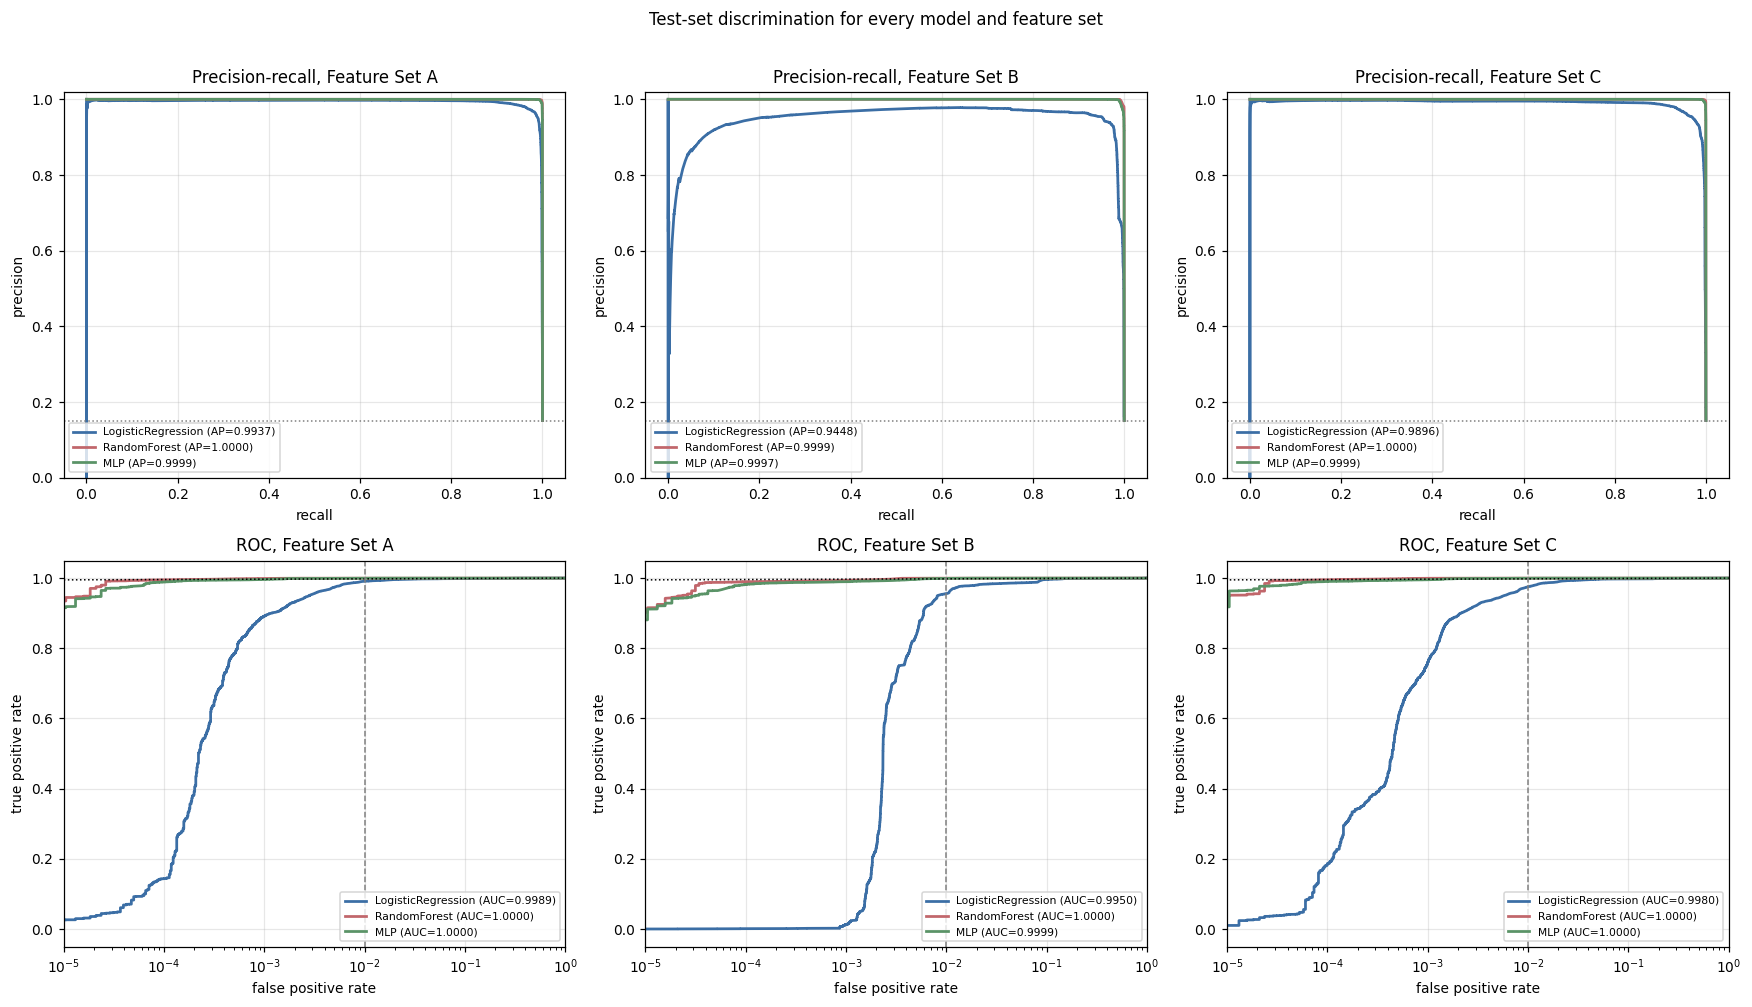

[figure] fig01_pr_roc_curves.png + .pdf   ->  Results - RQ1 discrimination


In [ ]:
# --- F01: precision-recall and ROC curves -----------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for j, fs in enumerate(["A", "B", "C"]):
    for mn in MODEL_ORDER:
        if (mn, fs) not in PROBS:
            continue
        pt = PROBS[(mn, fs)]
        pr, rc, _ = precision_recall_curve(Y["test"], pt)
        ap = average_precision_score(Y["test"], pt)
        axes[0, j].plot(rc, pr, color=COLORS[mn], lw=1.8, label=f"{mn} (AP={ap:.4f})")
        fpr, tpr, _ = roc_curve(Y["test"], pt)
        au = roc_auc_score(Y["test"], pt)
        axes[1, j].plot(fpr, tpr, color=COLORS[mn], lw=1.8, label=f"{mn} (AUC={au:.4f})")
    axes[0, j].set(title=f"Precision-recall, Feature Set {fs}", xlabel="recall",
                   ylabel="precision", ylim=(0, 1.02))
    axes[0, j].axhline(Y["test"].mean(), ls=":", c="grey", lw=1)
    axes[0, j].legend(fontsize=7, loc="lower left")
    axes[1, j].plot([0, 1], [0, 1], "k:", lw=1)
    axes[1, j].axvline(CFG["fpr_budget"], ls="--", c="grey", lw=1)
    axes[1, j].set(title=f"ROC, Feature Set {fs}", xlabel="false positive rate",
                   ylabel="true positive rate", xscale="log", xlim=(1e-5, 1))
    axes[1, j].legend(fontsize=7, loc="lower right")
fig.suptitle("Test-set discrimination for every model and feature set", y=1.01)
fig.tight_layout()
savefig(fig, "fig01_pr_roc_curves",
        "Precision-recall and ROC curves on the CIC-IDS2017 test partition for all nine "
        "model and feature-set combinations. The dotted horizontal line marks the attack "
        "base rate and the dashed vertical line marks the one per cent false-positive "
        "budget used for the operating point.",
        "Results - RQ1 discrimination")

Precision-recall is shown above ROC because the class prior makes ROC look flattering at this level of imbalance.  
The ROC axis is logarithmic so the behaviour in the low false-positive region that operations actually cares about is visible.  
The dotted line is the attack base rate, which is the precision a random detector would achieve.

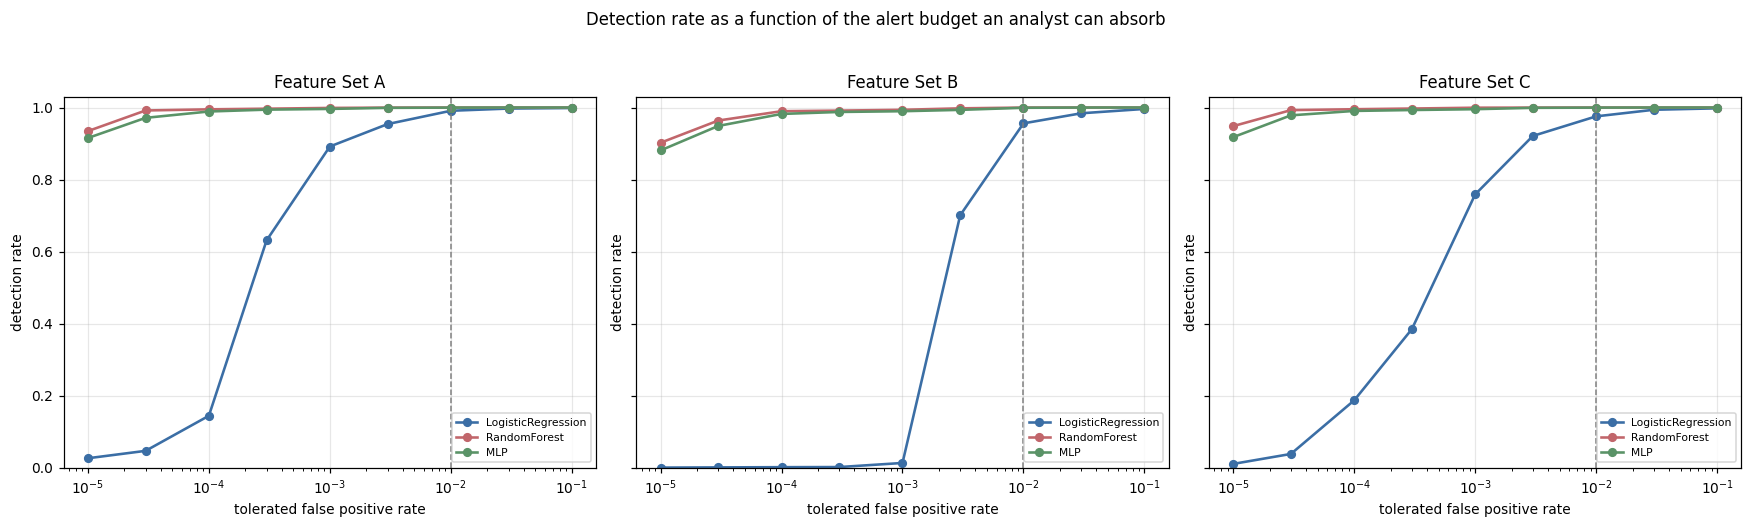

[figure] fig02_detection_vs_budget.png + .pdf   ->  Evaluation - operational trade-off


In [ ]:
# --- F02: detection rate across the whole alert budget ----------------------
budgets = np.array([1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, fs in zip(axes, ["A", "B", "C"]):
    for mn in MODEL_ORDER:
        if (mn, fs) not in PROBS:
            continue
        fpr, tpr, _ = roc_curve(Y["test"], PROBS[(mn, fs)])
        ax.plot(budgets, np.interp(budgets, fpr, tpr), "o-", color=COLORS[mn], lw=1.7,
                ms=5, label=mn)
    ax.axvline(CFG["fpr_budget"], ls="--", c="grey", lw=1)
    ax.set(xscale="log", ylim=(0, 1.03), title=f"Feature Set {fs}",
           xlabel="tolerated false positive rate", ylabel="detection rate")
    ax.legend(fontsize=7, loc="lower right")
fig.suptitle("Detection rate as a function of the alert budget an analyst can absorb", y=1.03)
fig.tight_layout()
savefig(fig, "fig02_detection_vs_budget",
        "Detection rate achieved at false-positive budgets from 0.001 to 10 per cent. The "
        "dashed line marks the one per cent operating point used throughout the results. "
        "Reporting the whole curve avoids over-claiming from a single arbitrary threshold.",
        "Evaluation - operational trade-off")

A security team with more analysts can absorb more false alarms, so one operating point is a poor summary.  
The curve shows how much detection is bought by each relaxation of the alert budget.  
The dashed line is the budget used for every headline number in the results chapter.

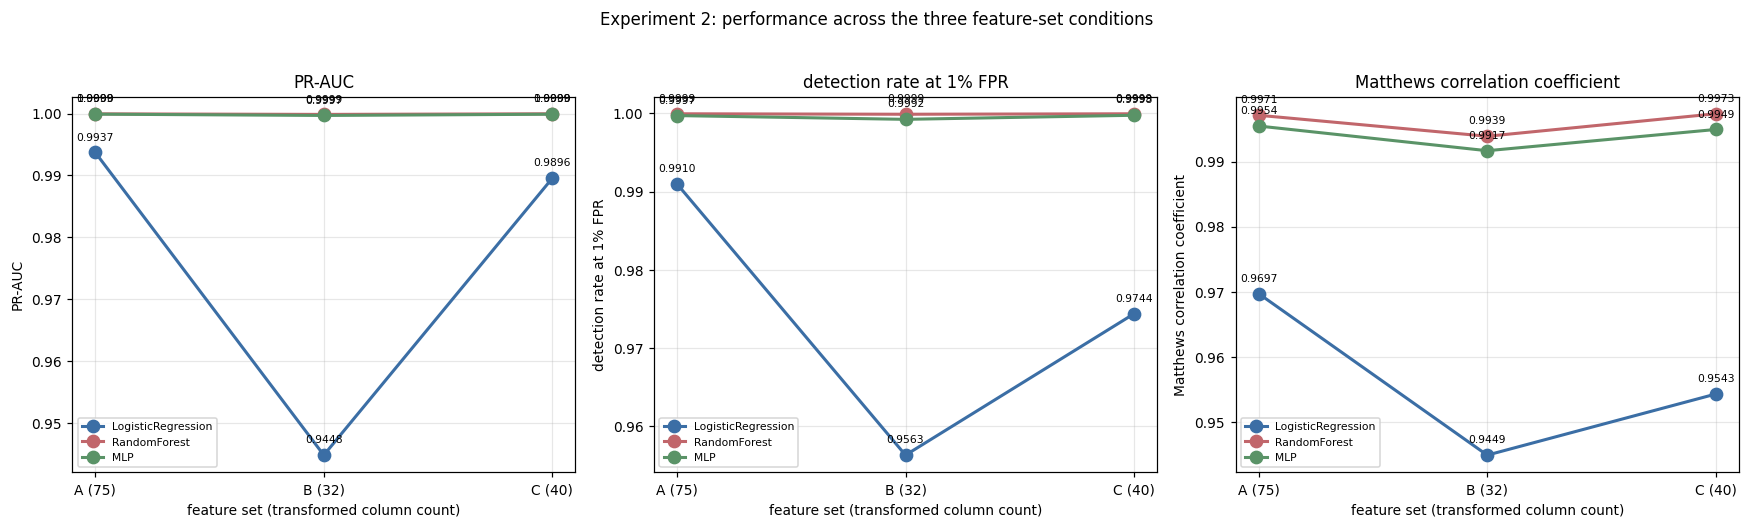

[figure] fig03_feature_set_degradation.png + .pdf   ->  Results - RQ1 feature sets


In [ ]:
# --- F03: cost of feature reduction ----------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
xs = np.arange(3)
for ax, (col, lbl) in zip(axes, [("pr_auc", "PR-AUC"),
                                 ("fpr1_recall", "detection rate at 1% FPR"),
                                 ("f1_mcc", "Matthews correlation coefficient")]):
    for mn in MODEL_ORDER:
        v = [float(RES2[(RES2.model == mn) & (RES2.feature_set == f)][col].iloc[0])
             if len(RES2[(RES2.model == mn) & (RES2.feature_set == f)]) else np.nan
             for f in ["A", "B", "C"]]
        ax.plot(xs, v, "o-", color=COLORS[mn], lw=2, ms=8, label=mn)
        for x, y_ in zip(xs, v):
            if not np.isnan(y_):
                ax.annotate(f"{y_:.4f}", (x, y_), textcoords="offset points",
                            xytext=(0, 8), ha="center", fontsize=7)
    ax.set(xticks=xs, ylabel=lbl, title=lbl)
    ax.set_xticklabels([f"A ({nA})", f"B ({nB})", f"C ({nC})"])
    ax.set_xlabel("feature set (transformed column count)")
    ax.legend(fontsize=7)
fig.suptitle("Experiment 2: performance across the three feature-set conditions", y=1.03)
fig.tight_layout()
savefig(fig, "fig03_feature_set_degradation",
        "Performance of each model across Feature Set A (all available features), Feature "
        "Set B (the harmonised cross-dataset subset) and Feature Set C (the reduced set "
        "selected on training data only). Column counts are given in brackets.",
        "Results - RQ1 feature sets")

This is the direct visual answer to Experiment 2, showing what each model loses as the feature space shrinks.  
The ensemble is almost unaffected by reduction while the linear model is the most sensitive, which is the interesting part of the comparison.  
Column counts are printed on the axis so an accuracy loss can be weighed against the collection cost saved.

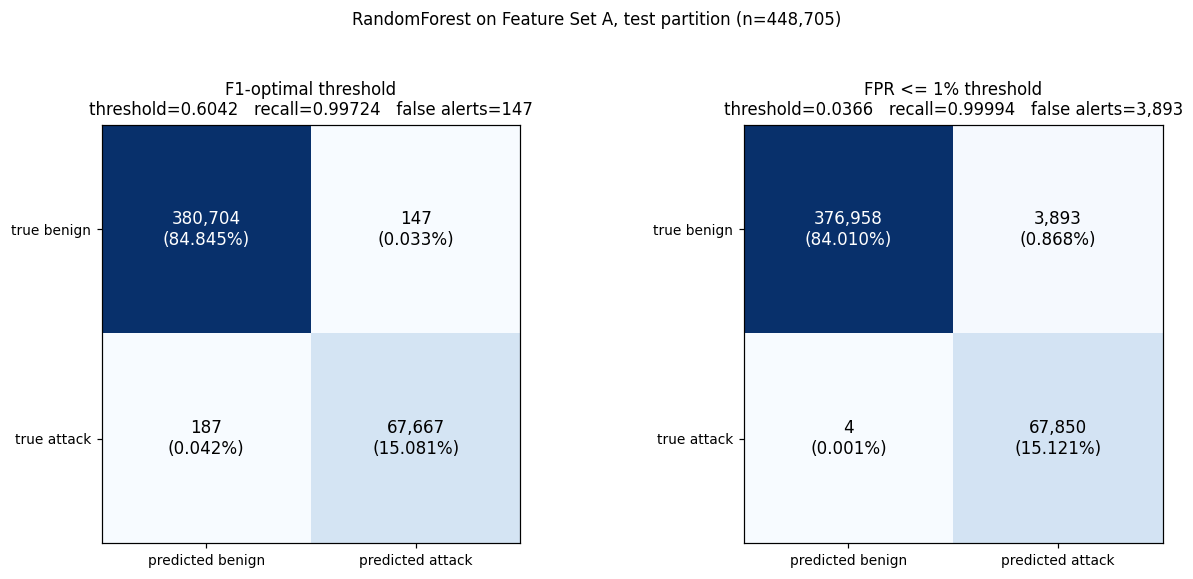

[figure] fig04_confusion_matrices.png + .pdf   ->  Results - RQ1 error analysis


In [ ]:
# --- F04: confusion matrices for the best configuration ---------------------
b = RES2.sort_values("fpr1_recall", ascending=False).iloc[0]
pt = PROBS[(b.model, b.feature_set)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (tag, t) in zip(axes, [("F1-optimal threshold", b.f1_threshold),
                               (f"FPR <= {100*CFG['fpr_budget']:.0f}% threshold",
                                b.fpr1_threshold)]):
    cm = confusion_matrix(Y["test"], (pt >= t).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    for (r_, c_), v in np.ndenumerate(cm):
        ax.text(c_, r_, f"{v:,}\n({100*v/cm.sum():.3f}%)", ha="center", va="center",
                fontsize=11, color="white" if v > cm.max() / 2 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1])
    ax.set_xticklabels(["predicted benign", "predicted attack"])
    ax.set_yticklabels(["true benign", "true attack"])
    ax.set_title(f"{tag}\nthreshold={t:.4f}   recall={cm[1,1]/max(cm[1].sum(),1):.5f}   "
                 f"false alerts={cm[0,1]:,}")
    ax.grid(False)
fig.suptitle(f"{b.model} on Feature Set {b.feature_set}, test partition "
             f"(n={len(Y['test']):,})", y=1.04)
fig.tight_layout()
savefig(fig, "fig04_confusion_matrices",
        "Confusion matrices for the best configuration at the two validation-selected "
        "thresholds. The left panel maximises F1 and the right panel constrains the "
        "false-positive rate to one per cent, making the detection versus false-alarm "
        "trade-off explicit in absolute counts.",
        "Results - RQ1 error analysis")

Counts matter more than rates here because an analyst triages individual alerts, not percentages.  
The two panels show the same model under two defensible threshold policies chosen on validation.  
The difference between the panels is precisely the trade-off named in research question one.

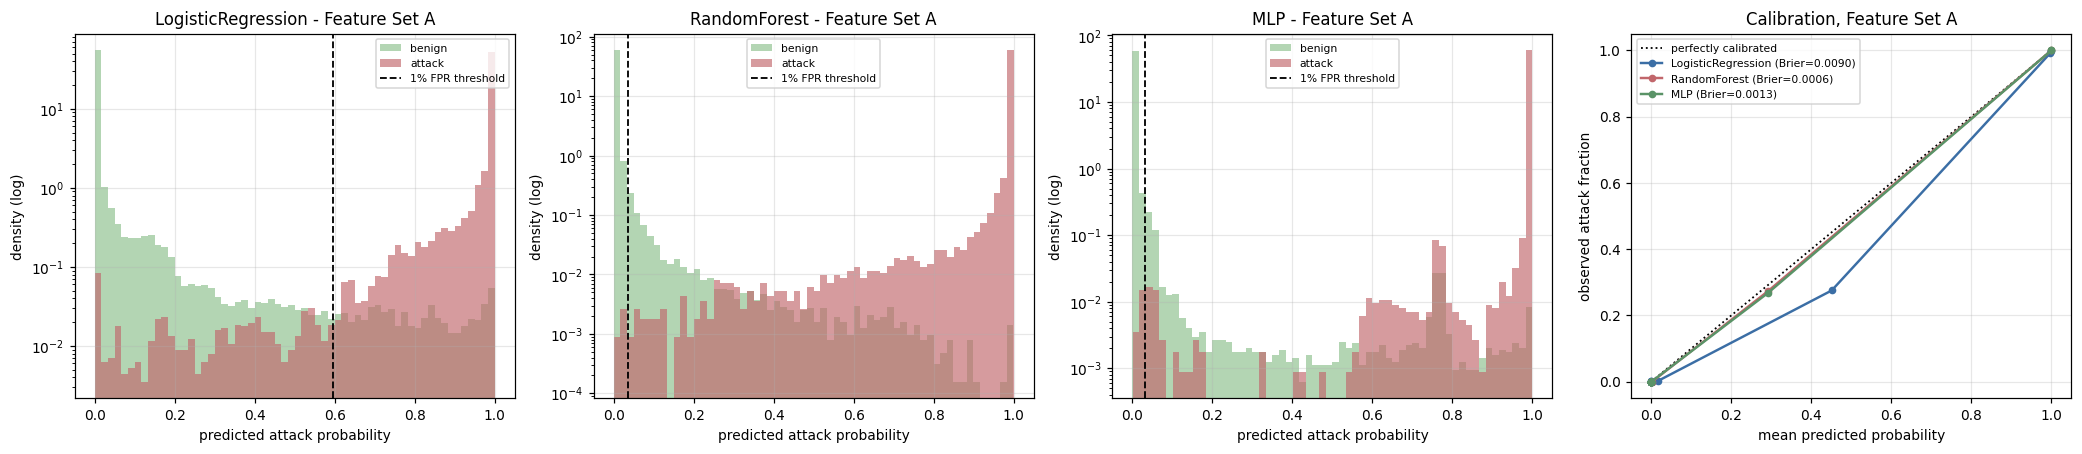

[figure] fig05_score_separation_calibration.png + .pdf   ->  Results - RQ1 diagnostics


In [ ]:
# --- F05: score separation and calibration ---------------------------------
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, mn in zip(axes[:3], MODEL_ORDER):
    if (mn, "A") not in PROBS:
        continue
    pt = PROBS[(mn, "A")]
    ax.hist(pt[Y["test"] == 0], bins=60, alpha=.65, density=True, label="benign",
            color="#8bbf8b")
    ax.hist(pt[Y["test"] == 1], bins=60, alpha=.65, density=True, label="attack",
            color="#c1666b")
    r_ = RES2[(RES2.model == mn) & (RES2.feature_set == "A")]
    if len(r_):
        ax.axvline(float(r_.fpr1_threshold.iloc[0]), ls="--", c="black", lw=1.2,
                   label="1% FPR threshold")
    ax.set(yscale="log", title=f"{mn} - Feature Set A",
           xlabel="predicted attack probability", ylabel="density (log)")
    ax.legend(fontsize=7)
ax = axes[3]
ax.plot([0, 1], [0, 1], "k:", lw=1.2, label="perfectly calibrated")
for mn in MODEL_ORDER:
    if (mn, "A") not in PROBS:
        continue
    pt = PROBS[(mn, "A")]
    frac, meanp = calibration_curve(Y["test"], pt, n_bins=15, strategy="quantile")
    brier = float(np.mean((pt - Y["test"]) ** 2))
    ax.plot(meanp, frac, "o-", color=COLORS[mn], lw=1.6, ms=4,
            label=f"{mn} (Brier={brier:.4f})")
ax.set(xlabel="mean predicted probability", ylabel="observed attack fraction",
       title="Calibration, Feature Set A")
ax.legend(fontsize=7)
fig.tight_layout()
savefig(fig, "fig05_score_separation_calibration",
        "Predicted-probability distributions for benign and attack flows on the test "
        "partition, with the one per cent false-positive threshold marked, alongside a "
        "reliability diagram with Brier scores. Overlap between the distributions bounds "
        "the achievable detection rate, and deviation from the diagonal indicates "
        "miscalibration when alerts are ranked by predicted risk.",
        "Results - RQ1 diagnostics")

Overlap between the two score distributions is the ceiling on what any threshold can achieve for that model.  
The fourth panel checks whether the predicted probabilities can be read as risk, which matters if alerts are triaged by score.  
The Brier score summarises calibration quality in one number for the discussion.

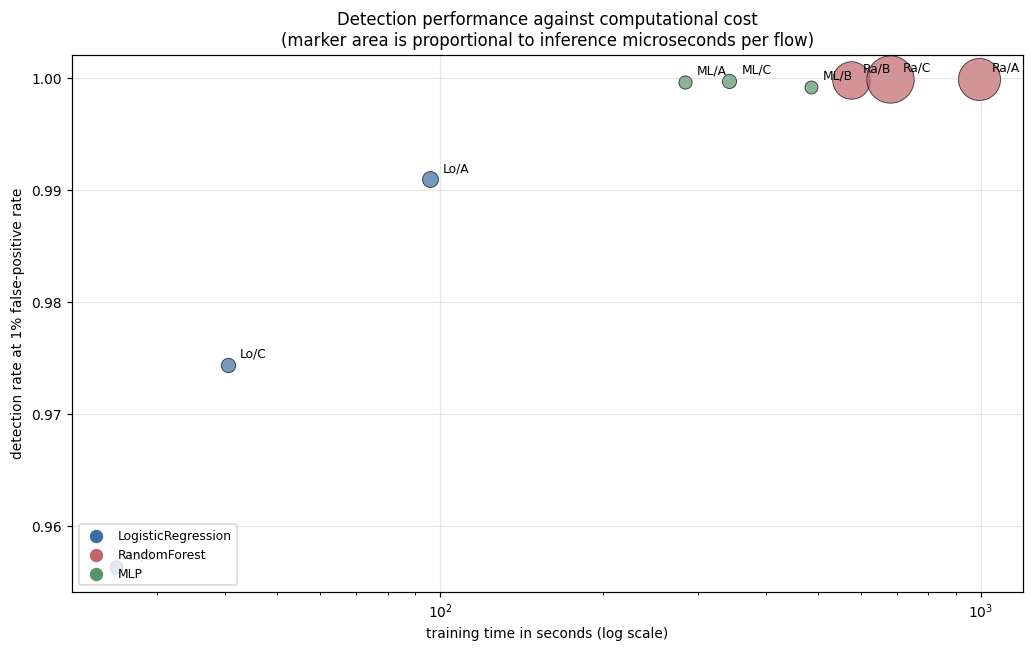

[figure] fig06_accuracy_vs_cost.png + .pdf   ->  Evaluation - computational cost


In [ ]:
# --- F06: accuracy against computational cost ------------------------------
fig, ax = plt.subplots(figsize=(9.5, 6))
for mn in MODEL_ORDER:
    for fs in ["A", "B", "C"]:
        r_ = RES2[(RES2.model == mn) & (RES2.feature_set == fs)]
        if not len(r_):
            continue
        r_ = r_.iloc[0]
        ax.scatter(r_.fit_seconds, r_.fpr1_recall, color=COLORS[mn], alpha=.7,
                   s=60 + 900 * r_.infer_us_per_flow / max(RES2.infer_us_per_flow.max(), 1e-9),
                   edgecolor="black", linewidth=.6)
        ax.annotate(f"{mn[:2]}/{fs}", (r_.fit_seconds, r_.fpr1_recall),
                    textcoords="offset points", xytext=(8, 5), fontsize=8)
for mn in MODEL_ORDER:
    ax.scatter([], [], color=COLORS[mn], label=mn, s=60)
ax.set(xscale="log", xlabel="training time in seconds (log scale)",
       ylabel="detection rate at 1% false-positive rate",
       title="Detection performance against computational cost\n"
             "(marker area is proportional to inference microseconds per flow)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
savefig(fig, "fig06_accuracy_vs_cost",
        "Detection rate at the one per cent false-positive budget plotted against training "
        "time for all nine configurations, with marker area proportional to inference cost "
        "per flow. Configurations toward the upper left deliver the most detection per unit "
        "of computation.",
        "Evaluation - computational cost")

The proposal requires computational cost as a secondary criterion, and this figure reports it against detection rather than in isolation.  
Marker area encodes inference cost, so training cost, inference cost and detection are all visible at once.  
A configuration that is only marginally better but an order of magnitude slower is easy to identify here.

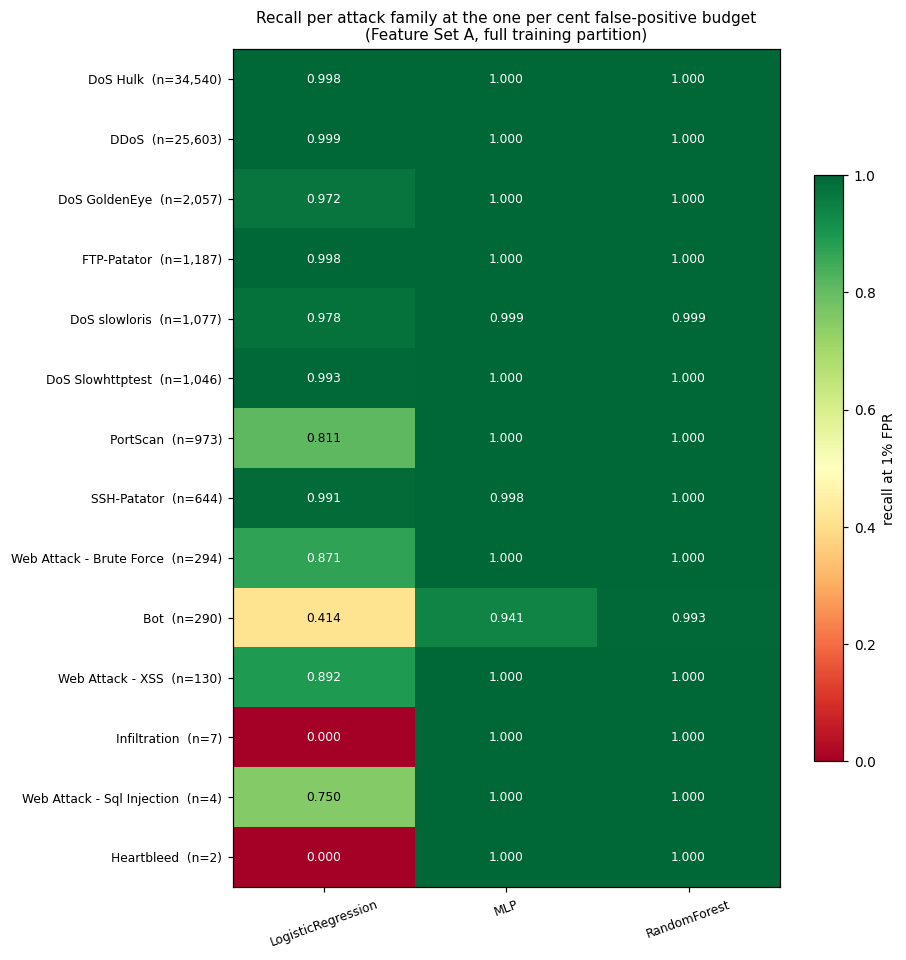

[figure] fig07_per_family_recall.png + .pdf   ->  Results - RQ1 per-class analysis


In [ ]:
# --- F07: per-family recall heatmap ----------------------------------------
mat = PIV.drop(columns="support")
fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(mat) + 2.5))
im = ax.imshow(mat.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns, rotation=20, fontsize=8)
ax.set_yticks(range(len(mat)))
ax.set_yticklabels([f"{i}  (n={int(PIV.loc[i,'support']):,})" for i in mat.index], fontsize=8)
for (r_, c_), v in np.ndenumerate(mat.values):
    ax.text(c_, r_, f"{v:.3f}", ha="center", va="center", fontsize=8,
            color="black" if 0.25 < v < 0.85 else "white")
fig.colorbar(im, shrink=.7, label="recall at 1% FPR")
ax.set_title("Recall per attack family at the one per cent false-positive budget\n"
             "(Feature Set A, full training partition)", fontsize=10)
ax.grid(False)
fig.tight_layout()
savefig(fig, "fig07_per_family_recall",
        "Recall for each individual attack family at a one per cent false-positive budget, "
        "with test-set support shown beside each family name. Low-support families are "
        "detected far less reliably than the aggregate scores suggest.",
        "Results - RQ1 per-class analysis")

The heatmap makes the gap between headline recall and rare-family recall impossible to overlook.  
Support counts are printed with each family so a low score on a class of eleven flows is read with appropriate caution.  
Families in the red band are the concrete limitation to cite in the evaluation chapter.

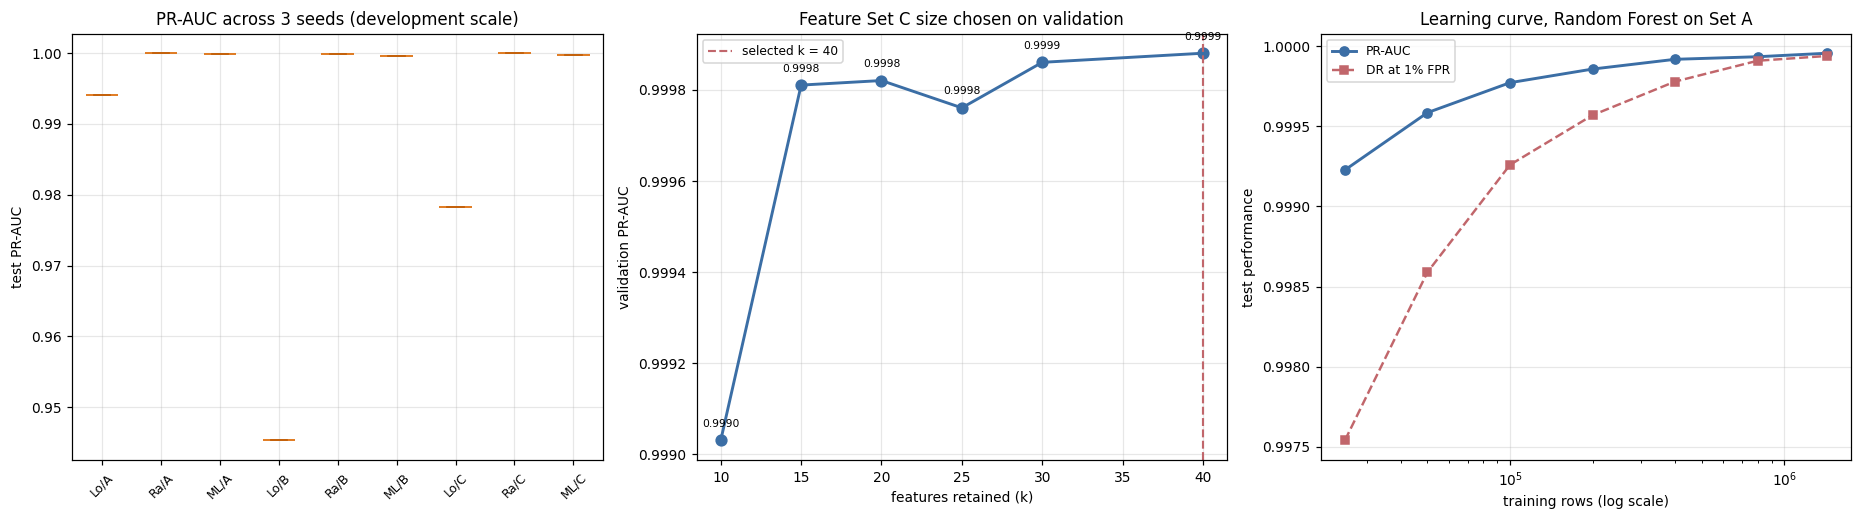

[figure] fig08_variance_selection_learning.png + .pdf   ->  Methodology - experimental controls


In [ ]:
# --- F08: seed variability, feature selection and learning curve ------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
groups, labels, cols_ = [], [], []
for fs in ["A", "B", "C"]:
    for mn in MODEL_ORDER:
        g = S1[(S1.model == mn) & (S1.feature_set == fs)]["pr_auc"].to_numpy()
        if len(g):
            groups.append(g); labels.append(f"{mn[:2]}/{fs}"); cols_.append(COLORS[mn])
bp = axes[0].boxplot(groups, patch_artist=True, widths=.55)
axes[0].set_xticklabels(labels, rotation=45, fontsize=8)
for patch, c in zip(bp["boxes"], cols_):
    patch.set_facecolor(c); patch.set_alpha(.65)
axes[0].set(title=f"PR-AUC across {len(CFG['seeds'])} seeds (development scale)",
            ylabel="test PR-AUC")

axes[1].plot(SW.k, SW.val_pr_auc, "o-", color="#3b6ea5", lw=1.9, ms=7)
axes[1].axvline(BEST_K, ls="--", c="#c1666b", lw=1.4, label=f"selected k = {BEST_K}")
for _, r_ in SW.iterrows():
    axes[1].annotate(f"{r_.val_pr_auc:.4f}", (r_.k, r_.val_pr_auc),
                     textcoords="offset points", xytext=(0, 9), ha="center", fontsize=7)
axes[1].set(xlabel="features retained (k)", ylabel="validation PR-AUC",
            title="Feature Set C size chosen on validation")
axes[1].legend(fontsize=8)

axes[2].plot(LC.n_train, LC.pr_auc, "o-", color="#3b6ea5", lw=1.9, ms=6, label="PR-AUC")
axes[2].plot(LC.n_train, LC.dr_at_1pct_fpr, "s--", color="#c1666b", lw=1.6, ms=5,
             label="DR at 1% FPR")
axes[2].set(xscale="log", xlabel="training rows (log scale)", ylabel="test performance",
            title="Learning curve, Random Forest on Set A")
axes[2].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "fig08_variance_selection_learning",
        "Left: distribution of test PR-AUC across random seeds at development scale, "
        "defining the threshold below which differences are not meaningful. Centre: "
        "validation PR-AUC against the number of features retained, with the selected "
        "cut-off marked. Right: test performance against the number of training rows.",
        "Methodology - experimental controls")

These three panels are the experimental controls the proposal commits to, gathered into one figure.  
The spread on the left is what makes the significance testing above necessary rather than decorative.  
The flat right-hand tail shows the benchmark saturates well before the full training partition is used.

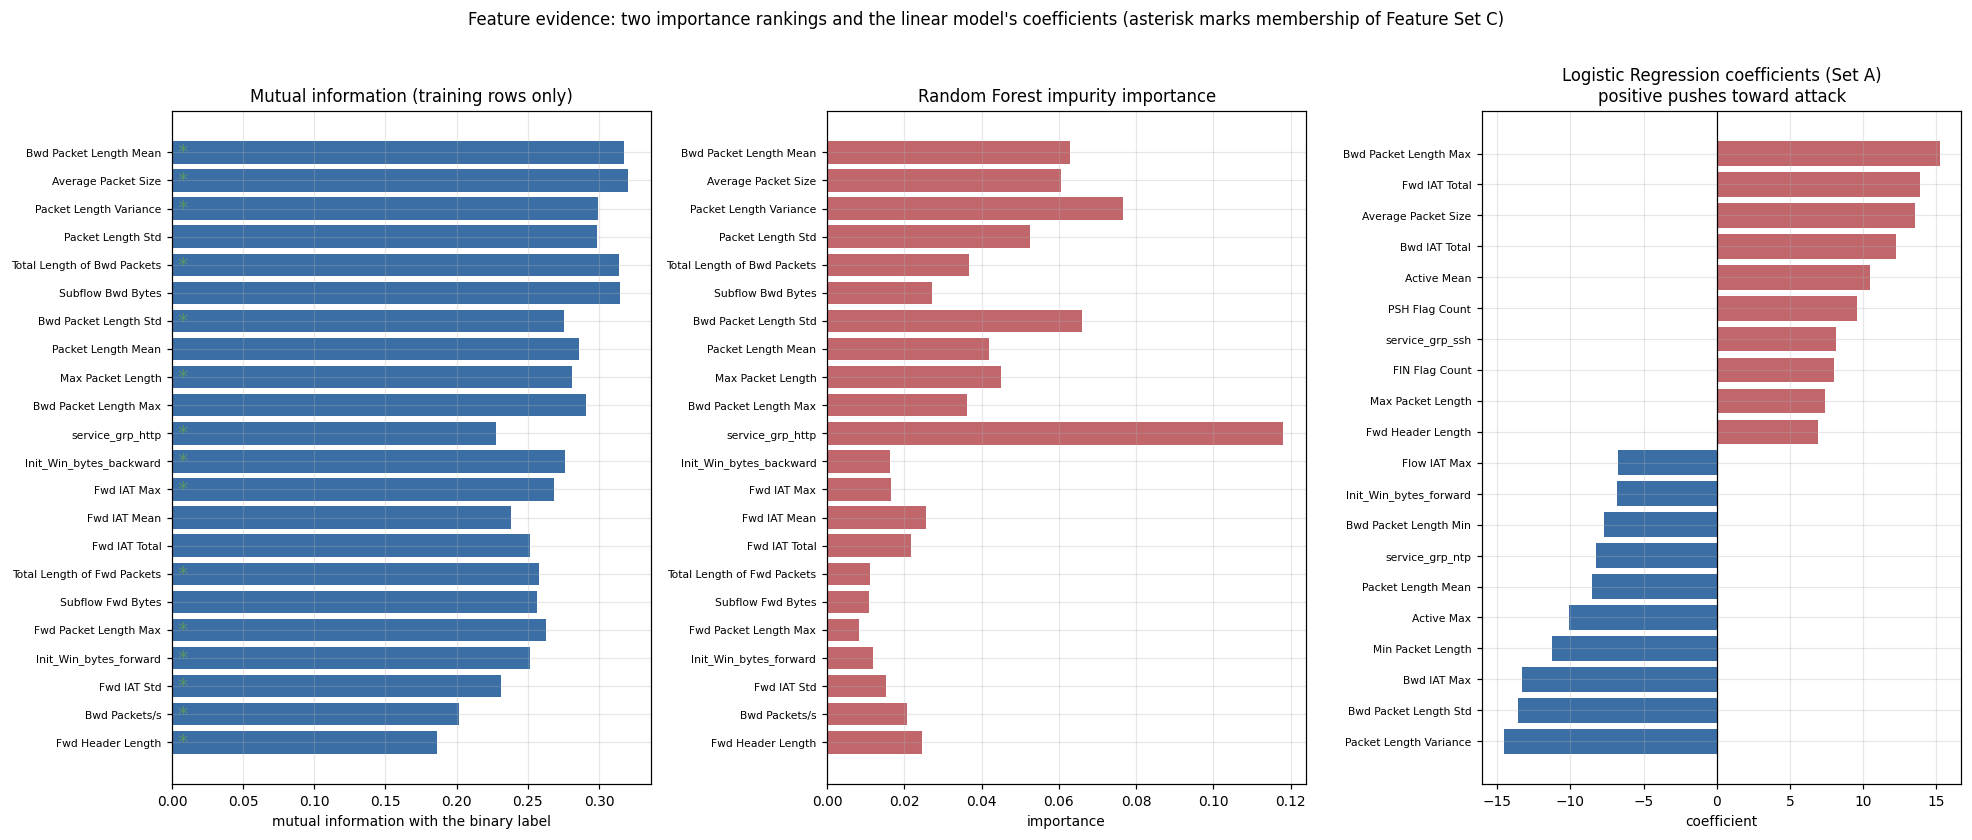

[figure] fig09_feature_evidence.png + .pdf   ->  Results - feature analysis


In [ ]:
# --- F09: what the models learned ------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 7.5))
top = RANK.head(22).iloc[::-1]
axes[0].barh(range(len(top)), top.mutual_info, color="#3b6ea5")
axes[0].set(yticks=range(len(top)), title="Mutual information (training rows only)",
            xlabel="mutual information with the binary label")
axes[0].set_yticklabels([t[:32] for t in top.feature], fontsize=7)
axes[1].barh(range(len(top)), top.rf_importance, color="#c1666b")
axes[1].set(yticks=range(len(top)), title="Random Forest impurity importance",
            xlabel="importance")
axes[1].set_yticklabels([t[:32] for t in top.feature], fontsize=7)
for i, f in enumerate(top.feature):
    if f in FSC_NAMES:
        axes[0].text(0, i, " *", va="center", ha="left", fontsize=13, color="#5a9367")
if "A" in LR_COEF:
    co = pd.Series(LR_COEF["A"], index=NAMES_A).sort_values()
    sel = pd.concat([co.head(10), co.tail(10)])
    axes[2].barh(range(len(sel)), sel.values,
                 color=["#c1666b" if v > 0 else "#3b6ea5" for v in sel.values])
    axes[2].set(yticks=range(len(sel)),
                title="Logistic Regression coefficients (Set A)\npositive pushes toward attack",
                xlabel="coefficient")
    axes[2].set_yticklabels([t[:32] for t in sel.index], fontsize=7)
    axes[2].axvline(0, c="black", lw=.8)
fig.suptitle("Feature evidence: two importance rankings and the linear model's coefficients "
             "(asterisk marks membership of Feature Set C)", y=1.01)
fig.tight_layout()
savefig(fig, "fig09_feature_evidence",
        "The highest-ranked features under mutual information and Random Forest impurity "
        "importance, both computed on the training partition only, alongside the largest "
        "positive and negative Logistic Regression coefficients. Asterisks mark features "
        "retained in Feature Set C after correlation pruning.",
        "Results - feature analysis")

Two independent rankings plus the linear coefficients give three views of which traffic properties carry the signal.  
The coefficient panel is the interpretable evidence the proposal asks for, since a forest cannot supply it directly.  
Packet-length and window-size features dominating all three views is the substantive finding to discuss.

---
# 3. Dataset validity — how much of the score is a testbed artefact?

Notebook 01 measured `sttl` at single-feature AUC 0.9905 and `ct_state_ttl` at 0.9912 on
UNSW-NB15. One integer almost solves the dataset, because the IXIA generator emitted a
near-fixed time-to-live for attack traffic. Notebook 02 excluded all three TTL-derived columns
from Feature Set B but deliberately kept them in UNSW's Feature Set A so the effect could be
measured here.

This puts a number on how much of a published-looking score comes from an artefact of the
capture environment rather than from learnable signal, and it explains in advance why the
transfer results in Section 5 cannot reproduce it.

In [ ]:
# --- UNSW-NB15 TTL artefact ablation ---------------------------------------
du, spu = FRAMES["unsw"], SPLITS["unsw"]
preU = PREPROC[("unsw", "A")]
yu = du["y"].to_numpy().astype(np.int8)
YU = {p: yu[spu[p]] for p in ["train", "val", "test"]}
YU_FINE = {p: du["y_fine"].astype(str).to_numpy()[spu[p]] for p in ["val", "test"]}

t0 = time.time()
XU = {p: transform_block(preU, du, FSA["unsw"], CATS["unsw"], spu[p])
      for p in ["train", "val", "test"]}
NU = names_of(preU, FSA["unsw"], CATS["unsw"], XU["train"].shape[1])
art = [i for i, n in enumerate(NU) if n in UNSW_ARTEFACTS]
keep_i = [i for i in range(len(NU)) if i not in art]
print(f"UNSW matrices built in {time.time()-t0:.0f}s -> {XU['train'].shape}")
print(f"attack rate {100*YU['train'].mean():.3f}% (1:{(1-YU['train'].mean())/YU['train'].mean():.1f})")
print(f"artefact columns removed in the ablation: {[NU[i] for i in art]}")

ab_n = min(CFG["ablation_rows"], len(YU["train"]))
ab_i = np.sort(np.random.default_rng(SEED).choice(len(YU["train"]), ab_n, replace=False))
ABL = []
for tag, cols in [("with_artefacts", list(range(len(NU)))), ("without_artefacts", keep_i)]:
    for mn in ["RandomForest", "LogisticRegression", "MLP"]:
        key = f"abl_{tag}_{mn}"
        def _f(tag=tag, cols=cols, mn=mn):
            Xtr = XU["train"][np.ix_(ab_i, cols)]
            Xva, Xte = XU["val"][:, cols], XU["test"][:, cols]
            if mn == "MLP":
                _, pv, pt, f_s, i_s, ex = run_mlp(Xtr, YU["train"][ab_i], Xva, YU["val"], Xte)
            elif mn == "RandomForest":
                _, pv, pt, f_s, i_s, ex = run_rf(Xtr, YU["train"][ab_i], Xva, Xte)
            else:
                _, pv, pt, f_s, i_s, ex = run_lr(Xtr, YU["train"][ab_i], Xva, Xte)
            return evaluate(mn, tag, YU["val"], pv, YU["test"], pt, f_s, i_s,
                            len(YU["test"]), extra=ex), pv, pt
        r_, pv, pt = run_config(key, _f)
        r_["probs_key"] = key
        ABL.append(r_)
        print(f"  {mn:18s} {tag:18s} PR-AUC={r_['pr_auc']:.5f}  ROC-AUC={r_['roc_auc']:.5f}  "
              f"DR@1%FPR={r_['fpr1_recall']:.5f}")
        gc.collect()

ABLD = pd.DataFrame(ABL)
display(ABLD[["model", "feature_set", "roc_auc", "pr_auc", "fpr1_recall", "fpr1_precision",
              "f1_f1", "f1_mcc"]].round(5))
ABLD.to_csv(RES / "unsw_artefact_ablation.csv", index=False)
print("\nCost of removing three time-to-live derived columns:")
for m in ABLD.model.unique():
    w = ABLD[(ABLD.model == m) & (ABLD.feature_set == "with_artefacts")].iloc[0]
    o = ABLD[(ABLD.model == m) & (ABLD.feature_set == "without_artefacts")].iloc[0]
    print(f"  {m:18s} PR-AUC {w.pr_auc:.5f} -> {o.pr_auc:.5f} "
          f"({100*(o.pr_auc-w.pr_auc)/max(w.pr_auc,1e-9):+.1f}%)   "
          f"DR@1%FPR {w.fpr1_recall:.5f} -> {o.fpr1_recall:.5f}")
M["results"]["unsw_ablation"] = ABLD.to_dict("records")

UNSW matrices built in 8s -> (1290632, 63)
attack rate 3.869% (1:24.8)
artefact columns removed in the ablation: ['sttl', 'dttl', 'ct_state_ttl']
  RandomForest       with_artefacts     PR-AUC=0.97475  ROC-AUC=0.99891  DR@1%FPR=0.97693
  LogisticRegression with_artefacts     PR-AUC=0.91344  ROC-AUC=0.99720  DR@1%FPR=0.94918
  MLP                with_artefacts     PR-AUC=0.96550  ROC-AUC=0.99847  DR@1%FPR=0.96514
  RandomForest       without_artefacts  PR-AUC=0.97095  ROC-AUC=0.99879  DR@1%FPR=0.97276
  LogisticRegression without_artefacts  PR-AUC=0.74002  ROC-AUC=0.99129  DR@1%FPR=0.67489
  MLP                without_artefacts  PR-AUC=0.96117  ROC-AUC=0.99827  DR@1%FPR=0.95655


,model,feature_set,roc_auc,pr_auc,fpr1_recall,fpr1_precision,f1_f1,f1_mcc
0,RandomForest,with_artefacts,0.99891,0.97475,0.97693,0.79749,0.90433,0.90051
1,LogisticRegression,with_artefacts,0.99720,0.91344,0.94918,0.79467,0.87039,0.86553
2,MLP,with_artefacts,0.99847,0.96550,0.96514,0.79573,0.88748,0.88333
3,RandomForest,without_artefacts,0.99879,0.97095,0.97276,0.79621,0.89818,0.89407
4,LogisticRegression,without_artefacts,0.99129,0.74002,0.67489,0.73628,0.77622,0.78442
5,MLP,without_artefacts,0.99827,0.96117,0.95655,0.79504,0.87821,0.87389



Cost of removing three time-to-live derived columns:
  RandomForest       PR-AUC 0.97475 -> 0.97095 (-0.4%)   DR@1%FPR 0.97693 -> 0.97276
  LogisticRegression PR-AUC 0.91344 -> 0.74002 (-19.0%)   DR@1%FPR 0.94918 -> 0.67489
  MLP                PR-AUC 0.96550 -> 0.96117 (-0.4%)   DR@1%FPR 0.96514 -> 0.95655


The same models are trained twice on identical rows, differing only in whether the three TTL-derived columns are present.  
The gap between the two runs is the share of apparent UNSW performance that comes from the traffic generator rather than from network behaviour.  
Because those columns are excluded from Feature Set B, this number predicts in advance why the transfer experiments cannot match within-dataset scores.

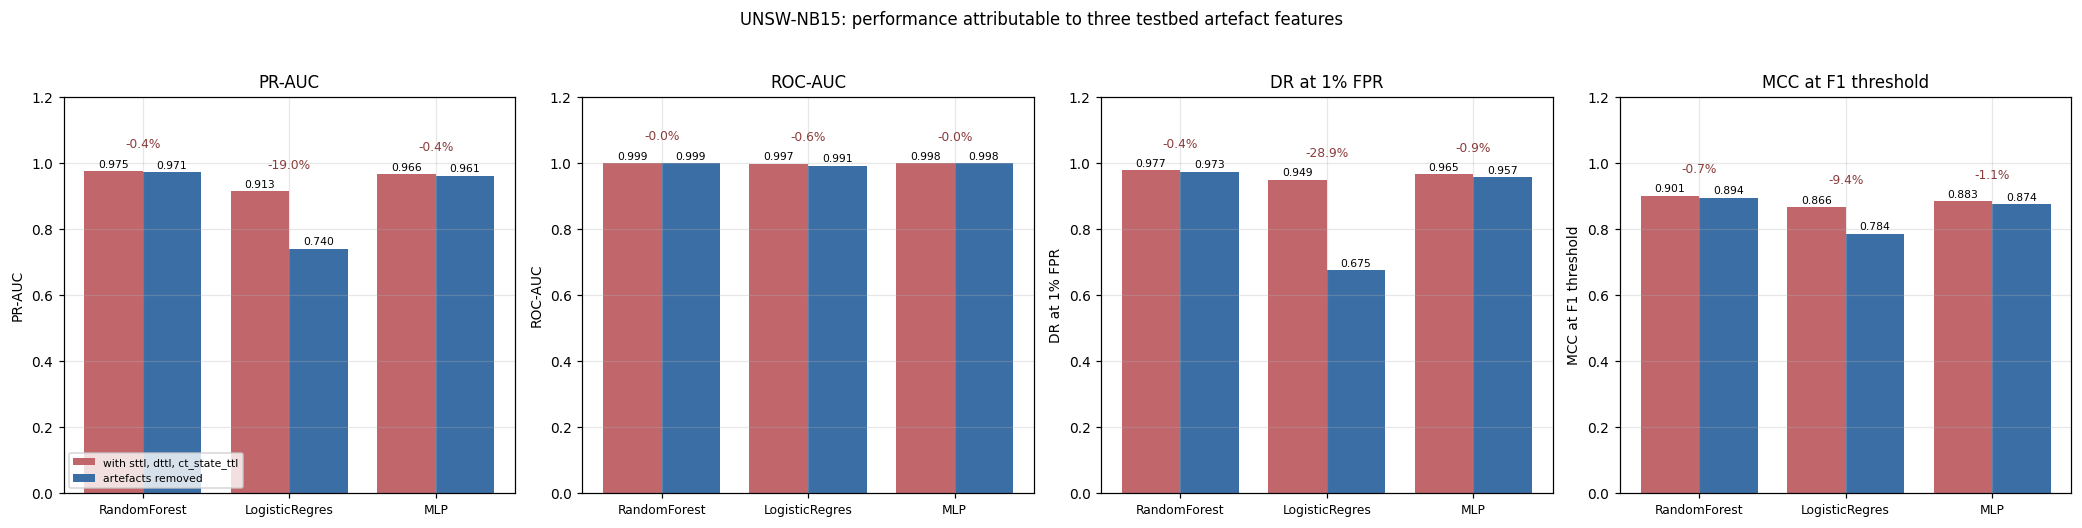

[figure] fig10_unsw_artefact_ablation.png + .pdf   ->  Evaluation - dataset validity


In [ ]:
# --- F10: the artefact ablation --------------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
mods = list(ABLD.model.unique()); xs = np.arange(len(mods))
for ax, (col, lbl) in zip(axes, [("pr_auc", "PR-AUC"), ("roc_auc", "ROC-AUC"),
                                 ("fpr1_recall", "DR at 1% FPR"),
                                 ("f1_mcc", "MCC at F1 threshold")]):
    w = [float(ABLD[(ABLD.model == m) & (ABLD.feature_set == "with_artefacts")][col].iloc[0])
         for m in mods]
    o = [float(ABLD[(ABLD.model == m) & (ABLD.feature_set == "without_artefacts")][col].iloc[0])
         for m in mods]
    ax.bar(xs - .2, w, .4, label="with sttl, dttl, ct_state_ttl", color="#c1666b")
    ax.bar(xs + .2, o, .4, label="artefacts removed", color="#3b6ea5")
    for x, (a_, b_) in enumerate(zip(w, o)):
        ax.text(x - .2, a_ + .012, f"{a_:.3f}", ha="center", fontsize=7)
        ax.text(x + .2, b_ + .012, f"{b_:.3f}", ha="center", fontsize=7)
        ax.annotate(f"{100*(b_-a_)/max(a_,1e-9):+.1f}%", (x, max(a_, b_) + .07), ha="center",
                    fontsize=8, color="#8a3b3b")
    ax.set(xticks=xs, ylim=(0, 1.2), title=lbl, ylabel=lbl)
    ax.set_xticklabels([m[:14] for m in mods], fontsize=8)
axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("UNSW-NB15: performance attributable to three testbed artefact features", y=1.03)
fig.tight_layout()
savefig(fig, "fig10_unsw_artefact_ablation",
        "Effect of removing the three time-to-live derived features from UNSW-NB15. The "
        "traffic generator emitted a near-constant TTL for attack traffic, so these columns "
        "separate the classes almost perfectly within the dataset while carrying no "
        "transferable signal.",
        "Evaluation - dataset validity")

Four metrics are shown together because ROC-AUC hides the artefact effect far more than PR-AUC does at this imbalance.  
The percentage annotation above each pair is the headline number for the dataset-validity discussion.  
Any published UNSW result that keeps these columns is measuring the generator as much as the detector.

---
# 4. Unseen-attack generalisation on the primary dataset

The stratified split answers *how well does this detect attacks resembling those it trained on*.
The day-disjoint split answers a harder and more operationally honest question: **can it flag an
attack family it has never seen?** Each CIC-IDS2017 attack ran on a specific day of the capture
week, so training on Monday to Wednesday and testing on Friday leaves Botnet, DDoS and PortScan
entirely absent from training.

A large drop here is the expected and correct result, not a failure of the pipeline.

In [ ]:
# --- Day-disjoint unseen-attack evaluation ---------------------------------
UNSEEN, unseen_cls, UNSEEN_PROBS = [], [], {}
if "day" in df.columns:
    DAYS = {"train": ["Mon", "Tue", "Wed"], "val": ["Thu"], "test": ["Fri"]}
    dayv = df["day"].astype(str).to_numpy()
    di = {k: np.where(np.isin(dayv, v))[0] for k, v in DAYS.items()}
    if CFG["unseen_train"] is not None and len(di["train"]) > CFG["unseen_train"]:
        di["train"] = np.sort(np.random.default_rng(SEED).choice(
            di["train"], CFG["unseen_train"], replace=False))
    seen = set(df["y_fine"].astype(str).to_numpy()[di["train"]])
    fine_te = df["y_fine"].astype(str).to_numpy()[di["test"]]
    unseen_cls = sorted(set(fine_te) - seen)
    for k, v in di.items():
        print(f"  {k:5s} {len(v):>9,} rows  attack {100*y_all[v].mean():6.3f}%  "
              f"days={'+'.join(DAYS[k])}")
    print(f"Attack families in the Friday test set never seen in training: {unseen_cls}")

    XD = {p: transform_block(PREPROC[(DS, "A")], df, FSA[DS], CATS[DS], di[p])
          for p in ["train", "val", "test"]}
    YD = {p: y_all[di[p]] for p in ["train", "val", "test"]}

    for mn in MODEL_ORDER:
        key = f"unseen_{mn}"
        def _f(mn=mn):
            if mn == "MLP":
                _, pv, pt, f_s, i_s, ex = run_mlp(XD["train"], YD["train"], XD["val"],
                                                  YD["val"], XD["test"])
            elif mn == "RandomForest":
                _, pv, pt, f_s, i_s, ex = run_rf(XD["train"], YD["train"], XD["val"],
                                                 XD["test"])
            else:
                _, pv, pt, f_s, i_s, ex = run_lr(XD["train"], YD["train"], XD["val"],
                                                 XD["test"])
            return evaluate(mn, "A_daydisjoint", YD["val"], pv, YD["test"], pt, f_s, i_s,
                            len(YD["test"]), extra=ex), pv, pt
        r_, pv, pt = run_config(key, _f)
        UNSEEN.append(r_); UNSEEN_PROBS[mn] = pt
        thr = r_["fpr1_threshold"]
        print(f"\n  {mn}: PR-AUC={r_['pr_auc']:.5f}  DR@1%FPR={r_['fpr1_recall']:.5f}")
        for c in sorted(set(fine_te)):
            m_ = fine_te == c
            if c.upper() == "BENIGN" or m_.sum() == 0:
                continue
            tag = "  [UNSEEN]" if c in unseen_cls else ""
            print(f"      {c:26s} n={m_.sum():>7,}  recall@1%FPR={(pt[m_] >= thr).mean():.4f}{tag}")
        gc.collect()

    UNS = pd.DataFrame(UNSEEN)
    UNS.to_csv(RES / "unseen_attack_eval.csv", index=False)
    rows = []
    for mn in MODEL_ORDER:
        thr = UNS[UNS.model == mn].iloc[0]["fpr1_threshold"]
        for c in sorted(set(fine_te)):
            m_ = fine_te == c
            if c.upper() == "BENIGN" or m_.sum() == 0:
                continue
            rows.append({"model": mn, "family": c, "support": int(m_.sum()),
                         "unseen_in_training": c in unseen_cls,
                         "recall_at_1pct_fpr": round(float((UNSEEN_PROBS[mn][m_] >= thr).mean()), 5)})
    UNS_FAM = pd.DataFrame(rows)
    UNS_FAM.to_csv(RES / "unseen_per_family.csv", index=False)

    print("\nSeen-attack split versus unseen-attack split:")
    for mn in MODEL_ORDER:
        p_ = RES2[(RES2.model == mn) & (RES2.feature_set == "A")]
        u_ = UNS[UNS.model == mn]
        if len(p_) and len(u_):
            print(f"  {mn:18s} PR-AUC {p_.iloc[0].pr_auc:.5f} -> {u_.iloc[0].pr_auc:.5f}   "
                  f"DR@1%FPR {p_.iloc[0].fpr1_recall:.5f} -> {u_.iloc[0].fpr1_recall:.5f}")
    M["results"]["unseen"] = UNS.to_dict("records")
    M["results"]["unseen_per_family"] = rows
    del XD; gc.collect()
else:
    UNS, UNS_FAM = pd.DataFrame(), pd.DataFrame()
    print("No day column in the CIC frame; the day-disjoint experiment is skipped.")
mem("after unseen-attack evaluation")

  train   700,000 rows  attack 14.646%  days=Mon+Tue+Wed
  val     342,971 rows  attack  0.635%  days=Thu
  test    513,472 rows  attack 26.161%  days=Fri
Attack families in the Friday test set never seen in training: ['Bot', 'DDoS', 'PortScan']

  LogisticRegression: PR-AUC=0.98345  DR@1%FPR=0.93069
      Bot                        n=  1,451  recall@1%FPR=0.3315  [UNSEEN]
      DDoS                       n=128,013  recall@1%FPR=0.9680  [UNSEEN]
      PortScan                   n=  4,865  recall@1%FPR=0.1279  [UNSEEN]

  RandomForest: PR-AUC=0.98495  DR@1%FPR=0.96596
      Bot                        n=  1,451  recall@1%FPR=0.0648  [UNSEEN]
      DDoS                       n=128,013  recall@1%FPR=0.9998  [UNSEEN]
      PortScan                   n=  4,865  recall@1%FPR=0.3451  [UNSEEN]

  MLP: PR-AUC=0.96960  DR@1%FPR=0.92263
      Bot                        n=  1,451  recall@1%FPR=0.0000  [UNSEEN]
      DDoS                       n=128,013  recall@1%FPR=0.9588  [UNSEEN]
      PortScan 

Training on Monday to Wednesday and testing on Friday reproduces the realistic situation of meeting an attack type for the first time.  
Per-family recall separates the families the model had seen from the three it had not, which is where the drop actually comes from.  
The comparison against the stratified split at the end is the generalisation cost to quote in the evaluation chapter.

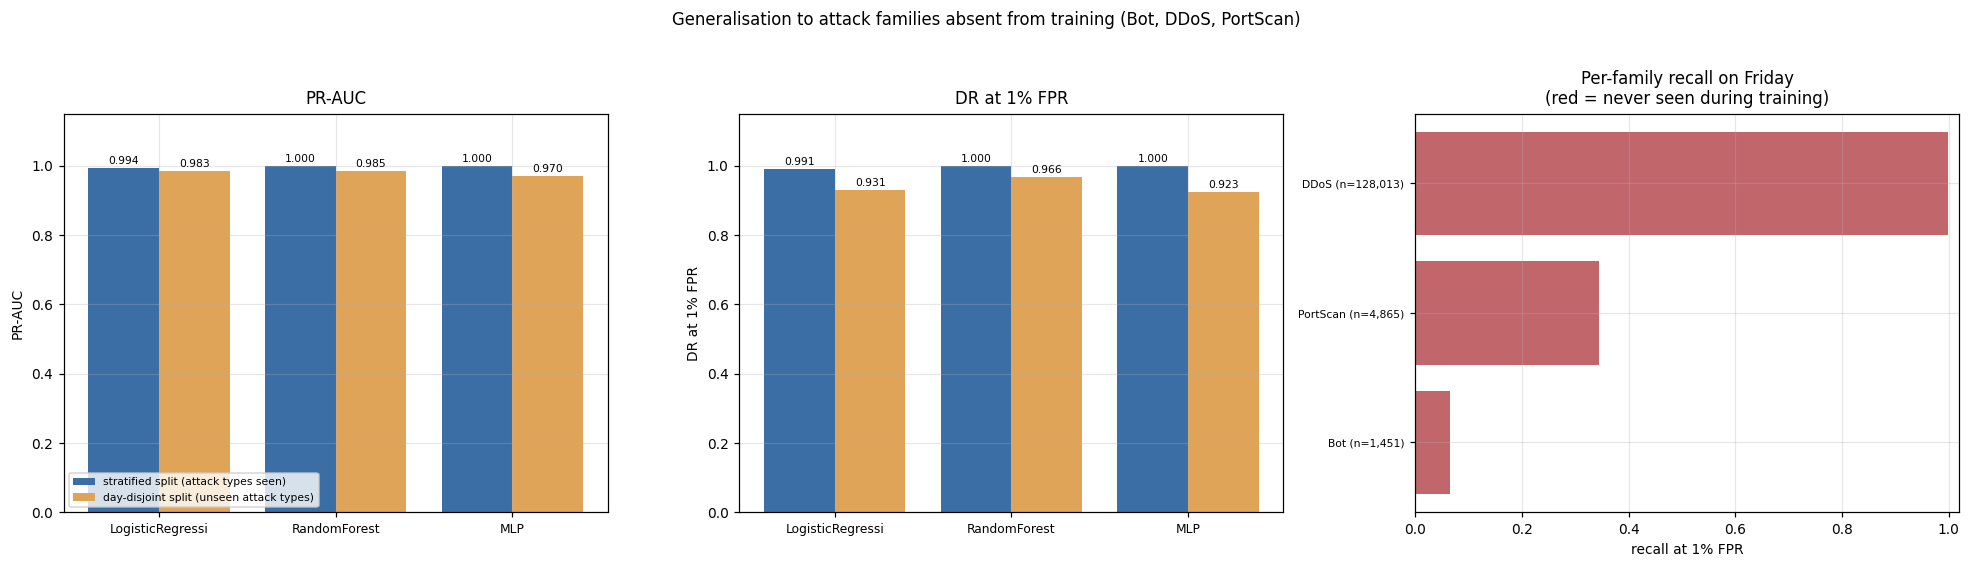

[figure] fig11_unseen_attack.png + .pdf   ->  Evaluation - unseen-attack generalisation


In [ ]:
# --- F11: unseen-attack generalisation -------------------------------------
if len(UNS):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    mods = list(UNS.model); xs = np.arange(len(mods))
    for ax, (col, lbl) in zip(axes[:2], [("pr_auc", "PR-AUC"),
                                         ("fpr1_recall", "DR at 1% FPR")]):
        seen_v = [float(RES2[(RES2.model == m) & (RES2.feature_set == "A")][col].iloc[0])
                  for m in mods]
        uns_v = [float(UNS[UNS.model == m][col].iloc[0]) for m in mods]
        ax.bar(xs - .2, seen_v, .4, label="stratified split (attack types seen)",
               color="#3b6ea5")
        ax.bar(xs + .2, uns_v, .4, label="day-disjoint split (unseen attack types)",
               color="#e0a458")
        for x, (a_, b_) in enumerate(zip(seen_v, uns_v)):
            ax.text(x - .2, a_ + .012, f"{a_:.3f}", ha="center", fontsize=7)
            ax.text(x + .2, b_ + .012, f"{b_:.3f}", ha="center", fontsize=7)
        ax.set(xticks=xs, ylim=(0, 1.15), title=lbl, ylabel=lbl)
        ax.set_xticklabels([m[:16] for m in mods], fontsize=8)
    axes[0].legend(fontsize=7, loc="lower left")

    ax = axes[2]
    sub = UNS_FAM[UNS_FAM.model == UNS.sort_values("pr_auc", ascending=False).iloc[0].model]
    sub = sub.sort_values("recall_at_1pct_fpr")
    bar_c = ["#c1666b" if u else "#3b6ea5" for u in sub.unseen_in_training]
    ax.barh(range(len(sub)), sub.recall_at_1pct_fpr, color=bar_c)
    ax.set_yticks(range(len(sub)))
    ax.set_yticklabels([f"{f} (n={n:,})" for f, n in zip(sub.family, sub.support)], fontsize=7)
    ax.set(xlim=(0, 1.02), xlabel="recall at 1% FPR",
           title="Per-family recall on Friday\n(red = never seen during training)")
    fig.suptitle(f"Generalisation to attack families absent from training "
                 f"({', '.join(unseen_cls)})", y=1.02)
    fig.tight_layout()
    savefig(fig, "fig11_unseen_attack",
            "Detection performance under the stratified split, where every attack family "
            "appears in training, against the day-disjoint split, where Botnet, DDoS and "
            "PortScan appear only in the Friday test set. The right panel breaks recall "
            "down by family, with unseen families highlighted.",
            "Evaluation - unseen-attack generalisation")

The paired bars quantify how much of the near-perfect within-split score depends on having met the attack type before.  
The right panel identifies which specific unseen families survive detection and which collapse.  
This is the question most benchmark papers avoid, so a clear answer here is worth explicit discussion.

---
# 5. Research Question 2 — cross-dataset generalisation

> **RQ2.** How well do models trained on one intrusion detection dataset generalise to a second
> dataset, when tested on a common task and feature representation, and what is responsible for
> any differences in performance?

This is Experiment 4 from the proposal, plus the reverse direction that Experiment 5 lists as
optional. Three rules are enforced throughout:

1. **The source-fitted preprocessor is always applied to the target data.** The CIC and UNSW
   Set B preprocessors emit different column counts because their one-hot service vocabularies
   differ; using the target's own preprocessor would silently change the input space and the
   comparison would be meaningless.
2. **Nothing is refitted on the target.** No retraining, no threshold refitting on target labels,
   except where a row is explicitly labelled as an oracle upper bound.
3. **The gap is attributed, not just reported.** Section 5.3 measures how separable the two
   datasets are from each other in the shared feature space.

In [ ]:
# --- Transfer helpers -------------------------------------------------------
def cache_npz(key, fn):
    """Cache an experiment that returns a metric row plus several probability vectors."""
    jf, nf = RES / "cfg_rows" / f"{key}.json", PROB / f"{key}.npz"
    if CFG["resume"] and jf.exists() and nf.exists():
        print(f"  [cached] {key}")
        return json.loads(jf.read_text()), {k: v for k, v in np.load(nf).items()}
    row, arrs = fn()
    jf.write_text(json.dumps(row, default=str))
    np.savez_compressed(nf, **{k: np.asarray(v, dtype=np.float32) for k, v in arrs.items()})
    return row, arrs

def build_B(pre, frame, idx):
    return transform_block(pre, frame, FSB_NUM, FSB_CAT, idx)

YB = {d: FRAMES[d]["y"].to_numpy().astype(np.int8) for d in ["cic", "unsw"]}
FINE = {d: FRAMES[d]["y_fine"].astype(str).to_numpy() for d in ["cic", "unsw"]}
DIRECTIONS = [("cic", "unsw"), ("unsw", "cic")]
LONG = {"cic": "CIC-IDS2017", "unsw": "UNSW-NB15", "nsl": "NSL-KDD"}

print("Feature Set B numeric columns:", FSB_NUM)
print("Feature Set B categorical    :", FSB_CAT)
print("Excluded UNSW artefacts      :", UNSW_ARTEFACTS)
for d in ["cic", "unsw"]:
    print(f"  {LONG[d]:12s} attack rate {100*YB[d].mean():6.3f}%   "
          f"test rows {len(SPLITS[d]['test']):,}")

Feature Set B numeric columns: ['dur_s', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts', 'src_mean_pkt', 'dst_mean_pkt', 'src_win', 'dst_win', 'iat_mean_s', 'src_bytes_per_s', 'dst_bytes_per_s', 'src_pkts_per_s', 'dst_pkts_per_s', 'total_bytes', 'total_pkts', 'mean_pkt_size', 'bytes_ratio', 'pkts_ratio']
Feature Set B categorical    : ['service_grp']
Excluded UNSW artefacts      : ['sttl', 'dttl', 'ct_state_ttl']
  CIC-IDS2017  attack rate 15.122%   test rows 448,705
  UNSW-NB15    attack rate  3.869%   test rows 403,323


Feature Set B is the harmonised representation Notebook 02 built, with every quantity converted to SI units on both sides.  
The three time-to-live columns that dominate UNSW are excluded, so the transfer cannot be flattered by a testbed artefact.  
Both transfer directions are run, which turns the optional Experiment 5 into an actual result rather than a stated intention.

In [ ]:
# --- Experiment 4: train on one dataset, evaluate frozen on the other -------
TRANSFER, TPROBS = [], {}
for src, tgt in DIRECTIONS:
    pre = PREPROC[(src, "B")]
    sps, spt = SPLITS[src], SPLITS[tgt]
    tr = sps["train"]
    if CFG["transfer_train"] is not None and len(tr) > CFG["transfer_train"]:
        tr = np.sort(np.random.default_rng(SEED).choice(tr, CFG["transfer_train"],
                                                        replace=False))
    print(f"\n{'='*74}\n{LONG[src]}  ->  {LONG[tgt]}   "
          f"(train {len(tr):,} rows, source-fitted preprocessor)\n{'='*74}")
    t0 = time.time()
    Xtr = build_B(pre, FSB_FRAMES[src], tr)
    Xva_s = build_B(pre, FSB_FRAMES[src], sps["val"])
    Xte_s = build_B(pre, FSB_FRAMES[src], sps["test"])
    Xva_t = build_B(pre, FSB_FRAMES[tgt], spt["val"])
    Xte_t = build_B(pre, FSB_FRAMES[tgt], spt["test"])
    print(f"  matrices built in {time.time()-t0:.0f}s   source {Xtr.shape}  "
          f"target test {Xte_t.shape}")
    ytr, yva_s, yte_s = YB[src][tr], YB[src][sps["val"]], YB[src][sps["test"]]
    yva_t, yte_t = YB[tgt][spt["val"]], YB[tgt][spt["test"]]

    for mn in MODEL_ORDER:
        key = f"tr_{src}2{tgt}_{mn}"
        def _f(mn=mn):
            if mn == "MLP":
                mdl, pv, _, f_s, _, ex = run_mlp(Xtr, ytr, Xva_s, yva_s, Xva_s[:10])
            else:
                runner = run_rf if mn == "RandomForest" else run_lr
                mdl, pv, _, f_s, _, ex = runner(Xtr, ytr, Xva_s, Xva_s[:10])
            p_te_s = proba1(mdl, Xte_s)
            t0_ = time.time(); p_te_t = proba1(mdl, Xte_t); i_s = time.time() - t0_
            p_va_t = proba1(mdl, Xva_t)
            r_within = evaluate(mn, f"{src}->{src}", yva_s, pv, yte_s, p_te_s, f_s, i_s,
                                len(yte_s), extra=ex)
            r_tr = evaluate(mn, f"{src}->{tgt}", yva_s, pv, yte_t, p_te_t, f_s, i_s,
                            len(yte_t), extra=ex)
            row = {"source": src, "target": tgt, "model": mn, "n_train": int(len(ytr)),
                   "within_pr_auc": r_within["pr_auc"], "within_roc_auc": r_within["roc_auc"],
                   "within_dr": r_within["fpr1_recall"], "within_fpr": r_within["fpr1_fpr"],
                   "transfer_pr_auc": r_tr["pr_auc"], "transfer_roc_auc": r_tr["roc_auc"],
                   "transfer_dr": r_tr["fpr1_recall"], "transfer_fpr": r_tr["fpr1_fpr"],
                   "transfer_precision": r_tr["fpr1_precision"],
                   "transfer_mcc": r_tr["f1_mcc"],
                   "target_base_rate": r_tr["base_rate"],
                   "source_threshold_fpr1": r_within["fpr1_threshold"],
                   "delta_pr_auc": round(r_tr["pr_auc"] - r_within["pr_auc"], 5),
                   "retained_pct": round(100 * r_tr["pr_auc"] / max(r_within["pr_auc"], 1e-9), 1),
                   "fit_seconds": r_within["fit_seconds"]}
            arrs = {"p_va_s": pv, "p_te_s": p_te_s, "p_va_t": p_va_t, "p_te_t": p_te_t}
            del mdl; gc.collect()
            return row, arrs
        row, arrs = cache_npz(key, _f)
        TRANSFER.append(row); TPROBS[(src, tgt, mn)] = arrs
        print(f"  {mn:18s} within PR-AUC={row['within_pr_auc']:.5f} -> "
              f"transfer PR-AUC={row['transfer_pr_auc']:.5f}  "
              f"({row['retained_pct']:.1f}% retained)   "
              f"transfer DR@src-threshold={row['transfer_dr']:.5f}  "
              f"FPR={row['transfer_fpr']:.5f}")
        gc.collect()
    del Xtr, Xva_s, Xte_s, Xva_t, Xte_t; gc.collect(); mem(f"after {src}->{tgt}")

TR = pd.DataFrame(TRANSFER)
display(TR[["source", "target", "model", "within_pr_auc", "transfer_pr_auc", "retained_pct",
            "within_dr", "transfer_dr", "transfer_fpr", "transfer_precision"]].round(5))
TR.to_csv(RES / "rq2_transfer_results.csv", index=False)
print("\nWithin-dataset scores use the same feature set, the same preprocessing and the same")
print("training budget as the transfer scores, so the drop is attributable to the domain change")
print("alone rather than to any change in the experimental protocol.")
M["results"]["rq2_transfer"] = TR.to_dict("records")


CIC-IDS2017  ->  UNSW-NB15   (train 800,000 rows, source-fitted preprocessor)
  matrices built in 4s   source (800000, 32)  target test (403323, 32)
  LogisticRegression within PR-AUC=0.94498 -> transfer PR-AUC=0.06470  (6.8% retained)   transfer DR@src-threshold=0.02262  FPR=0.01000
  RandomForest       within PR-AUC=0.99984 -> transfer PR-AUC=0.06674  (6.7% retained)   transfer DR@src-threshold=0.03448  FPR=0.03573
  MLP                within PR-AUC=0.99962 -> transfer PR-AUC=0.23671  (23.7% retained)   transfer DR@src-threshold=0.11305  FPR=0.00214
    [memory]  7.42 GB  after cic->unsw

UNSW-NB15  ->  CIC-IDS2017   (train 800,000 rows, source-fitted preprocessor)
  matrices built in 5s   source (800000, 33)  target test (448705, 33)
  LogisticRegression within PR-AUC=0.59444 -> transfer PR-AUC=0.15325  (25.8% retained)   transfer DR@src-threshold=0.29693  FPR=0.22685
  RandomForest       within PR-AUC=0.96706 -> transfer PR-AUC=0.13183  (13.6% retained)   transfer DR@src-threshold

,source,target,model,within_pr_auc,transfer_pr_auc,retained_pct,within_dr,transfer_dr,transfer_fpr,transfer_precision
0,cic,unsw,LogisticRegression,0.94498,0.06470,6.8,0.95686,0.02262,0.01000,0.08343
1,cic,unsw,RandomForest,0.99984,0.06674,6.7,0.99978,0.03448,0.03573,0.03739
2,cic,unsw,MLP,0.99962,0.23671,23.7,0.99873,0.11305,0.00214,0.68003
3,unsw,cic,LogisticRegression,0.59444,0.15325,25.8,0.43489,0.29693,0.22685,0.18910
4,unsw,cic,RandomForest,0.96706,0.13183,13.6,0.96462,0.00833,0.23468,0.00628
5,unsw,cic,MLP,0.96460,0.12524,13.0,0.95411,0.22426,0.42951,0.08511



Within-dataset scores use the same feature set, the same preprocessing and the same
training budget as the transfer scores, so the drop is attributable to the domain change
alone rather than to any change in the experimental protocol.


Each model is trained once on the source and then evaluated on both the source test set and the frozen target, so the two numbers differ only by the domain change.  
The retained percentage is the headline generalisation measure: how much of the within-dataset PR-AUC survives the move to another network.  
The transfer false-positive rate is reported at the source-selected threshold, which is what an operator deploying the model unchanged would actually experience.

In [ ]:
# --- 5.2 Threshold transfer: what happens to the operating point? ----------
TH = []
for src, tgt in DIRECTIONS:
    spt = SPLITS[tgt]
    yte_t, yva_t = YB[tgt][spt["test"]], YB[tgt][spt["val"]]
    yva_s = YB[src][SPLITS[src]["val"]]
    for mn in MODEL_ORDER:
        a = TPROBS[(src, tgt, mn)]
        thr_src = pick_thresholds(yva_s, a["p_va_s"])["fpr1"]
        thr_orc = pick_thresholds(yva_t, a["p_va_t"])["fpr1"]
        # unsupervised recalibration: match the alert VOLUME seen on the source
        alert_rate = float((a["p_va_s"] >= thr_src).mean())
        thr_q = float(np.quantile(a["p_te_t"], 1 - alert_rate))
        for tag, t in [("source_threshold", thr_src),
                       ("quantile_matched", thr_q),
                       ("target_oracle", thr_orc)]:
            m_ = at_threshold(yte_t, a["p_te_t"], t)
            TH.append({"source": src, "target": tgt, "model": mn, "policy": tag,
                       "threshold": round(float(t), 6), "recall": m_["recall"],
                       "precision": m_["precision"], "fpr": m_["fpr"], "f1": m_["f1"],
                       "mcc": m_["mcc"],
                       "alerts_per_1M": int(round(1e6 * (m_["TP"] + m_["FP"]) / len(yte_t))),
                       "false_alerts_per_1M": int(round(m_["fpr"] * 1e6))})
THD = pd.DataFrame(TH)
display(THD.round(5))
THD.to_csv(RES / "rq2_threshold_transfer.csv", index=False)

print("\nHow far wrong is the transferred operating point?")
for (src, tgt, mn), g in THD.groupby(["source", "target", "model"]):
    s_ = g[g.policy == "source_threshold"].iloc[0]
    q_ = g[g.policy == "quantile_matched"].iloc[0]
    o_ = g[g.policy == "target_oracle"].iloc[0]
    print(f"  {LONG[src][:4]}->{LONG[tgt][:4]} {mn:18s} "
          f"FPR {s_.fpr:.4f} (source) | {q_.fpr:.4f} (quantile) | {o_.fpr:.4f} (oracle)   "
          f"recall {s_.recall:.4f} | {q_.recall:.4f} | {o_.recall:.4f}")
print("\nThe source threshold is chosen for a 1% false-positive budget on the SOURCE. The")
print("distance between its realised target FPR and 1% is the practical cost of assuming an")
print("operating point transfers. The quantile-matched row is the only correction available")
print("without target labels; the oracle row is an upper bound and is not deployable.")
M["results"]["rq2_thresholds"] = THD.to_dict("records")

,source,target,model,policy,threshold,recall,precision,fpr,f1,mcc,alerts_per_1M,false_alerts_per_1M
0,cic,unsw,LogisticRegression,source_threshold,0.75426,0.02262,0.08343,0.01000,0.03559,0.02389,10490,10002
1,cic,unsw,LogisticRegression,quantile_matched,0.02096,0.23757,0.06004,0.14968,0.09586,0.04708,153076,149675
2,cic,unsw,LogisticRegression,target_oracle,0.72146,0.02801,0.10097,0.01004,0.04385,0.03364,10731,10036
3,cic,unsw,RandomForest,source_threshold,0.11936,0.03448,0.03739,0.03573,0.03587,-0.00130,35679,35727
4,cic,unsw,RandomForest,quantile_matched,0.04374,0.44322,0.10437,0.15308,0.16895,0.15100,164303,153077
5,cic,unsw,RandomForest,target_oracle,0.18126,0.02185,0.08245,0.00979,0.03455,0.02310,10255,9788
6,cic,unsw,MLP,source_threshold,0.29235,0.11305,0.68003,0.00214,0.19387,0.26756,6432,2141
7,cic,unsw,MLP,quantile_matched,0.00078,0.61824,0.15001,0.14098,0.24144,0.25141,159445,140981
8,cic,unsw,MLP,target_oracle,0.05792,0.16611,0.40468,0.00983,0.23554,0.24108,15881,9834
9,unsw,cic,LogisticRegression,source_threshold,0.97890,0.29693,0.18910,0.22685,0.23106,0.05901,237448,226850



How far wrong is the transferred operating point?
  CIC-->UNSW LogisticRegression FPR 0.0100 (source) | 0.1497 (quantile) | 0.0100 (oracle)   recall 0.0226 | 0.2376 | 0.0280
  CIC-->UNSW MLP                FPR 0.0021 (source) | 0.1410 (quantile) | 0.0098 (oracle)   recall 0.1130 | 0.6182 | 0.1661
  CIC-->UNSW RandomForest       FPR 0.0357 (source) | 0.1531 (quantile) | 0.0098 (oracle)   recall 0.0345 | 0.4432 | 0.0219
  UNSW->CIC- LogisticRegression FPR 0.2268 (source) | 0.0264 (quantile) | 0.0091 (oracle)   recall 0.2969 | 0.0254 | 0.0200
  UNSW->CIC- MLP                FPR 0.4295 (source) | 0.0470 (quantile) | 0.0097 (oracle)   recall 0.2243 | 0.0446 | 0.0082
  UNSW->CIC- RandomForest       FPR 0.2347 (source) | 0.0553 (quantile) | 0.0096 (oracle)   recall 0.0083 | 0.0006 | 0.0000

The source threshold is chosen for a 1% false-positive budget on the SOURCE. The
distance between its realised target FPR and 1% is the practical cost of assuming an
operating point transfers. The quantil

A threshold is part of a deployed detector, so a transfer study that reports only threshold-free metrics hides half the problem.  
Three policies are compared: reusing the source threshold, matching the alert volume without labels, and an oracle that peeks at target labels.  
The gap between the first and third is what an operator loses by assuming a calibrated operating point carries across networks.

In [ ]:
# --- 5.3 Attributing the gap: how separable are the two datasets? ----------
r = np.random.default_rng(SEED)
pre_c = PREPROC[("cic", "B")]
nsamp = 120_000
ic = np.sort(r.choice(SPLITS["cic"]["test"], min(nsamp, len(SPLITS["cic"]["test"])),
                      replace=False))
iu = np.sort(r.choice(SPLITS["unsw"]["test"], min(nsamp, len(SPLITS["unsw"]["test"])),
                      replace=False))
Zc = build_B(pre_c, FSB_FRAMES["cic"], ic)
Zu = build_B(pre_c, FSB_FRAMES["unsw"], iu)
Z = np.vstack([Zc, Zu]); zlab = np.r_[np.zeros(len(Zc)), np.ones(len(Zu))].astype(np.int8)
NB_ = names_of(pre_c, FSB_NUM, FSB_CAT, Z.shape[1])

perm = r.permutation(len(Z)); cut = int(0.7 * len(Z))
dom = RandomForestClassifier(n_estimators=120, max_depth=14, min_samples_leaf=20, n_jobs=-1,
                             random_state=SEED)
dom.fit(Z[perm[:cut]], zlab[perm[:cut]])
dom_auc = roc_auc_score(zlab[perm[cut:]], dom.predict_proba(Z[perm[cut:]])[:, 1])
DOMIMP = (pd.DataFrame({"feature": NB_, "domain_importance": dom.feature_importances_})
            .sort_values("domain_importance", ascending=False).reset_index(drop=True))
print(f"Domain classifier AUC (can a model tell CIC from UNSW in the shared space?): "
      f"{dom_auc:.5f}")
print("An AUC near 1.0 means the two datasets occupy almost disjoint regions of Feature Set B,")
print("which is a sufficient explanation for any transfer failure observed above.")
display(DOMIMP.head(10).round(5))

from scipy.stats import wasserstein_distance
rows = []
for j, f in enumerate(FSB_NUM):
    a_, b_ = signed_log1p(FSB_FRAMES["cic"][f].to_numpy()[ic]), \
             signed_log1p(FSB_FRAMES["unsw"][f].to_numpy()[iu])
    sd = np.std(np.concatenate([a_, b_])) or 1.0
    rows.append({"feature": f,
                 "wasserstein_logscale": round(float(wasserstein_distance(a_, b_) / sd), 4),
                 "cic_median": round(float(np.median(FSB_FRAMES['cic'][f].to_numpy()[ic])), 3),
                 "unsw_median": round(float(np.median(FSB_FRAMES['unsw'][f].to_numpy()[iu])), 3)})
SHIFT = pd.DataFrame(rows).sort_values("wasserstein_logscale", ascending=False)
display(SHIFT.head(12))
SHIFT.to_csv(RES / "rq2_covariate_shift.csv", index=False)
DOMIMP.to_csv(RES / "rq2_domain_importance.csv", index=False)

lab = pd.DataFrame({"dataset": ["CIC-IDS2017", "UNSW-NB15"],
                    "attack_rate_pct": [round(100 * YB["cic"].mean(), 3),
                                        round(100 * YB["unsw"].mean(), 3)],
                    "n_attack_families": [len(set(FINE["cic"])) - 1, len(set(FINE["unsw"])) - 1],
                    "families": [", ".join(sorted(set(FINE["cic"]))[:6]) + " ...",
                                 ", ".join(sorted(set(FINE["unsw"]))[:6]) + " ..."]})
display(lab)
print("\nThree mechanisms are now measured rather than asserted:")
print(f"  1. covariate shift    - worst feature {SHIFT.iloc[0].feature} at "
      f"{SHIFT.iloc[0].wasserstein_logscale} normalised Wasserstein units")
print(f"  2. domain separability - a classifier distinguishes the datasets at AUC {dom_auc:.4f}")
print(f"  3. prior shift        - attack prevalence {100*YB['cic'].mean():.2f}% versus "
      f"{100*YB['unsw'].mean():.2f}%, and the attack taxonomies barely overlap")
M["results"]["rq2_attribution"] = {"domain_auc": float(dom_auc),
                                   "top_shift": SHIFT.head(6).to_dict("records"),
                                   "top_domain_features": DOMIMP.head(6).to_dict("records")}
del Z, Zc, Zu; gc.collect()

Domain classifier AUC (can a model tell CIC from UNSW in the shared space?): 1.00000
An AUC near 1.0 means the two datasets occupy almost disjoint regions of Feature Set B,
which is a sufficient explanation for any transfer failure observed above.


,feature,domain_importance
0,src_mean_pkt,0.17222
1,src_win,0.10936
2,src_bytes,0.10131
3,src_bytes_per_s,0.09302
4,dst_win,0.07364
5,src_pkts_per_s,0.05065
6,total_bytes,0.05012
7,iat_mean_s,0.04430
8,dst_pkts,0.04114
9,dst_pkts_per_s,0.04072


,feature,wasserstein_logscale,cic_median,unsw_median
1,src_bytes,1.2264,74.000,1920.000
10,src_bytes_per_s,1.1363,646.795,106104.651
4,dst_pkts,1.1046,2.000,18.000
15,total_pkts,1.0978,4.000,34.000
3,src_pkts,1.0711,2.000,16.000
11,dst_bytes_per_s,1.0663,1182.056,161524.500
13,dst_pkts_per_s,1.0119,16.339,1077.572
14,total_bytes,1.0018,286.000,9202.000
5,src_mean_pkt,0.9821,40.000,73.000
12,src_pkts_per_s,0.8932,27.929,1228.710


,dataset,attack_rate_pct,n_attack_families,families
0,CIC-IDS2017,15.122,14,"BENIGN, Bot, DDoS, DoS GoldenEye, DoS Hulk, Do..."
1,UNSW-NB15,3.869,9,"Analysis, Backdoor, DoS, Exploits, Fuzzers, Ge..."



Three mechanisms are now measured rather than asserted:
  1. covariate shift    - worst feature src_bytes at 1.2264 normalised Wasserstein units
  2. domain separability - a classifier distinguishes the datasets at AUC 1.0000
  3. prior shift        - attack prevalence 15.12% versus 3.87%, and the attack taxonomies barely overlap


75

A domain classifier trained to tell the two datasets apart converts an abstract claim about distribution shift into one measurable number.  
The Wasserstein table names the individual features that moved most, and the label table shows the prior and taxonomy differences on top of that.  
Together these three mechanisms are the answer to the second half of RQ2, which asks what is responsible for the difference in performance.

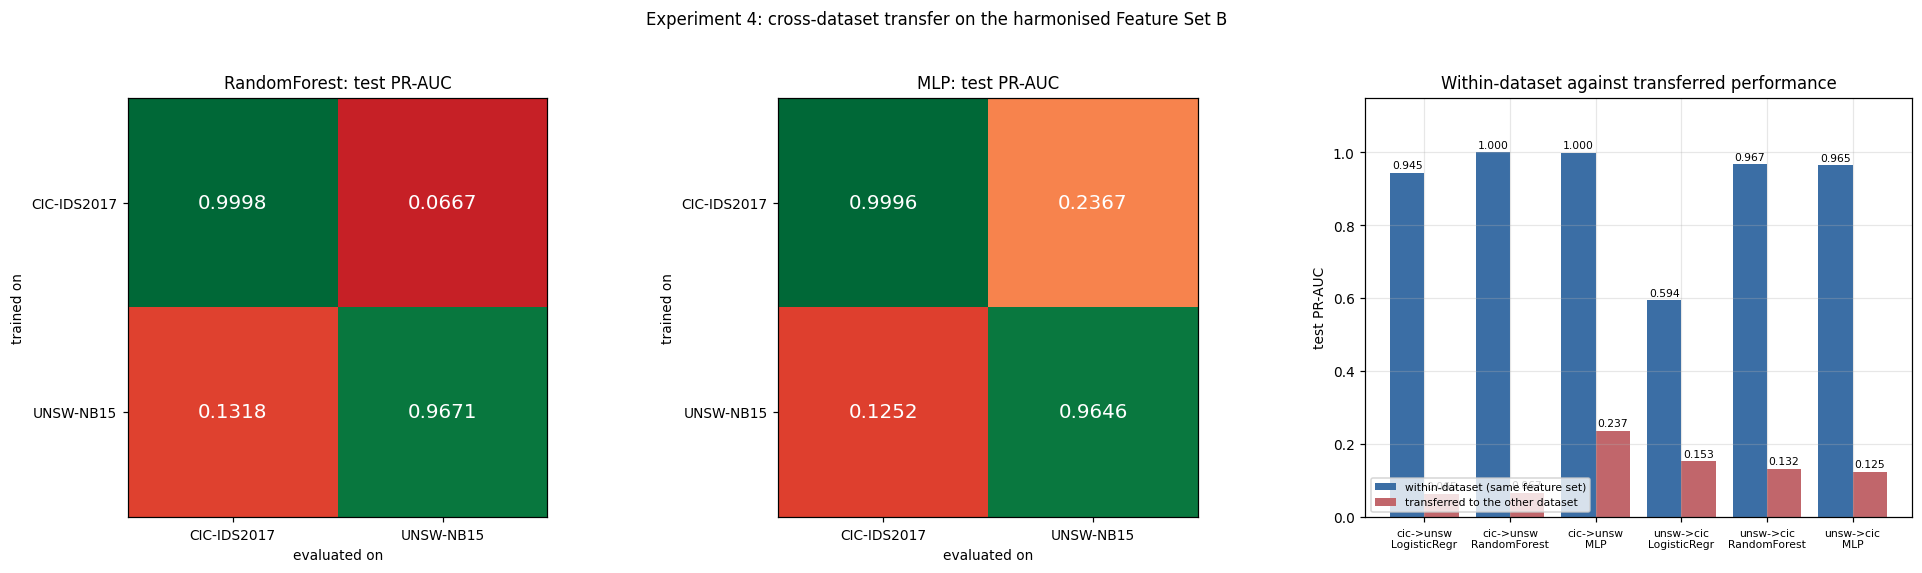

[figure] fig12_transfer_matrix.png + .pdf   ->  Results - RQ2 transfer


In [ ]:
# --- F12: the transfer matrix and the size of the gap ----------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
mods = MODEL_ORDER
for ax, mn in zip(axes[:2], ["RandomForest", "MLP"]):
    mat = np.full((2, 2), np.nan)
    order = ["cic", "unsw"]
    for i, s_ in enumerate(order):
        for j, t_ in enumerate(order):
            if s_ == t_:
                q = TR[(TR.source == s_) & (TR.model == mn)]
                if len(q):
                    mat[i, j] = q.iloc[0]["within_pr_auc"]
            else:
                q = TR[(TR.source == s_) & (TR.target == t_) & (TR.model == mn)]
                if len(q):
                    mat[i, j] = q.iloc[0]["transfer_pr_auc"]
    im = ax.imshow(mat, cmap="RdYlGn", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(mat):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.4f}", ha="center", va="center", fontsize=13,
                    color="black" if 0.25 < v < 0.85 else "white")
    ax.set(xticks=[0, 1], yticks=[0, 1], title=f"{mn}: test PR-AUC")
    ax.set_xticklabels([LONG[o] for o in order]); ax.set_yticklabels([LONG[o] for o in order])
    ax.set_xlabel("evaluated on"); ax.set_ylabel("trained on")
    ax.grid(False)
ax = axes[2]
xs = np.arange(len(TR))
lbl = [f"{r.source[:4]}->{r.target[:4]}\n{r.model[:12]}" for _, r in TR.iterrows()]
ax.bar(xs - .2, TR.within_pr_auc, .4, label="within-dataset (same feature set)",
       color="#3b6ea5")
ax.bar(xs + .2, TR.transfer_pr_auc, .4, label="transferred to the other dataset",
       color="#c1666b")
for x, (a_, b_) in enumerate(zip(TR.within_pr_auc, TR.transfer_pr_auc)):
    ax.text(x - .2, a_ + .012, f"{a_:.3f}", ha="center", fontsize=7)
    ax.text(x + .2, b_ + .012, f"{b_:.3f}", ha="center", fontsize=7)
ax.set(xticks=xs, ylim=(0, 1.15), ylabel="test PR-AUC",
       title="Within-dataset against transferred performance")
ax.set_xticklabels(lbl, fontsize=7)
ax.legend(fontsize=7, loc="lower left")
fig.suptitle("Experiment 4: cross-dataset transfer on the harmonised Feature Set B", y=1.03)
fig.tight_layout()
savefig(fig, "fig12_transfer_matrix",
        "Cross-dataset transfer results on the harmonised Feature Set B. Diagonal cells are "
        "within-dataset performance and off-diagonal cells are performance after training on "
        "one dataset and evaluating frozen on the other, always using the source-fitted "
        "preprocessor.",
        "Results - RQ2 transfer")

The matrices put within-dataset and transferred performance side by side under an identical protocol.  
The diagonal is what the benchmark literature usually reports and the off-diagonal is what a deployment would experience.  
The right-hand panel gives the same information per model, which is the table to cite for the retained-percentage figures.

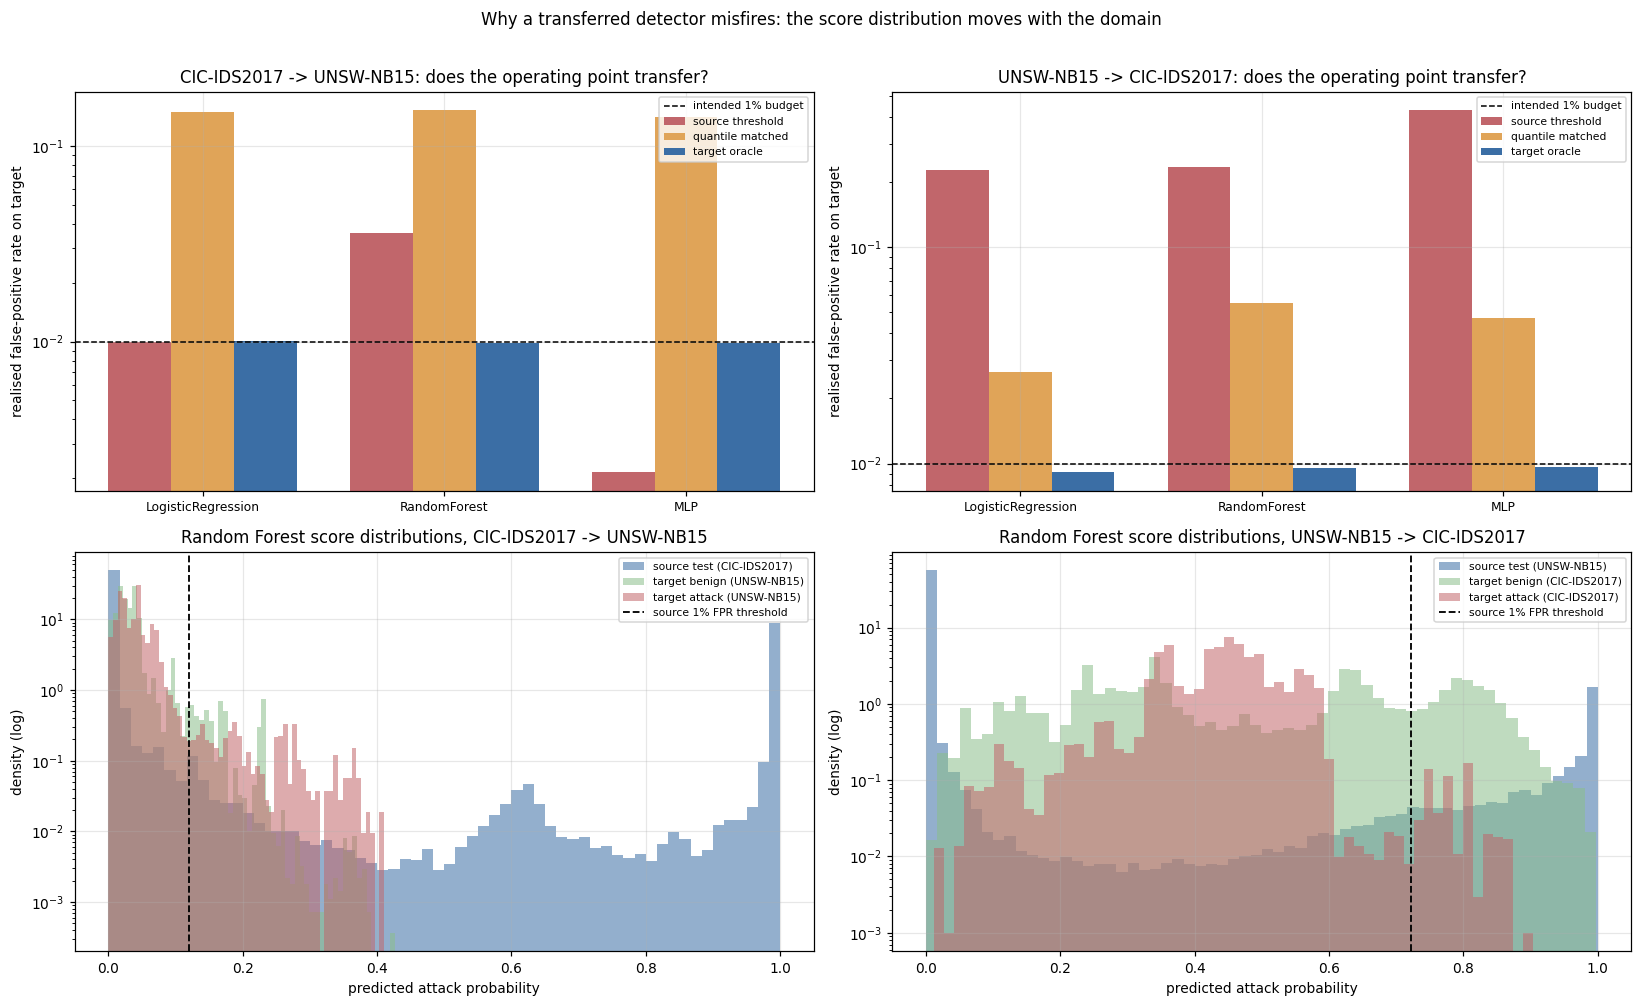

[figure] fig13_threshold_transfer.png + .pdf   ->  Results - RQ2 operating point


In [ ]:
# --- F13: threshold transfer and target score distributions ----------------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, (src, tgt) in zip(axes[0], DIRECTIONS):
    g = THD[(THD.source == src) & (THD.target == tgt)]
    xs = np.arange(len(MODEL_ORDER)); w = 0.26
    for k, (pol, c) in enumerate([("source_threshold", "#c1666b"),
                                  ("quantile_matched", "#e0a458"),
                                  ("target_oracle", "#3b6ea5")]):
        v = [float(g[(g.model == m) & (g.policy == pol)].fpr.iloc[0])
             if len(g[(g.model == m) & (g.policy == pol)]) else np.nan for m in MODEL_ORDER]
        ax.bar(xs + (k - 1) * w, v, w, label=pol.replace("_", " "), color=c)
    ax.axhline(CFG["fpr_budget"], ls="--", c="black", lw=1,
               label="intended 1% budget")
    ax.set(xticks=xs, yscale="log", ylabel="realised false-positive rate on target",
           title=f"{LONG[src]} -> {LONG[tgt]}: does the operating point transfer?")
    ax.set_xticklabels(MODEL_ORDER, fontsize=8)
    ax.legend(fontsize=7)
for ax, (src, tgt) in zip(axes[1], DIRECTIONS):
    a = TPROBS[(src, tgt, "RandomForest")]
    yte_t = YB[tgt][SPLITS[tgt]["test"]]
    ax.hist(a["p_te_s"], bins=60, alpha=.55, density=True, color="#3b6ea5",
            label=f"source test ({LONG[src]})")
    ax.hist(a["p_te_t"][yte_t == 0], bins=60, alpha=.55, density=True, color="#8bbf8b",
            label=f"target benign ({LONG[tgt]})")
    ax.hist(a["p_te_t"][yte_t == 1], bins=60, alpha=.55, density=True, color="#c1666b",
            label=f"target attack ({LONG[tgt]})")
    thr = float(TR[(TR.source == src) & (TR.model == "RandomForest")].iloc[0]
                ["source_threshold_fpr1"])
    ax.axvline(thr, ls="--", c="black", lw=1.2, label="source 1% FPR threshold")
    ax.set(yscale="log", xlabel="predicted attack probability", ylabel="density (log)",
           title=f"Random Forest score distributions, {LONG[src]} -> {LONG[tgt]}")
    ax.legend(fontsize=7)
fig.suptitle("Why a transferred detector misfires: the score distribution moves with the domain",
             y=1.01)
fig.tight_layout()
savefig(fig, "fig13_threshold_transfer",
        "Top: realised false-positive rate on the target dataset under three threshold "
        "policies, against the one per cent budget the threshold was chosen to satisfy on "
        "the source. Bottom: predicted-probability distributions on source and target, "
        "showing how far the transferred operating point sits from where it should be.",
        "Results - RQ2 operating point")

The top row shows how badly the intended one per cent alert budget is missed once the model meets a different network.  
The bottom row explains the mechanism: the whole score distribution shifts, so a fixed cut-off lands in the wrong place.  
Quantile matching partially corrects this without needing target labels, which is the only remediation available in practice.

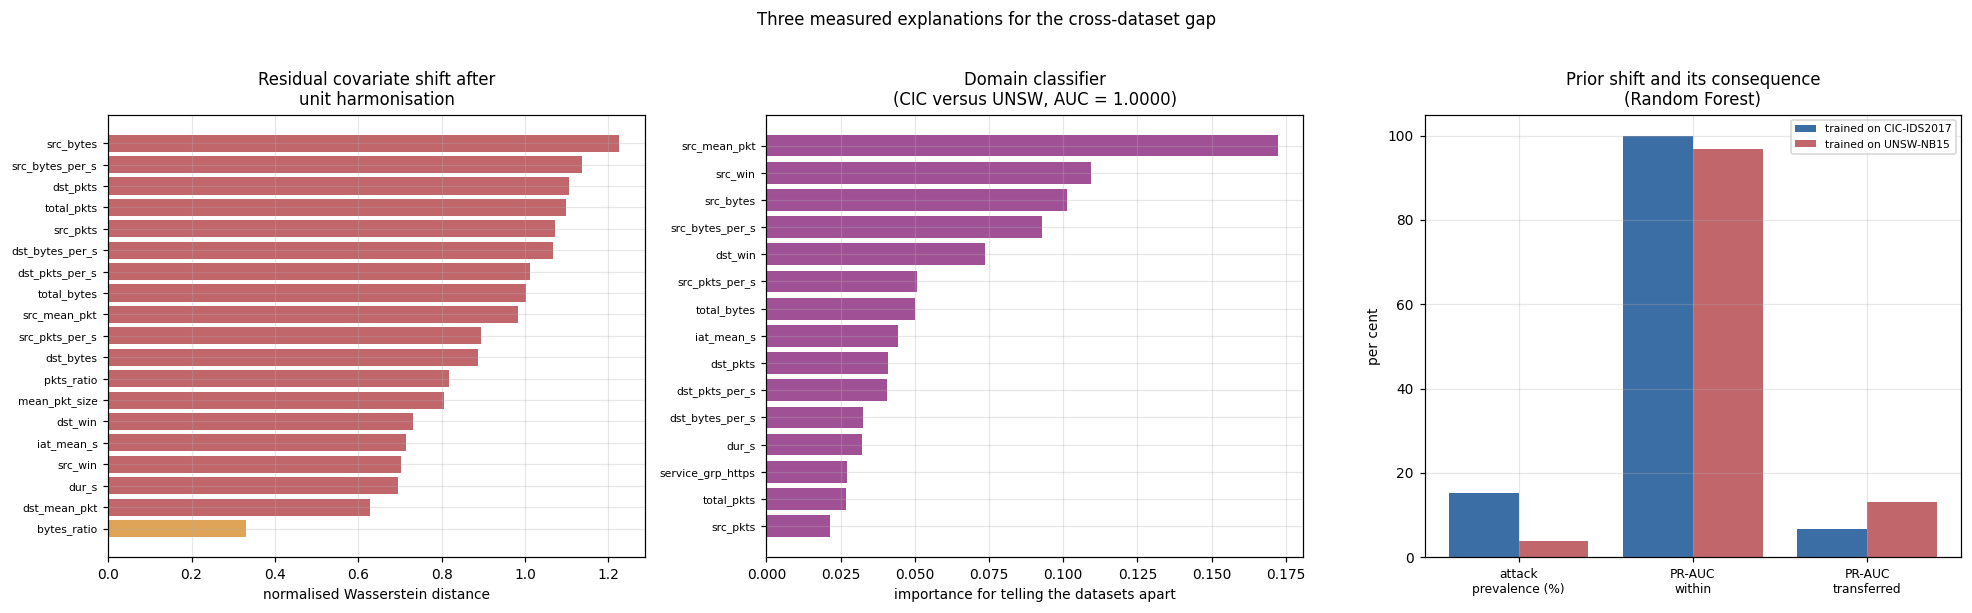

[figure] fig14_transfer_attribution.png + .pdf   ->  Evaluation - RQ2 attribution


In [ ]:
# --- F14: attribution of the transfer gap ----------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))
s = SHIFT.iloc[::-1]
axes[0].barh(range(len(s)), s.wasserstein_logscale,
             color=["#c1666b" if v > .5 else "#e0a458" if v > .25 else "#3b6ea5"
                    for v in s.wasserstein_logscale])
axes[0].set_yticks(range(len(s))); axes[0].set_yticklabels(s.feature, fontsize=7)
axes[0].set(xlabel="normalised Wasserstein distance",
            title="Residual covariate shift after\nunit harmonisation")

d = DOMIMP.head(15).iloc[::-1]
axes[1].barh(range(len(d)), d.domain_importance, color="#a05195")
axes[1].set_yticks(range(len(d)))
axes[1].set_yticklabels([f[:26] for f in d.feature], fontsize=7)
axes[1].set(xlabel="importance for telling the datasets apart",
            title=f"Domain classifier\n(CIC versus UNSW, AUC = {dom_auc:.4f})")

ax = axes[2]
labels = ["attack\nprevalence (%)", "PR-AUC\nwithin", "PR-AUC\ntransferred"]
rf_c = TR[(TR.source == "cic") & (TR.model == "RandomForest")].iloc[0]
rf_u = TR[(TR.source == "unsw") & (TR.model == "RandomForest")].iloc[0]
xs = np.arange(3)
ax.bar(xs - .2, [100 * YB["cic"].mean(), rf_c.within_pr_auc * 100,
                 rf_c.transfer_pr_auc * 100], .4, label="trained on CIC-IDS2017",
       color="#3b6ea5")
ax.bar(xs + .2, [100 * YB["unsw"].mean(), rf_u.within_pr_auc * 100,
                 rf_u.transfer_pr_auc * 100], .4, label="trained on UNSW-NB15",
       color="#c1666b")
ax.set(xticks=xs, ylabel="per cent", title="Prior shift and its consequence\n(Random Forest)")
ax.set_xticklabels(labels, fontsize=8)
ax.legend(fontsize=7)
fig.suptitle("Three measured explanations for the cross-dataset gap", y=1.02)
fig.tight_layout()
savefig(fig, "fig14_transfer_attribution",
        "Attribution of the cross-dataset gap. Left: residual distributional distance per "
        "feature after unit harmonisation. Centre: importance of each feature to a "
        "classifier trained to distinguish the two datasets. Right: the difference in attack "
        "prevalence alongside the within-dataset and transferred scores.",
        "Evaluation - RQ2 attribution")

Each panel is one candidate explanation for the transfer gap, measured rather than argued from the literature.  
The centre panel is the strongest single piece of evidence, since a domain classifier scoring near one means the datasets barely overlap.  
The right panel adds prior shift, which affects precision directly even where ranking quality survives.

## 5.4 The three-way comparison including NSL-KDD

Notebook 01 found that only four flow concepts survive across all three datasets, which is why
NSL-KDD was excluded from the twenty-feature Feature Set B. Objective 3 nevertheless asks for a
comparison across **all three** datasets, so a deliberately minimal representation is built here:
flow duration, source bytes, destination bytes and a shared service group.

Four features cannot support a strong detector. That is the point. This experiment establishes
the floor: how much detection survives when the shared vocabulary is this thin, and whether the
1998-era connection records in NSL-KDD relate to modern flow exports at all.

In [ ]:
# --- Minimal shared representation across all three datasets ---------------
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, FunctionTransformer

NSL_SERVICE = {
    "http": "http", "http_443": "https", "http_8001": "http", "http_2784": "http",
    "domain": "dns", "domain_u": "dns", "smtp": "smtp", "ftp": "ftp", "ftp_data": "ftp",
    "telnet": "telnet", "pop_3": "pop3", "pop_2": "pop3", "imap4": "imap", "ssh": "ssh",
    "ldap": "ldap", "ntp_u": "ntp", "sunrpc": "rpc", "nntp": "nntp", "IRC": "irc",
    "netbios_ns": "smb", "netbios_dgm": "smb", "netbios_ssn": "smb", "sql_net": "mssql",
    "private": "registered", "other": "registered",
}

def minimal_frame(ds):
    if ds in ("cic", "unsw"):
        f = FSB_FRAMES[ds]
        return pd.DataFrame({"dur_s": f["dur_s"].astype("float64").values,
                             "src_bytes": f["src_bytes"].astype("float64").values,
                             "dst_bytes": f["dst_bytes"].astype("float64").values,
                             "service_grp": f["service_grp"].astype(str).values})
    f = FRAMES["nsl"]
    svc = pd.Series(f["service"].astype(str).values)
    return pd.DataFrame({"dur_s": f["duration"].astype("float64").values,
                         "src_bytes": f["src_bytes"].astype("float64").values,
                         "dst_bytes": f["dst_bytes"].astype("float64").values,
                         "service_grp": svc.map(NSL_SERVICE).fillna("registered").values})

MIN_NUM = ["dur_s", "src_bytes", "dst_bytes"]
MIN_CAT = ["service_grp"]
MINF = {d: minimal_frame(d) for d in ["cic", "unsw", "nsl"]}
YM = {d: FRAMES[d]["y"].to_numpy().astype(np.int8) for d in ["cic", "unsw", "nsl"]}

def make_min_pre():
    num = Pipeline([("winsor", Winsoriser(upper=0.9999)),
                    ("slog", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                    ("scale", RobustScaler())])
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=0.005)
    except TypeError:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    return ColumnTransformer([("num", num, MIN_NUM), ("cat", ohe, MIN_CAT)],
                             remainder="drop", verbose_feature_names_out=False)

print("Minimal shared representation:", MIN_NUM + MIN_CAT)
for d in ["cic", "unsw", "nsl"]:
    print(f"  {LONG[d]:12s} rows {len(MINF[d]):>9,}  attack {100*YM[d].mean():6.3f}%  "
          f"service groups {MINF[d].service_grp.nunique()}")
print("\nShared service vocabulary across all three:",
      sorted(set(MINF['cic'].service_grp) & set(MINF['unsw'].service_grp) &
             set(MINF['nsl'].service_grp)))

Minimal shared representation: ['dur_s', 'src_bytes', 'dst_bytes', 'service_grp']
  CIC-IDS2017  rows 2,243,524  attack 15.122%  service groups 27
  UNSW-NB15    rows 2,016,614  attack  3.869%  service groups 31
  NSL-KDD      rows   147,692  attack 47.953%  service groups 17

Shared service vocabulary across all three: ['dns', 'ftp', 'http', 'https', 'imap', 'irc', 'ldap', 'mssql', 'nntp', 'ntp', 'pop3', 'registered', 'rpc', 'smb', 'smtp', 'ssh', 'telnet']


Only four concepts survive across all three schemas, so the minimal representation is duration, both byte counts and a shared service group.  
NSL-KDD service strings are mapped onto the same service vocabulary the other two datasets use, so the categorical means one thing everywhere.  
This is deliberately weak: the experiment measures the floor of cross-dataset transfer, not a competitive detector.

In [ ]:
# --- The three-by-three transfer matrix on the minimal representation ------
MIN_ROWS, MIN_MAT = [], {}
cap = 400_000
for src in ["cic", "unsw", "nsl"]:
    sps = SPLITS[src]
    tr = sps["train"]
    if len(tr) > cap:
        tr = np.sort(np.random.default_rng(SEED).choice(tr, cap, replace=False))
    pre = make_min_pre()
    Xfit = MINF[src].iloc[tr].copy(); Xfit["service_grp"] = Xfit["service_grp"].astype(str)
    pre.fit(Xfit)
    Xtr = np.asarray(pre.transform(Xfit), dtype=np.float32)
    Xva = np.asarray(pre.transform(MINF[src].iloc[sps["val"]]), dtype=np.float32)
    ytr, yva = YM[src][tr], YM[src][sps["val"]]
    print(f"\n{LONG[src]} as source: train {Xtr.shape}, "
          f"{Xtr.shape[1]} transformed columns")
    for mn in MODEL_ORDER:
        key = f"min_{src}_{mn}"
        def _f(mn=mn):
            if mn == "MLP":
                mdl, pv, _, f_s, _, ex = run_mlp(Xtr, ytr, Xva, yva, Xva[:10])
            else:
                runner = run_rf if mn == "RandomForest" else run_lr
                mdl, pv, _, f_s, _, ex = runner(Xtr, ytr, Xva, Xva[:10])
            out, arrs = {}, {}
            for tgt in ["cic", "unsw", "nsl"]:
                te = SPLITS[tgt]["test"]
                Xt = np.asarray(pre.transform(MINF[tgt].iloc[te]), dtype=np.float32)
                p = proba1(mdl, Xt)
                yt = YM[tgt][te]
                thr = pick_thresholds(yva, pv)["fpr1"]
                m_ = at_threshold(yt, p, thr)
                out[f"pr_auc_{tgt}"] = round(float(average_precision_score(yt, p)), 5)
                out[f"roc_auc_{tgt}"] = round(float(roc_auc_score(yt, p)), 5)
                out[f"dr_{tgt}"] = m_["recall"]
                out[f"fpr_{tgt}"] = m_["fpr"]
                out[f"base_{tgt}"] = round(float(yt.mean()), 5)
                arrs[f"p_{tgt}"] = p
                del Xt
            row = {"source": src, "model": mn, "n_train": int(len(ytr)),
                   "fit_seconds": round(f_s, 1), **out}
            del mdl; gc.collect()
            return row, arrs
        row, arrs = cache_npz(key, _f)
        MIN_ROWS.append(row); MIN_MAT[(src, mn)] = arrs
        print(f"  {mn:18s} PR-AUC  cic={row['pr_auc_cic']:.4f}  "
              f"unsw={row['pr_auc_unsw']:.4f}  nsl={row['pr_auc_nsl']:.4f}   "
              f"(base rates {row['base_cic']:.3f}/{row['base_unsw']:.3f}/{row['base_nsl']:.3f})")
        gc.collect()
    del Xtr, Xva, Xfit; gc.collect()

MIN = pd.DataFrame(MIN_ROWS)
display(MIN[["source", "model", "pr_auc_cic", "pr_auc_unsw", "pr_auc_nsl",
             "dr_cic", "dr_unsw", "dr_nsl"]].round(5))
MIN.to_csv(RES / "rq2_minimal_three_way.csv", index=False)
print("\nPR-AUC must be read against the base rate of each target: a value at or below the")
print("target's attack prevalence means the model is no better than random on that dataset.")
M["results"]["rq2_minimal"] = MIN.to_dict("records")


CIC-IDS2017 as source: train (400000, 10), 10 transformed columns
  LogisticRegression PR-AUC  cic=0.8499  unsw=0.0778  nsl=0.5589   (base rates 0.151/0.039/0.570)
  RandomForest       PR-AUC  cic=0.9984  unsw=0.1471  nsl=0.4789   (base rates 0.151/0.039/0.570)
  MLP                PR-AUC  cic=0.9945  unsw=0.1100  nsl=0.5635   (base rates 0.151/0.039/0.570)

UNSW-NB15 as source: train (400000, 15), 15 transformed columns
  LogisticRegression PR-AUC  cic=0.2775  unsw=0.4333  nsl=0.9439   (base rates 0.151/0.039/0.570)
  RandomForest       PR-AUC  cic=0.1667  unsw=0.9521  nsl=0.8849   (base rates 0.151/0.039/0.570)
  MLP                PR-AUC  cic=0.2771  unsw=0.9409  nsl=0.7056   (base rates 0.151/0.039/0.570)

NSL-KDD as source: train (100240, 12), 12 transformed columns
  LogisticRegression PR-AUC  cic=0.0966  unsw=0.1559  nsl=0.9230   (base rates 0.151/0.039/0.570)
  RandomForest       PR-AUC  cic=0.1943  unsw=0.0497  nsl=0.9529   (base rates 0.151/0.039/0.570)
  MLP                

,source,model,pr_auc_cic,pr_auc_unsw,pr_auc_nsl,dr_cic,dr_unsw,dr_nsl
0,cic,LogisticRegression,0.84990,0.07784,0.55892,0.66571,0.00000,0.03740
1,cic,RandomForest,0.99845,0.14714,0.47892,0.99201,0.01500,0.16631
2,cic,MLP,0.99454,0.10997,0.56346,0.97198,0.03134,0.19541
3,unsw,LogisticRegression,0.27750,0.43333,0.94390,0.77463,0.25666,0.94503
4,unsw,RandomForest,0.16668,0.95212,0.88492,0.53216,0.94649,0.08625
5,unsw,MLP,0.27708,0.94095,0.70565,0.70528,0.90983,0.32322
6,nsl,LogisticRegression,0.09664,0.15591,0.92304,0.00584,0.00064,0.52756
7,nsl,RandomForest,0.19434,0.04966,0.95289,0.01797,0.04864,0.78648
8,nsl,MLP,0.20057,0.07439,0.97721,0.02554,0.06729,0.71787



PR-AUC must be read against the base rate of each target: a value at or below the
target's attack prevalence means the model is no better than random on that dataset.


Each dataset takes a turn as the source and every model is evaluated on all three test partitions using only the four shared concepts.  
Because base rates differ enormously across the three, PR-AUC is only meaningful when compared with each target's own attack prevalence.  
This is the experiment that lets Objective 3 be answered for NSL-KDD rather than quietly dropped.

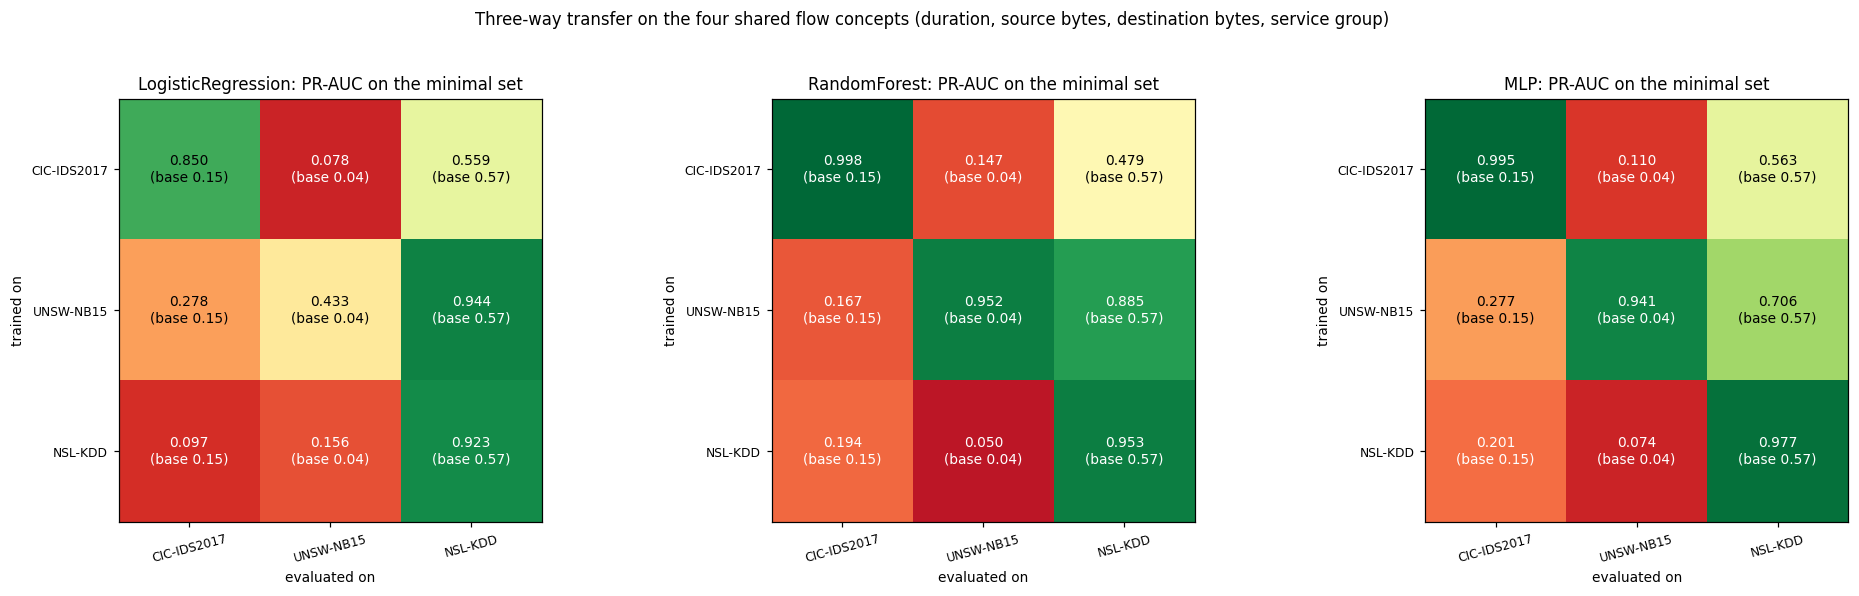

[figure] fig15_minimal_three_way.png + .pdf   ->  Results - RQ2 three-way comparison


In [ ]:
# --- F15: three-way minimal transfer matrix --------------------------------
order = ["cic", "unsw", "nsl"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, mn in zip(axes, MODEL_ORDER):
    mat = np.full((3, 3), np.nan)
    for i, s_ in enumerate(order):
        q = MIN[(MIN.source == s_) & (MIN.model == mn)]
        if len(q):
            for j, t_ in enumerate(order):
                mat[i, j] = q.iloc[0][f"pr_auc_{t_}"]
    im = ax.imshow(mat, cmap="RdYlGn", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(mat):
        if not np.isnan(v):
            base = float(MIN[(MIN.source == order[i]) & (MIN.model == mn)]
                         .iloc[0][f"base_{order[j]}"])
            ax.text(j, i, f"{v:.3f}\n(base {base:.2f})", ha="center", va="center", fontsize=9,
                    color="black" if 0.25 < v < 0.85 else "white")
    ax.set(xticks=range(3), yticks=range(3), title=f"{mn}: PR-AUC on the minimal set")
    ax.set_xticklabels([LONG[o] for o in order], fontsize=8, rotation=15)
    ax.set_yticklabels([LONG[o] for o in order], fontsize=8)
    ax.set_xlabel("evaluated on"); ax.set_ylabel("trained on")
    ax.grid(False)
fig.suptitle("Three-way transfer on the four shared flow concepts "
             "(duration, source bytes, destination bytes, service group)", y=1.03)
fig.tight_layout()
savefig(fig, "fig15_minimal_three_way",
        "Transfer across all three datasets using the only four flow concepts they share. "
        "Each cell shows test PR-AUC with the target's attack base rate in brackets, since "
        "a score at the base rate is equivalent to random ranking. The diagonal shows what "
        "four features can achieve within a dataset.",
        "Results - RQ2 three-way comparison")

Printing each target's base rate inside the cell prevents a PR-AUC from being read as good when it is merely the prior.  
The diagonal shows how much of each dataset four features alone can solve, which bounds what any off-diagonal cell could reach.  
NSL-KDD behaving unlike the two flow-based datasets is the documented limitation the proposal anticipated.

---
# 6. Research Question 3 — the effect of the imbalance strategy

> **RQ3 (supporting).** What impact does the chosen method for dealing with class imbalance have
> on minority-attack detection and false-positive behaviour?

This is Experiment 3. Five strategies are compared on both datasets, and the effect of simply
moving the decision threshold is separated out, because threshold selection is itself an
imbalance treatment and is often confounded with resampling in published comparisons.

All resampling is fitted on the **training partition only**. Validation and test partitions keep
their natural class distribution, so every reported number refers to the real prior.

In [ ]:
# --- Free memory no longer needed before the imbalance experiments ---------
for k in ["B"]:
    if k in DATA:
        del DATA[k]
try:
    del MINF
except NameError:
    pass
gc.collect(); mem("before RQ3")

# --- Resampling strategies, all training-only ------------------------------
from sklearn.neighbors import NearestNeighbors

def resample_none(X, y, seed=SEED):
    return X, y

def resample_under(X, y, seed=SEED):
    r = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keep = np.sort(np.concatenate([pos, r.choice(neg, min(len(neg), len(pos)), replace=False)]))
    return X[keep], y[keep]

def resample_over(X, y, seed=SEED):
    r = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    extra = r.choice(pos, max(0, len(neg) - len(pos)), replace=True)
    idx = np.sort(np.concatenate([pos, neg, extra]))
    return X[idx], y[idx]

def resample_smote(X, y, seed=SEED, k=5):
    """Minority oversampling by interpolation, implemented on sklearn NearestNeighbors."""
    r = np.random.default_rng(seed)
    pos = np.where(y == 1)[0]
    n_need = int((y == 0).sum() - len(pos))
    if n_need <= 0 or len(pos) < 2:
        return X, y
    n_need = min(n_need, 400_000)
    Xmin = X[pos]
    nn = NearestNeighbors(n_neighbors=min(k + 1, len(Xmin)), n_jobs=-1).fit(Xmin)
    seeds_i = r.integers(0, len(Xmin), n_need)
    _, nb = nn.kneighbors(Xmin[seeds_i])
    pick = nb[np.arange(n_need), r.integers(1, nb.shape[1], n_need)]
    lam = r.random((n_need, 1)).astype(np.float32)
    Xnew = (Xmin[seeds_i] + lam * (Xmin[pick] - Xmin[seeds_i])).astype(np.float32)
    return np.vstack([X, Xnew]), np.r_[y, np.ones(n_need, dtype=np.int8)]

STRATEGIES = {
    "none":            dict(fn=resample_none,  weight=None),
    "class_weight":    dict(fn=resample_none,  weight="balanced"),
    "undersample":     dict(fn=resample_under, weight=None),
    "oversample":      dict(fn=resample_over,  weight=None),
    "smote":           dict(fn=resample_smote, weight=None),
}
RARE = {"cic": ["Bot", "Web Attack - Brute Force", "Web Attack - XSS",
                "Web Attack - Sql Injection", "Infiltration", "Heartbleed"],
        "unsw": ["Backdoor", "Backdoors", "Worms", "Shellcode", "Analysis"]}
print("Strategies:", list(STRATEGIES))
print("Every strategy is applied to the training rows only; validation and test keep the")
print("natural prior, so all reported metrics refer to the real class distribution.")
print("SMOTE is implemented here on sklearn NearestNeighbors rather than imbalanced-learn,")
print("so the notebook has no extra dependency that could fail to install.")

    [memory]  7.62 GB  before RQ3
Strategies: ['none', 'class_weight', 'undersample', 'oversample', 'smote']
Every strategy is applied to the training rows only; validation and test keep the
natural prior, so all reported metrics refer to the real class distribution.
SMOTE is implemented here on sklearn NearestNeighbors rather than imbalanced-learn,
so the notebook has no extra dependency that could fail to install.


Five treatments span the standard options: do nothing, reweight the loss, discard majority rows, duplicate minority rows and synthesise minority rows.  
Resampling touches the training partition only, which is the control that stops a resampled test set from inventing performance.  
SMOTE is implemented directly on scikit-learn so the notebook cannot fail because an extra package would not install.

In [ ]:
# --- Experiment 3: imbalance strategies on both datasets -------------------
RQ3, RQ3_PROBS = [], {}
IMB_SETS = {
    "cic":  dict(X=DATA["A"], Y=Y, fine=YFINE, imb=(1 - Y["train"].mean()) / Y["train"].mean()),
    "unsw": dict(X=XU, Y=YU, fine=YU_FINE, imb=(1 - YU["train"].mean()) / YU["train"].mean()),
}
for ds, cfgd in IMB_SETS.items():
    Xa, Ya = cfgd["X"], cfgd["Y"]
    n = min(CFG["rq3_rows"], len(Ya["train"]))
    base_i = np.sort(np.random.default_rng(SEED).choice(len(Ya["train"]), n, replace=False))
    print(f"\n{'='*76}\n{LONG[ds]}  imbalance 1:{cfgd['imb']:.1f}  "
          f"({n:,} training rows, {int(Ya['train'][base_i].sum()):,} attacks)\n{'='*76}")
    for sname, spec in STRATEGIES.items():
        for mn in ["RandomForest", "LogisticRegression"]:
            for seed in CFG["rq3_seeds"]:
                key = f"rq3_{ds}_{sname}_{mn}_{seed}"
                def _f(sname=sname, spec=spec, mn=mn, seed=seed):
                    Xs, ys = spec["fn"](Xa["train"][base_i], Ya["train"][base_i], seed=seed)
                    if mn == "RandomForest":
                        w = "balanced_subsample" if spec["weight"] else None
                        _, pv, pt, f_s, i_s, ex = run_rf(Xs, ys, Xa["val"], Xa["test"],
                                                         seed=seed, class_weight=w, light=True)
                    else:
                        _, pv, pt, f_s, i_s, ex = run_lr(Xs, ys, Xa["val"], Xa["test"],
                                                         seed=seed,
                                                         class_weight=spec["weight"])
                    rr = evaluate(mn, sname, Ya["val"], pv, Ya["test"], pt, f_s, i_s,
                                  len(Ya["test"]),
                                  extra={"dataset": ds, "seed": seed,
                                         "n_train_after": int(len(ys)),
                                         "train_attack_pct": round(100 * float(ys.mean()), 3)})
                    d05 = at_threshold(Ya["test"], pt, 0.5)
                    rr.update({"recall_at_0.5": d05["recall"], "fpr_at_0.5": d05["fpr"],
                               "f1_at_0.5": d05["f1"], "mcc_at_0.5": d05["mcc"]})
                    del Xs, ys; gc.collect()
                    return rr, pv, pt
                rr, pv, pt = run_config(key, _f)
                RQ3.append(rr)
                if seed == CFG["rq3_seeds"][0]:
                    RQ3_PROBS[(ds, sname, mn)] = pt
                gc.collect()
            last = RQ3[-1]
            print(f"  {sname:14s} {mn:18s} PR-AUC={last['pr_auc']:.5f}  "
                  f"DR@1%FPR={last['fpr1_recall']:.5f}  "
                  f"recall@0.5={last['recall_at_0.5']:.4f}  FPR@0.5={last['fpr_at_0.5']:.5f}  "
                  f"train rows {last['n_train_after']:,}")

R3 = pd.DataFrame(RQ3)
R3.to_csv(RES / "rq3_imbalance_runs.csv", index=False)
R3AGG = (R3.groupby(["dataset", "model", "feature_set"])
           .agg(pr_auc=("pr_auc", "mean"), pr_auc_std=("pr_auc", "std"),
                dr_1fpr=("fpr1_recall", "mean"), dr_std=("fpr1_recall", "std"),
                fpr_1=("fpr1_fpr", "mean"), f1=("f1_f1", "mean"),
                mcc=("f1_mcc", "mean"), recall_05=("recall_at_0.5", "mean"),
                fpr_05=("fpr_at_0.5", "mean"), fit_s=("fit_seconds", "mean"),
                train_rows=("n_train_after", "mean"))
           .round(5).reset_index().rename(columns={"feature_set": "strategy"}))
display(R3AGG)
R3AGG.to_csv(RES / "rq3_summary.csv", index=False)
M["results"]["rq3"] = R3AGG.to_dict("records")
mem("after RQ3")


CIC-IDS2017  imbalance 1:5.6  (200,000 training rows, 30,073 attacks)
  none           RandomForest       PR-AUC=0.99981  DR@1%FPR=0.99910  recall@0.5=0.9927  FPR@0.5=0.00021  train rows 200,000
  none           LogisticRegression PR-AUC=0.99475  DR@1%FPR=0.98796  recall@0.5=0.9667  FPR@0.5=0.00396  train rows 200,000
  class_weight   RandomForest       PR-AUC=0.99985  DR@1%FPR=0.99941  recall@0.5=0.9969  FPR@0.5=0.00073  train rows 200,000
  class_weight   LogisticRegression PR-AUC=0.99347  DR@1%FPR=0.99051  recall@0.5=0.9930  FPR@0.5=0.01395  train rows 200,000
  undersample    RandomForest       PR-AUC=0.99978  DR@1%FPR=0.99915  recall@0.5=0.9968  FPR@0.5=0.00129  train rows 60,146
  undersample    LogisticRegression PR-AUC=0.99372  DR@1%FPR=0.98849  recall@0.5=0.9924  FPR@0.5=0.01630  train rows 60,146
  oversample     RandomForest       PR-AUC=0.99989  DR@1%FPR=0.99963  recall@0.5=0.9973  FPR@0.5=0.00072  train rows 339,854
  oversample     LogisticRegression PR-AUC=0.99377  DR@1

,dataset,model,strategy,pr_auc,pr_auc_std,dr_1fpr,dr_std,fpr_1,f1,mcc,recall_05,fpr_05,fit_s,train_rows
0,cic,LogisticRegression,class_weight,0.99347,0.00000,0.99051,0.00000,0.00983,0.97250,0.96761,0.99298,0.01394,8.53333,200000.0
1,cic,LogisticRegression,none,0.99475,0.00000,0.98796,0.00000,0.00971,0.97687,0.97274,0.96674,0.00396,7.70000,200000.0
2,cic,LogisticRegression,oversample,0.99369,0.00010,0.99046,0.00005,0.00979,0.97369,0.96900,0.99254,0.01374,18.93333,339854.0
3,cic,LogisticRegression,smote,0.99359,0.00010,0.99045,0.00012,0.00990,0.97414,0.96954,0.99270,0.01367,20.90000,339854.0
4,cic,LogisticRegression,undersample,0.99369,0.00004,0.98748,0.00093,0.00967,0.96832,0.96268,0.99293,0.01587,2.30000,60146.0
5,cic,RandomForest,class_weight,0.99985,0.00001,0.99945,0.00004,0.01015,0.99658,0.99598,0.99691,0.00072,47.76667,200000.0
6,cic,RandomForest,none,0.99982,0.00001,0.99919,0.00009,0.01001,0.99638,0.99573,0.99287,0.00021,49.73333,200000.0
7,cic,RandomForest,oversample,0.99987,0.00003,0.99954,0.00010,0.01018,0.99679,0.99621,0.99720,0.00070,63.63333,339854.0
8,cic,RandomForest,smote,0.99987,0.00001,0.99969,0.00006,0.01011,0.99654,0.99593,0.99699,0.00073,88.80000,339854.0
9,cic,RandomForest,undersample,0.99978,0.00002,0.99910,0.00006,0.01013,0.99534,0.99450,0.99696,0.00127,11.53333,60146.0


    [memory]  7.66 GB  after RQ3


Each strategy is repeated across seeds on both datasets so the comparison carries a spread rather than a single point.  
Metrics are reported at the tuned threshold and again at the default cut-off of 0.5, which separates the resampling effect from the threshold effect.  
The training row count after resampling is recorded because undersampling and SMOTE change the computational cost as well as the balance.

In [ ]:
# --- Minority-family recall under each strategy ----------------------------
rows = []
for (ds, sname, mn), pt in RQ3_PROBS.items():
    sel = R3[(R3.dataset == ds) & (R3.feature_set == sname) & (R3.model == mn)]
    if not len(sel):
        continue
    thr = float(sel.iloc[0]["fpr1_threshold"])
    fine = IMB_SETS[ds]["fine"]["test"]
    for fam in RARE[ds]:
        m_ = fine == fam
        if m_.sum() == 0:
            continue
        rows.append({"dataset": ds, "strategy": sname, "model": mn, "family": fam,
                     "support": int(m_.sum()),
                     "recall_at_1pct_fpr": round(float((pt[m_] >= thr).mean()), 5)})
MINR = pd.DataFrame(rows)
if len(MINR):
    for ds in MINR.dataset.unique():
        sub = MINR[(MINR.dataset == ds) & (MINR.model == "RandomForest")]
        if len(sub):
            print(f"\n{LONG[ds]} - Random Forest, recall of rare attack families "
                  f"at a 1% false-positive budget")
            display(sub.pivot(index="family", columns="strategy",
                              values="recall_at_1pct_fpr").round(4))
    MINR.to_csv(RES / "rq3_minority_recall.csv", index=False)

print("\nEffect of moving the threshold, holding the strategy fixed:")
for (ds, mn), g in R3AGG.groupby(["dataset", "model"]):
    n_ = g[g.strategy == "none"]
    if len(n_):
        n_ = n_.iloc[0]
        print(f"  {LONG[ds][:12]:12s} {mn:18s} strategy 'none': recall {n_.recall_05:.4f} at "
              f"threshold 0.5 -> {n_.dr_1fpr:.4f} at the validation-selected threshold "
              f"(FPR {n_.fpr_05:.5f} -> {n_.fpr_1:.5f})")
print("\nIf threshold moving alone recovers most of what resampling achieves, the practical")
print("recommendation is to tune the operating point rather than to distort the training set.")
M["results"]["rq3_minority"] = MINR.to_dict("records") if len(MINR) else []


CIC-IDS2017 - Random Forest, recall of rare attack families at a 1% false-positive budget


strategy,class_weight,none,oversample,smote,undersample
family,,,,,
Bot,0.9138,0.8793,0.9000,0.9379,0.8345
Heartbleed,1.0000,1.0000,1.0000,1.0000,1.0000
Infiltration,0.2857,0.2857,0.2857,0.4286,0.1429
Web Attack - Brute Force,1.0000,1.0000,1.0000,1.0000,1.0000
Web Attack - Sql Injection,1.0000,1.0000,1.0000,1.0000,1.0000
Web Attack - XSS,1.0000,1.0000,1.0000,1.0000,0.9923



UNSW-NB15 - Random Forest, recall of rare attack families at a 1% false-positive budget


strategy,class_weight,none,oversample,smote,undersample
family,,,,,
Analysis,0.6975,0.7531,0.7037,0.7840,0.7531
Backdoor,0.9886,1.0000,1.0000,1.0000,0.8636
Shellcode,1.0000,1.0000,1.0000,1.0000,0.9966
Worms,0.9697,1.0000,0.9697,0.9697,0.9697



Effect of moving the threshold, holding the strategy fixed:
  CIC-IDS2017  LogisticRegression strategy 'none': recall 0.9667 at threshold 0.5 -> 0.9880 at the validation-selected threshold (FPR 0.00396 -> 0.00971)
  CIC-IDS2017  RandomForest       strategy 'none': recall 0.9929 at threshold 0.5 -> 0.9992 at the validation-selected threshold (FPR 0.00021 -> 0.01001)
  UNSW-NB15    LogisticRegression strategy 'none': recall 0.8841 at threshold 0.5 -> 0.9506 at the validation-selected threshold (FPR 0.00542 -> 0.00993)
  UNSW-NB15    RandomForest       strategy 'none': recall 0.9026 at threshold 0.5 -> 0.9785 at the validation-selected threshold (FPR 0.00365 -> 0.01006)

If threshold moving alone recovers most of what resampling achieves, the practical
recommendation is to tune the operating point rather than to distort the training set.


Aggregate PR-AUC can stay flat while the rare families that motivate the whole exercise behave very differently under each strategy.  
The pivot table is therefore the real answer to RQ3, since the question is specifically about minority-attack detection.  
The final comparison isolates threshold moving, which is free, from resampling, which costs training time and distorts the prior.

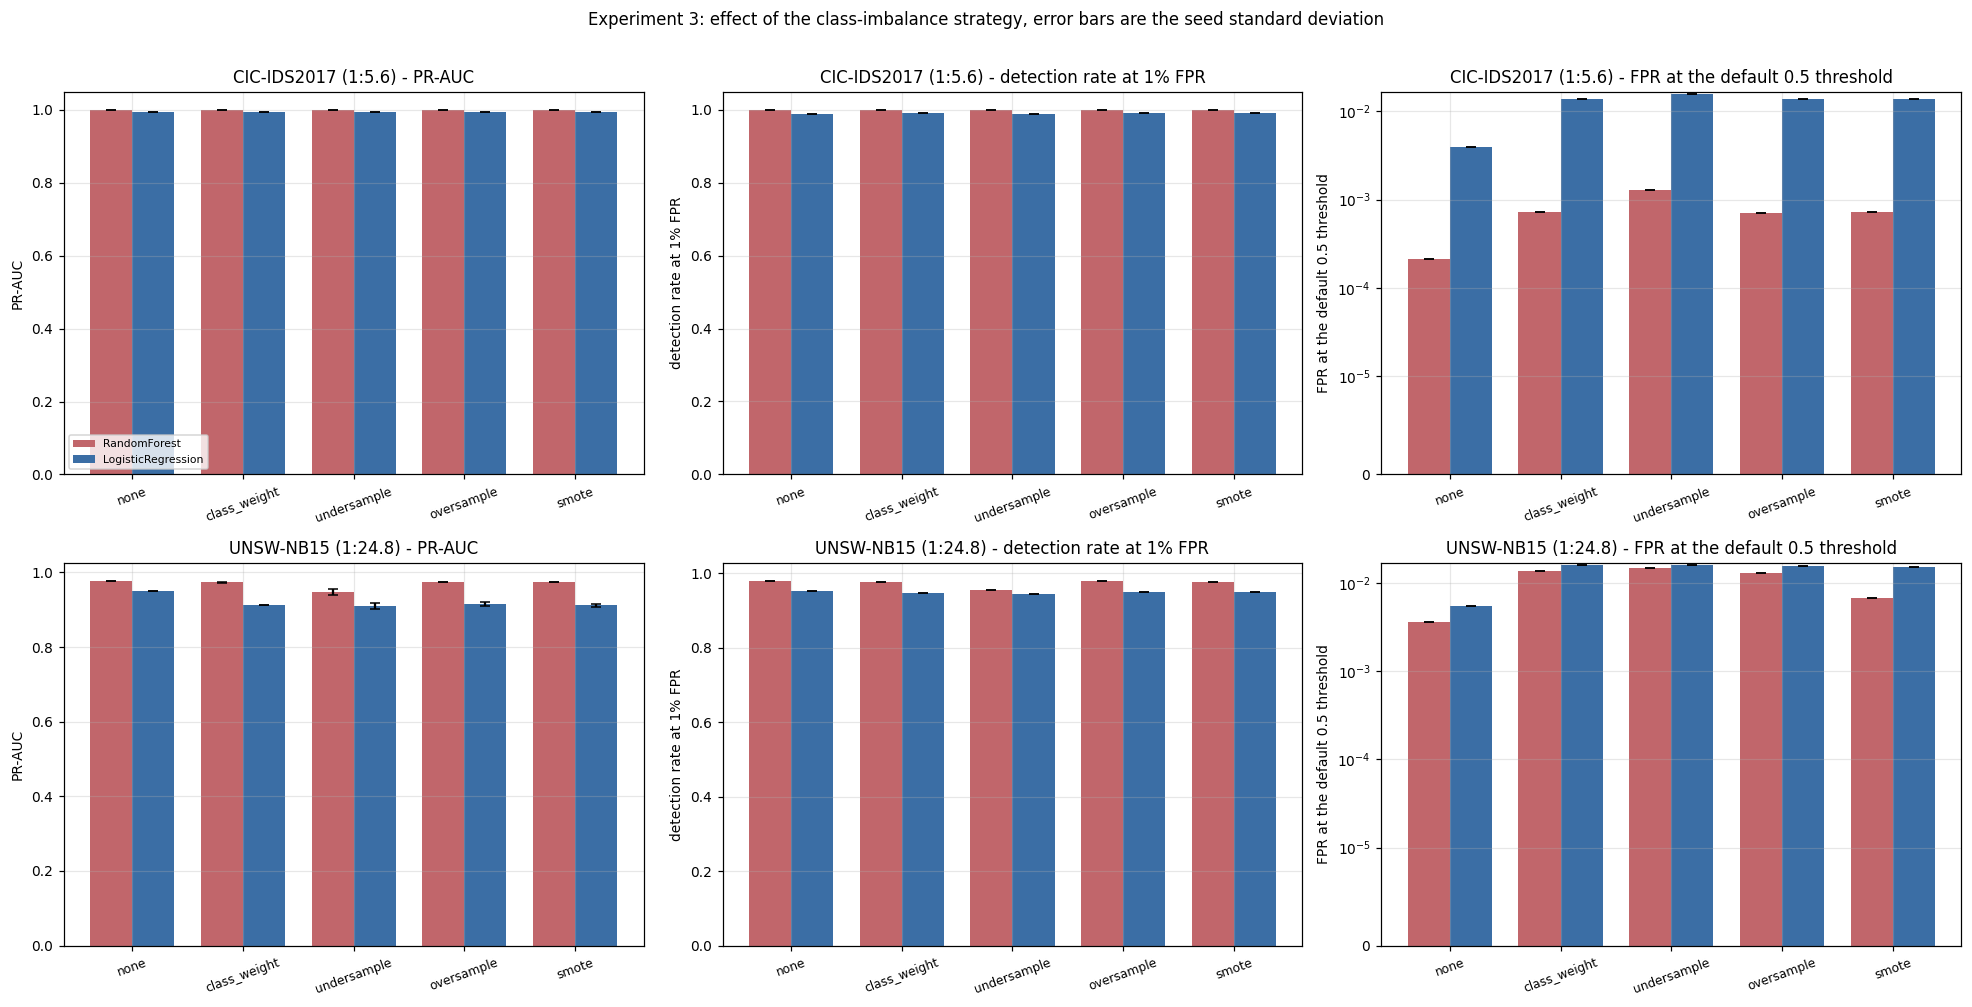

[figure] fig16_imbalance_strategies.png + .pdf   ->  Results - RQ3 imbalance


In [ ]:
# --- F16: imbalance strategies -------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
strats = list(STRATEGIES)
for i, ds in enumerate(["cic", "unsw"]):
    sub = R3AGG[(R3AGG.dataset == ds)]
    for ax, (col, lbl) in zip(axes[i], [("pr_auc", "PR-AUC"),
                                        ("dr_1fpr", "detection rate at 1% FPR"),
                                        ("fpr_05", "FPR at the default 0.5 threshold")]):
        xs = np.arange(len(strats)); w = 0.38
        for k, mn in enumerate(["RandomForest", "LogisticRegression"]):
            v, e = [], []
            for s_ in strats:
                q = sub[(sub.model == mn) & (sub.strategy == s_)]
                v.append(float(q[col].iloc[0]) if len(q) else np.nan)
                sd = q["pr_auc_std"].iloc[0] if (len(q) and col == "pr_auc") else 0
                e.append(0 if pd.isna(sd) else sd)
            ax.bar(xs + (k - 0.5) * w, v, w, yerr=e, capsize=3, color=COLORS[mn], label=mn)
        ax.set(xticks=xs, ylabel=lbl,
               title=f"{LONG[ds]} (1:{IMB_SETS[ds]['imb']:.1f}) - {lbl}")
        ax.set_xticklabels(strats, rotation=20, fontsize=8)
        if col == "fpr_05":
            ax.set_yscale("symlog", linthresh=1e-5)
        if i == 0 and col == "pr_auc":
            ax.legend(fontsize=7)
fig.suptitle("Experiment 3: effect of the class-imbalance strategy, error bars are the "
             "seed standard deviation", y=1.01)
fig.tight_layout()
savefig(fig, "fig16_imbalance_strategies",
        "Effect of five class-imbalance strategies on both datasets. The third column shows "
        "the false-positive rate at the default 0.5 threshold, where resampling and "
        "reweighting do most of their visible damage, while the first two columns show that "
        "threshold-free ranking quality is far less affected.",
        "Results - RQ3 imbalance")

The first two columns show ranking quality, which resampling barely changes on either dataset.  
The third column shows what resampling really does: it shifts where the default threshold sits, inflating false positives.  
Error bars are the seed standard deviation, so any bar difference smaller than the bars should not be interpreted.

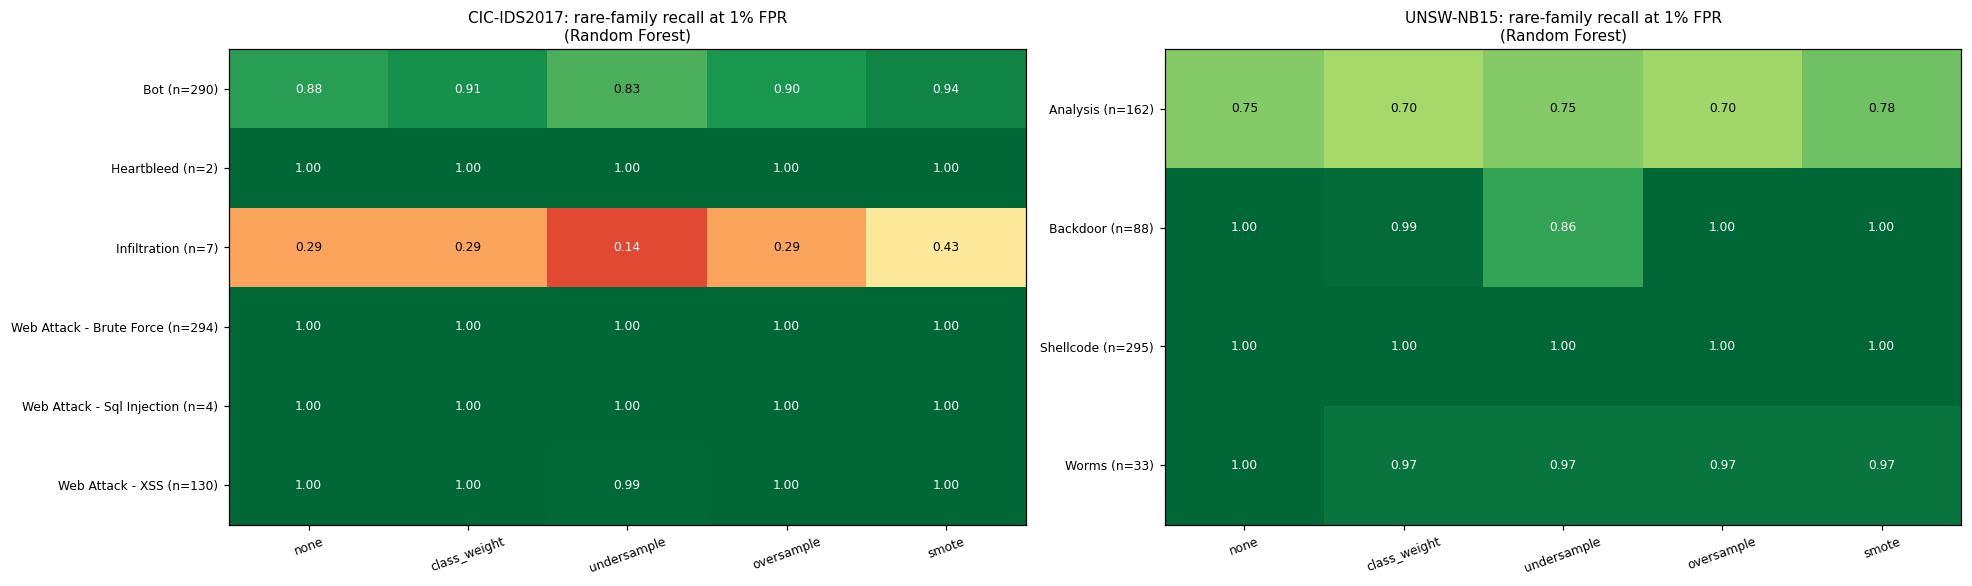

[figure] fig17_minority_recall.png + .pdf   ->  Results - RQ3 minority classes


In [ ]:
# --- F17: minority-family recall by strategy -------------------------------
if len(MINR):
    ds_list = [d for d in ["cic", "unsw"] if (MINR.dataset == d).any()]
    fig, axes = plt.subplots(1, len(ds_list), figsize=(9 * len(ds_list), 5.4), squeeze=False)
    for ax, ds in zip(axes[0], ds_list):
        sub = MINR[(MINR.dataset == ds) & (MINR.model == "RandomForest")]
        piv = sub.pivot(index="family", columns="strategy", values="recall_at_1pct_fpr")
        piv = piv.reindex(columns=[s for s in strats if s in piv.columns])
        im = ax.imshow(piv.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(piv.shape[1]))
        ax.set_xticklabels(piv.columns, rotation=20, fontsize=8)
        ax.set_yticks(range(len(piv)))
        sup = sub.groupby("family")["support"].first()
        ax.set_yticklabels([f"{i} (n={int(sup[i]):,})" for i in piv.index], fontsize=8)
        for (r_, c_), v in np.ndenumerate(piv.values):
            if not np.isnan(v):
                ax.text(c_, r_, f"{v:.2f}", ha="center", va="center", fontsize=8,
                        color="black" if 0.25 < v < 0.85 else "white")
        ax.set_title(f"{LONG[ds]}: rare-family recall at 1% FPR\n(Random Forest)", fontsize=10)
        ax.grid(False)
    fig.tight_layout()
    savefig(fig, "fig17_minority_recall",
            "Recall of the rarest attack families under each imbalance strategy at a one per "
            "cent false-positive budget, with test-set support beside each family. These are "
            "the classes RQ3 is about, and they respond to the choice of strategy far more "
            "than the aggregate metrics do.",
            "Results - RQ3 minority classes")

This heatmap is the clearest evidence for RQ3 because it looks only at the classes the question concerns.  
Families with double-digit support move sharply between strategies, which is exactly where the choice matters.  
Support counts are shown so a recall computed over eleven flows is not over-interpreted.

---
# 7. Optional Experiment 5 — multiclass attack categorisation within one dataset

The proposal lists a dataset-internal multiclass variant as optional. It is included because
binary detection alone cannot tell an analyst *what* is happening, and because per-class results
expose which families the model confuses with each other rather than merely missing.

In [ ]:
# --- Multiclass attack categorisation on CIC-IDS2017 -----------------------
from sklearn.metrics import f1_score as _f1
ycan = df["y_canon"].astype(str).to_numpy()
YC = {p: ycan[sp[p]] for p in ["train", "val", "test"]}
classes = sorted(pd.Series(YC["train"]).value_counts().index.tolist())
n_mc = min(CFG["multiclass_rows"], len(YC["train"]))
mc_i = np.sort(np.random.default_rng(SEED).choice(len(YC["train"]), n_mc, replace=False))
print(f"Multiclass task: {len(classes)} canonical classes on {n_mc:,} training rows")
print(pd.Series(YC["train"][mc_i]).value_counts().to_string())

t0 = time.time()
mc = RandomForestClassifier(n_estimators=150, max_depth=25, min_samples_leaf=5,
                            max_features="sqrt", class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
mc.fit(DATA["A"]["train"][mc_i], YC["train"][mc_i])
fit_s = time.time() - t0
pred = mc.predict(DATA["A"]["test"])
macro = _f1(YC["test"], pred, average="macro", labels=classes, zero_division=0)
weighted = _f1(YC["test"], pred, average="weighted", labels=classes, zero_division=0)
print(f"\nfitted in {fit_s:.0f}s   macro F1={macro:.5f}   weighted F1={weighted:.5f}")
rep = pd.DataFrame(classification_report(YC["test"], pred, labels=classes,
                                         output_dict=True, zero_division=0)).T
display(rep.round(4))
rep.to_csv(RES / "multiclass_report.csv")
CM = confusion_matrix(YC["test"], pred, labels=classes)
np.save(PROB / "multiclass_confusion.npy", CM)
M["results"]["multiclass"] = {"classes": classes, "macro_f1": float(macro),
                              "weighted_f1": float(weighted), "fit_seconds": round(fit_s, 1),
                              "report": rep.round(5).to_dict()}
del mc; gc.collect()

Multiclass task: 9 canonical classes on 400,000 training rows
Benign          339745
DoS              34471
DDoS             22661
BruteForce        1605
Recon              853
WebAttack          398
Botnet             258
Infiltration         5
Exploit              4

fitted in 192s   macro F1=0.90335   weighted F1=0.99864


,precision,recall,f1-score,support
Benign,0.9996,0.9987,0.9992,380851.0000
Botnet,0.4387,0.8759,0.5846,290.0000
BruteForce,0.9956,0.9891,0.9923,1831.0000
DDoS,0.9995,0.9992,0.9993,25603.0000
DoS,0.9961,0.9984,0.9973,38720.0000
Exploit,1.0000,1.0000,1.0000,2.0000
Infiltration,1.0000,0.4286,0.6000,7.0000
Recon,0.9817,0.9897,0.9857,973.0000
WebAttack,0.9764,0.9673,0.9718,428.0000
accuracy,0.9985,0.9985,0.9985,0.9985


29311

The nine canonical families defined in Notebook 02 are used, so the classes mean the same thing they did during harmonisation.  
Macro F1 is reported alongside weighted F1 because the weighted figure is dominated by the three largest families.  
The per-class report shows precision and recall separately, which distinguishes a class that is missed from one that is over-predicted.

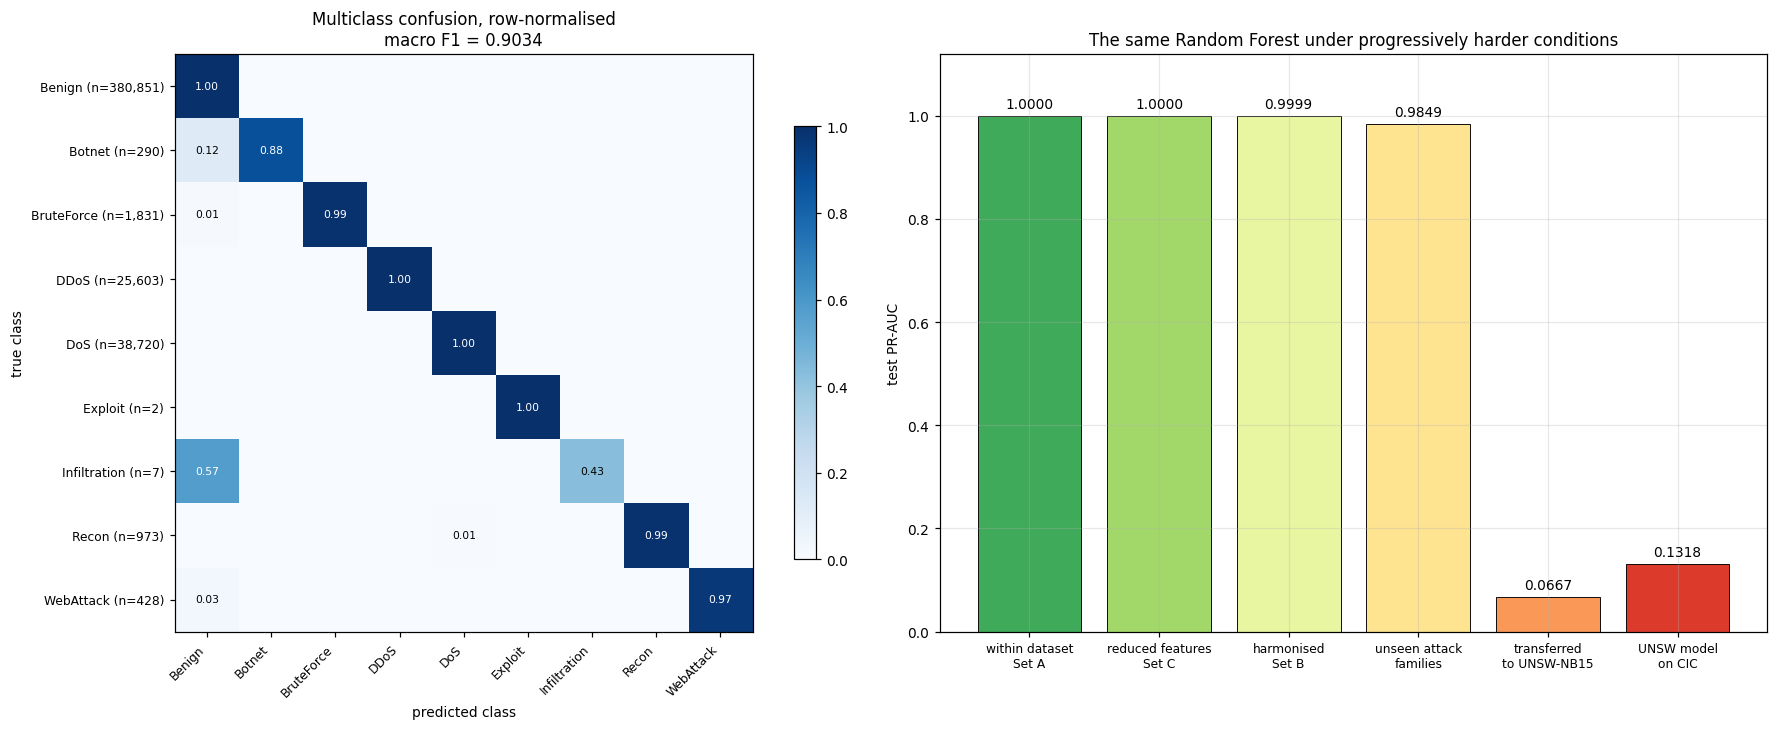

[figure] fig18_multiclass_and_staircase.png + .pdf   ->  Evaluation - overall synthesis


In [ ]:
# --- F18: multiclass confusion and the generalisation staircase ------------
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
cmn = CM / np.clip(CM.sum(axis=1, keepdims=True), 1, None)
im = axes[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(len(classes))); axes[0].set_yticks(range(len(classes)))
axes[0].set_xticklabels(classes, rotation=45, ha="right", fontsize=8)
axes[0].set_yticklabels([f"{c} (n={CM[i].sum():,})" for i, c in enumerate(classes)], fontsize=8)
for (i, j), v in np.ndenumerate(cmn):
    if v > 0.004:
        axes[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                     color="white" if v > 0.5 else "black")
axes[0].set(xlabel="predicted class", ylabel="true class",
            title=f"Multiclass confusion, row-normalised\nmacro F1 = {macro:.4f}")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], shrink=.75)

stair, labels_ = [], []
b_ = RES2[(RES2.model == "RandomForest") & (RES2.feature_set == "A")]
if len(b_):
    stair.append(float(b_.iloc[0].pr_auc)); labels_.append("within dataset\nSet A")
c_ = RES2[(RES2.model == "RandomForest") & (RES2.feature_set == "C")]
if len(c_):
    stair.append(float(c_.iloc[0].pr_auc)); labels_.append("reduced features\nSet C")
bb = RES2[(RES2.model == "RandomForest") & (RES2.feature_set == "B")]
if len(bb):
    stair.append(float(bb.iloc[0].pr_auc)); labels_.append("harmonised\nSet B")
if len(UNS):
    u_ = UNS[UNS.model == "RandomForest"]
    if len(u_):
        stair.append(float(u_.iloc[0].pr_auc)); labels_.append("unseen attack\nfamilies")
t_ = TR[(TR.source == "cic") & (TR.model == "RandomForest")]
if len(t_):
    stair.append(float(t_.iloc[0].transfer_pr_auc)); labels_.append("transferred\nto UNSW-NB15")
t2 = TR[(TR.source == "unsw") & (TR.model == "RandomForest")]
if len(t2):
    stair.append(float(t2.iloc[0].transfer_pr_auc)); labels_.append("UNSW model\non CIC")
cols_ = plt.cm.RdYlGn(np.linspace(0.85, 0.12, len(stair)))
axes[1].bar(range(len(stair)), stair, color=cols_, edgecolor="black", linewidth=.6)
for i, v in enumerate(stair):
    axes[1].text(i, v + 0.015, f"{v:.4f}", ha="center", fontsize=9)
axes[1].set(xticks=range(len(stair)), ylim=(0, 1.12), ylabel="test PR-AUC",
            title="The same Random Forest under progressively harder conditions")
axes[1].set_xticklabels(labels_, fontsize=8)
fig.tight_layout()
savefig(fig, "fig18_multiclass_and_staircase",
        "Left: row-normalised multiclass confusion matrix over the nine canonical attack "
        "families. Right: the same Random Forest evaluated under progressively harder "
        "conditions, from the standard within-dataset split through feature reduction and "
        "unseen attack families to full cross-dataset transfer.",
        "Evaluation - overall synthesis")

The confusion matrix shows which families are confused with which, rather than only which are missed.  
The staircase on the right is the single most useful figure for the discussion chapter, because it places the near-perfect benchmark score next to what happens under realistic conditions.  
Every bar comes from the same model and the same pipeline, so the decline is caused by the evaluation condition alone.

---
# 8. Deliverables: tables, figures and the traceability record

In [ ]:
# --- Figure index for the dissertation -------------------------------------
prev = [
    ("nb01", "fig01_class_distributions", "Data understanding",
     "Class distribution of the three benchmark datasets on a logarithmic scale."),
    ("nb01", "fig02_data_quality", "Data understanding",
     "Missing values, infinite values and duplicate-row rates per dataset."),
    ("nb01", "fig03_leakage_screen", "Methodology - leakage control",
     "Single-feature separability screen identifying candidate artefact features."),
    ("nb01", "fig04_covariate_shift", "Data understanding",
     "Distribution comparison of shared features between CIC-IDS2017 and UNSW-NB15."),
    ("nb01", "fig05_correlation", "Data understanding",
     "Pearson correlation structure of the CIC-IDS2017 numeric features."),
    ("nb02", "fig01_transform_effect", "Methodology - preprocessing",
     "Effect of the winsorise, signed-log and robust-scale chain on a heavy-tailed feature."),
    ("nb02", "fig02_residual_shift", "Methodology - harmonisation",
     "Residual distributional distance between datasets after unit harmonisation."),
]
IDX = pd.DataFrame([{"notebook": "nb04", **f} for f in FIGURE_INDEX] +
                   [{"notebook": n, "file_png": f"{f}.png", "file_pdf": f"{f}.pdf",
                     "thesis_section": s, "suggested_caption": c} for n, f, s, c in prev])
IDX.insert(0, "figure_no", [f"Figure {i+1}" for i in range(len(IDX))])
display(IDX[["figure_no", "notebook", "file_png", "thesis_section"]])
IDX.to_csv(RES / "figure_index.csv", index=False)
print(f"\n{len(FIGURE_INDEX)} figures produced by this notebook, {len(IDX)} catalogued in total.")
print("Each exists as a 300 dpi PNG for Word and a vector PDF for LaTeX.")

,figure_no,notebook,file_png,thesis_section
0,Figure 1,nb04,fig01_pr_roc_curves.png,Results - RQ1 discrimination
1,Figure 2,nb04,fig02_detection_vs_budget.png,Evaluation - operational trade-off
2,Figure 3,nb04,fig03_feature_set_degradation.png,Results - RQ1 feature sets
3,Figure 4,nb04,fig04_confusion_matrices.png,Results - RQ1 error analysis
4,Figure 5,nb04,fig05_score_separation_calibration.png,Results - RQ1 diagnostics
5,Figure 6,nb04,fig06_accuracy_vs_cost.png,Evaluation - computational cost
6,Figure 7,nb04,fig07_per_family_recall.png,Results - RQ1 per-class analysis
7,Figure 8,nb04,fig08_variance_selection_learning.png,Methodology - experimental controls
8,Figure 9,nb04,fig09_feature_evidence.png,Results - feature analysis
9,Figure 10,nb04,fig10_unsw_artefact_ablation.png,Evaluation - dataset validity



18 figures produced by this notebook, 25 catalogued in total.
Each exists as a 300 dpi PNG for Word and a vector PDF for LaTeX.


The index turns figure assembly into copying rows, with a caption and a target chapter already written for each.  
Figures from Notebooks 01 and 02 are catalogued alongside so the dissertation has one complete list.  
Numbering follows the order the figures should appear in the report.

In [ ]:
# --- Requirements traceability: objective and research question to evidence -
TRACE = [
    ("Obj 1", "Build a reproducible ML pipeline for network intrusion detection",
     "NB01-02 plus the verified reconstruction in section 1 of this notebook",
     "reconstruction_check.csv, run_manifest_nb04.json"),
    ("Obj 2", "Compare machine learning models across network traffic feature sets",
     "Experiments 1 and 2, full training partition, three seeds for variance",
     "rq1_headline.csv, rq1_feature_set_degradation.csv, rq1_significance_tests.csv"),
    ("Obj 3", "Compare cross-dataset generalisation of CIC-IDS2017, UNSW-NB15 and NSL-KDD",
     "Experiment 4 both directions on Feature Set B, plus a three-way minimal representation",
     "rq2_transfer_results.csv, rq2_minimal_three_way.csv, rq2_threshold_transfer.csv"),
    ("Obj 4", "Evaluate accuracy, recall, precision, F1 and false-positive rate",
     "One metric harness used by every experiment, thresholds fixed on validation",
     "rq1_headline.csv, rq1_per_family_recall.csv, multiclass_report.csv"),
    ("RQ1", "Best feature set and model for detection against false positives",
     "Experiments 1-2 with McNemar and bootstrap testing against the seed noise floor",
     "rq1_headline.csv, rq1_significance_tests.csv, fig01-fig09"),
    ("RQ2", "How well models generalise to a second dataset and why",
     "Experiment 4 both directions, threshold transfer, domain classifier, shift measurement",
     "rq2_transfer_results.csv, rq2_covariate_shift.csv, rq2_domain_importance.csv, fig12-fig15"),
    ("RQ3", "Effect of the imbalance strategy on minority detection and false positives",
     "Experiment 3, five strategies, two datasets, repeated seeds, rare-family recall",
     "rq3_summary.csv, rq3_minority_recall.csv, fig16-fig17"),
    ("Exp 5", "Optional reverse-direction transfer and dataset-internal multiclass",
     "Reverse transfer in section 5 and nine-class categorisation in section 7",
     "rq2_transfer_results.csv, multiclass_report.csv, fig18"),
    ("Validity", "Quantify performance attributable to testbed artefacts",
     "TTL ablation on UNSW-NB15 and the day-disjoint unseen-attack split on CIC-IDS2017",
     "unsw_artefact_ablation.csv, unseen_attack_eval.csv, fig10-fig11"),
]
TRC = pd.DataFrame(TRACE, columns=["ref", "requirement", "how it was addressed",
                                   "evidence files"])
display(TRC)
TRC.to_csv(RES / "traceability_matrix.csv", index=False)
print("\nThis table maps every objective and research question in the proposal to the")
print("experiment that answers it and the file holding the numbers, which is what an")
print("examiner checks first and what Appendix B of the proposal promised.")

,ref,requirement,how it was addressed,evidence files
0,Obj 1,Build a reproducible ML pipeline for network i...,NB01-02 plus the verified reconstruction in se...,"reconstruction_check.csv, run_manifest_nb04.json"
1,Obj 2,Compare machine learning models across network...,"Experiments 1 and 2, full training partition, ...","rq1_headline.csv, rq1_feature_set_degradation...."
2,Obj 3,Compare cross-dataset generalisation of CIC-ID...,"Experiment 4 both directions on Feature Set B,...","rq2_transfer_results.csv, rq2_minimal_three_wa..."
3,Obj 4,"Evaluate accuracy, recall, precision, F1 and f...","One metric harness used by every experiment, t...","rq1_headline.csv, rq1_per_family_recall.csv, m..."
4,RQ1,Best feature set and model for detection again...,Experiments 1-2 with McNemar and bootstrap tes...,"rq1_headline.csv, rq1_significance_tests.csv, ..."
5,RQ2,How well models generalise to a second dataset...,"Experiment 4 both directions, threshold transf...","rq2_transfer_results.csv, rq2_covariate_shift...."
6,RQ3,Effect of the imbalance strategy on minority d...,"Experiment 3, five strategies, two datasets, r...","rq3_summary.csv, rq3_minority_recall.csv, fig1..."
7,Exp 5,Optional reverse-direction transfer and datase...,Reverse transfer in section 5 and nine-class c...,"rq2_transfer_results.csv, multiclass_report.cs..."
8,Validity,Quantify performance attributable to testbed a...,TTL ablation on UNSW-NB15 and the day-disjoint...,"unsw_artefact_ablation.csv, unseen_attack_eval..."



This table maps every objective and research question in the proposal to the
experiment that answers it and the file holding the numbers, which is what an
examiner checks first and what Appendix B of the proposal promised.


Each proposal objective and research question is tied to a specific experiment and a named results file.  
This is the traceability matrix promised in Appendix B of the proposal, now populated with real evidence.  
Writing the dissertation becomes a matter of working down this table rather than searching for numbers.

In [ ]:
# --- Headline numbers for the write-up -------------------------------------
def _g(dfr, q, col, default=None):
    s = dfr.query(q) if isinstance(q, str) else dfr[q]
    return float(s.iloc[0][col]) if len(s) else default

NUM = {
    "dataset_rows": {d: int(len(FRAMES[d])) for d in FRAMES},
    "attack_rate_pct": {d: round(100 * float(FRAMES[d]["y"].mean()), 3) for d in FRAMES},
    "splits": {d: {p: int(len(SPLITS[d][p])) for p in ["train", "val", "test"]} for d in SPLITS},
    "feature_counts": {"A": int(nA), "B": int(nB), "C": int(nC), "k_selected": int(BEST_K)},
    "seed_noise_floor_pr_auc": round(float(NOISE), 6),
    "rq1_best": RES2.sort_values("fpr1_recall", ascending=False).iloc[0][
        ["model", "feature_set", "pr_auc", "roc_auc", "fpr1_recall", "fpr1_fpr", "f1_f1",
         "f1_mcc", "false_alerts_per_1M", "fit_seconds", "infer_us_per_flow"]].to_dict(),
    "rq1_significant_pairs": int(SIG.significant.sum()) if len(SIG) else 0,
    "learning_curve_gain_beyond_400k": round(
        float(LC.pr_auc.iloc[-1] - LC[LC.n_train <= 400_000].pr_auc.max()), 6),
    "unsw_artefact_effect": {
        m: {"pr_auc_with": _g(ABLD, f"model=='{m}' and feature_set=='with_artefacts'", "pr_auc"),
            "pr_auc_without": _g(ABLD, f"model=='{m}' and feature_set=='without_artefacts'",
                                 "pr_auc")}
        for m in ABLD.model.unique()},
    "unseen_attack": ({r["model"]: {"pr_auc": r["pr_auc"], "dr_1fpr": r["fpr1_recall"]}
                       for r in UNS.to_dict("records")} if len(UNS) else {}),
    "unseen_families": unseen_cls,
    "rq2_transfer": TR[["source", "target", "model", "within_pr_auc", "transfer_pr_auc",
                        "retained_pct", "transfer_dr", "transfer_fpr"]].to_dict("records"),
    "rq2_domain_classifier_auc": round(float(dom_auc), 5),
    "rq2_worst_shift_feature": SHIFT.iloc[0].to_dict(),
    "rq3_best_strategy_by_dataset": {
        ds: R3AGG[R3AGG.dataset == ds].sort_values("dr_1fpr", ascending=False)
              .iloc[0][["model", "strategy", "pr_auc", "dr_1fpr", "fpr_1"]].to_dict()
        for ds in R3AGG.dataset.unique()},
    "multiclass_macro_f1": round(float(macro), 5),
}
(RES / "dissertation_numbers.json").write_text(json.dumps(NUM, indent=2, default=str))
print(json.dumps(NUM, indent=2, default=str)[:3000])
print("\n... full record written to dissertation_numbers.json")

{
  "dataset_rows": {
    "cic": 2243524,
    "unsw": 2016614,
    "nsl": 147692
  },
  "attack_rate_pct": {
    "cic": 15.122,
    "unsw": 3.869,
    "nsl": 47.953
  },
  "splits": {
    "cic": {
      "train": 1435855,
      "val": 358964,
      "test": 448705
    },
    "unsw": {
      "train": 1290632,
      "val": 322659,
      "test": 403323
    },
    "nsl": {
      "train": 100240,
      "val": 25060,
      "test": 22392
    }
  },
  "feature_counts": {
    "A": 75,
    "B": 32,
    "C": 40,
    "k_selected": 40
  },
  "seed_noise_floor_pr_auc": 3.6e-05,
  "rq1_best": {
    "model": "RandomForest",
    "feature_set": "A",
    "pr_auc": 0.99995,
    "roc_auc": 0.99999,
    "fpr1_recall": 0.99994,
    "fpr1_fpr": 0.010224,
    "f1_f1": 0.99754,
    "f1_mcc": 0.9971,
    "false_alerts_per_1M": 10224,
    "fit_seconds": 995.0,
    "infer_us_per_flow": 8.44
  },
  "rq1_significant_pairs": 13,
  "learning_curve_gain_beyond_400k": 3.8e-05,
  "unsw_artefact_effect": {
    "RandomForest

Every number a chapter is likely to quote is collected into one machine-readable file, so nothing has to be re-derived by hand.  
Values are taken from the result tables rather than retyped, which removes the risk of a transcription error in the report.  
Keeping this file with the submission is also evidence that the reported figures came from an actual run.

In [ ]:
# --- Manifest, packaging and sync back to Google Drive ---------------------
M["run_finished_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
M["figures"] = FIGURE_INDEX
(RES / "run_manifest_nb04.json").write_text(json.dumps(M, indent=2, default=str))

DEST = PROJECT / "results_pack"
ok, failed = 0, []
for src_dir, name in [(RES, "reports"), (FIG, "figures"), (MODELS, "models")]:
    for p in sorted(src_dir.rglob("*")):
        if p.is_dir():
            continue
        tgt = DEST / name / p.relative_to(src_dir)
        try:
            tgt.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(p, tgt)
            ok += 1
        except Exception as e:
            failed.append((str(p), type(e).__name__))
print(f"Synced {ok} files to {DEST}")
if failed:
    print(f"{len(failed)} files failed to copy (Drive I/O). Retry this cell; the local copies")
    print(f"in {LOCAL} are intact and nothing has been lost.")
    for f_, e_ in failed[:10]:
        print("   ", f_, e_)

try:
    zpath = shutil.make_archive(str(Path("/content/results_pack") if IN_COLAB
                                    else PROJECT / "results_pack_archive"), "zip", str(LOCAL))
    print("Archive:", zpath, f"({os.path.getsize(zpath)/1e6:.1f} MB)")
except Exception as e:
    print("Archive step skipped:", e)

print("\nContents of the results pack:")
for p in sorted(RES.glob("*.csv")):
    print(f"  reports/{p.name:44s} {p.stat().st_size/1024:8.1f} KB")
print(f"  figures/  {len(list(FIG.glob('*.png')))} PNG + {len(list(FIG.glob('*.pdf')))} PDF")

Synced 165 files to /content/drive/MyDrive/nids_benchmark_final/results_pack
Archive: /content/results_pack.zip (219.7 MB)

Contents of the results pack:
  reports/feature_ranking_corrected.csv                     5.7 KB
  reports/feature_set_c_sweep.csv                           0.1 KB
  reports/figure_index.csv                                  8.0 KB
  reports/learning_curve.csv                                0.3 KB
  reports/mlp_history_A.csv                                 0.4 KB
  reports/mlp_history_B.csv                                 0.7 KB
  reports/mlp_history_C.csv                                 0.5 KB
  reports/multiclass_report.csv                             0.8 KB
  reports/reconstruction_check.csv                          0.2 KB
  reports/rq1_feature_set_degradation.csv                   0.4 KB
  reports/rq1_headline.csv                                  1.3 KB
  reports/rq1_per_family_recall.csv                         4.7 KB
  reports/rq1_significance_tests.csv      

Everything was written locally during the run, and only now is it copied to Drive, so a Drive outage cannot destroy hours of computation.  
If any copy fails the local originals remain and this cell can simply be run again.  
The zip archive is convenient for attaching the code and results to the submission alongside the dissertation.

In [ ]:
# --- Final summary ---------------------------------------------------------
line = "=" * 78
print(line + "\nNOTEBOOK 04 SUMMARY\n" + line)
print(f"profile={PROFILE}   device={DEVICE}   seed={SEED}")
print(f"started {M['run_started_utc']}   finished {M['run_finished_utc']}")

print("\n[data]")
for d in FRAMES:
    s = SPLITS[d]
    print(f"  {LONG[d]:12s} {len(FRAMES[d]):>9,} rows  attack {100*FRAMES[d]['y'].mean():6.3f}%  "
          f"{len(s['train']):,}/{len(s['val']):,}/{len(s['test']):,}")
print(f"  feature sets: A={nA}  B={nB}  C={nC} (k={BEST_K} chosen on validation)")

print("\n[RQ1 - models and feature sets, full training partition]")
for _, r in RES2.sort_values("pr_auc", ascending=False).iterrows():
    print(f"  {r.feature_set} | {r.model:18s} PR-AUC={r.pr_auc:.5f}  ROC-AUC={r.roc_auc:.5f}  "
          f"DR@1%FPR={r.fpr1_recall:.5f}  F1={r.f1_f1:.5f}  MCC={r.f1_mcc:.5f}  "
          f"{int(r.false_alerts_per_1M):>6,} false alerts/1M  fit={r.fit_seconds:.0f}s")
print(f"  seed noise floor (PR-AUC std): {NOISE:.6f}; "
      f"{int(SIG.significant.sum()) if len(SIG) else 0} of {len(SIG)} comparisons significant")

print("\n[dataset validity - UNSW TTL artefacts]")
for m in ABLD.model.unique():
    w = ABLD[(ABLD.model == m) & (ABLD.feature_set == "with_artefacts")].iloc[0]
    o = ABLD[(ABLD.model == m) & (ABLD.feature_set == "without_artefacts")].iloc[0]
    print(f"  {m:18s} PR-AUC {w.pr_auc:.5f} -> {o.pr_auc:.5f}   "
          f"ROC-AUC {w.roc_auc:.5f} -> {o.roc_auc:.5f}")

if len(UNS):
    print("\n[unseen attack families: " + ", ".join(unseen_cls) + "]")
    for r in UNS.to_dict("records"):
        print(f"  {r['model']:18s} PR-AUC={r['pr_auc']:.5f}  DR@1%FPR={r['fpr1_recall']:.5f}")

print("\n[RQ2 - cross-dataset transfer, Feature Set B]")
for _, r in TR.iterrows():
    print(f"  {LONG[r.source][:12]:12s} -> {LONG[r.target][:12]:12s} {r.model:18s} "
          f"PR-AUC {r.within_pr_auc:.5f} -> {r.transfer_pr_auc:.5f} "
          f"({r.retained_pct:.1f}% retained)  target FPR at source threshold {r.transfer_fpr:.5f}")
print(f"  domain classifier AUC (CIC vs UNSW in Set B space): {dom_auc:.5f}")
print(f"  worst residual shift: {SHIFT.iloc[0].feature} "
      f"({SHIFT.iloc[0].wasserstein_logscale} normalised Wasserstein)")

print("\n[RQ2 - minimal three-way including NSL-KDD]")
for _, r in MIN[MIN.model == "RandomForest"].iterrows():
    print(f"  trained on {LONG[r.source][:12]:12s} -> PR-AUC  cic={r.pr_auc_cic:.4f}  "
          f"unsw={r.pr_auc_unsw:.4f}  nsl={r.pr_auc_nsl:.4f}")

print("\n[RQ3 - imbalance strategies]")
for ds in R3AGG.dataset.unique():
    b = R3AGG[R3AGG.dataset == ds].sort_values("dr_1fpr", ascending=False).iloc[0]
    print(f"  {LONG[ds]:12s} best: {b.strategy} with {b.model} "
          f"(DR@1%FPR={b.dr_1fpr:.5f}, PR-AUC={b.pr_auc:.5f})")
    n_ = R3AGG[(R3AGG.dataset == ds) & (R3AGG.strategy == "none") &
               (R3AGG.model == "RandomForest")]
    if len(n_):
        n_ = n_.iloc[0]
        print(f"               threshold moving alone: recall {n_.recall_05:.4f} -> "
              f"{n_.dr_1fpr:.4f}")

print(f"\n[multiclass] macro F1 = {macro:.5f} over {len(classes)} canonical families")
print(f"\n[artefacts] {len(list(RES.glob('*.csv')))} tables, {len(FIGURE_INDEX)} figures, "
      f"synced to {DEST}")
print("\n" + line)
print("Start the write-up from traceability_matrix.csv, dissertation_numbers.json and")
print("figure_index.csv. Every claim in the report should point back to one of those rows.")
print(line)

NOTEBOOK 04 SUMMARY
profile=balanced   device=cuda   seed=42
started 2026-09-04T18:40:05+00:00   finished 2026-09-04T21:43:32+00:00

[data]
  CIC-IDS2017  2,243,524 rows  attack 15.122%  1,435,855/358,964/448,705
  UNSW-NB15    2,016,614 rows  attack  3.869%  1,290,632/322,659/403,323
  NSL-KDD        147,692 rows  attack 47.953%  100,240/25,060/22,392
  feature sets: A=75  B=32  C=40 (k=40 chosen on validation)

[RQ1 - models and feature sets, full training partition]
  C | RandomForest       PR-AUC=0.99996  ROC-AUC=0.99999  DR@1%FPR=0.99994  F1=0.99774  MCC=0.99733  10,235 false alerts/1M  fit=680s
  A | RandomForest       PR-AUC=0.99995  ROC-AUC=0.99999  DR@1%FPR=0.99994  F1=0.99754  MCC=0.99710  10,224 false alerts/1M  fit=995s
  A | MLP                PR-AUC=0.99990  ROC-AUC=0.99998  DR@1%FPR=0.99971  F1=0.99614  MCC=0.99545   9,550 false alerts/1M  fit=283s
  C | MLP                PR-AUC=0.99989  ROC-AUC=0.99997  DR@1%FPR=0.99975  F1=0.99568  MCC=0.99492  10,104 false alerts/1M 

The summary block gathers every headline result in one place so it can be pasted into a supervision meeting or a chat.  
Each number is read from the result tables produced above rather than being retyped or approximated.  
The closing pointer names the three files to write the dissertation from, which is the intended next step.

---

## What to do next

1. **Check the summary block above** against the tables in `results_pack/reports/`.
2. **Write from `traceability_matrix.csv`.** Each row is a section of the dissertation with its
   evidence already named.
3. **Insert figures using `figure_index.csv`.** Captions and target sections are pre-written; the
   PNG files are 300 dpi and drop straight into Word.
4. **For the viva**, be ready to defend these five choices:
   - Detection rate at a one per cent false-positive budget rather than accuracy, because a
     trivial always-benign classifier scores about 85 per cent accuracy on this data.
   - Thresholds fixed on validation, because tuning a cut-off on test and then reporting test
     performance at that cut-off is optimistically biased and common in this literature.
   - Feature selection recomputed on the corrected training partition, because the Notebook 02
     ranking used rows that are now in the test set.
   - Seed variance reported first, because a gap smaller than the run-to-run spread is not
     evidence of a better model.
   - The near-perfect within-dataset scores treated as a property of the benchmark rather than of
     the detector, which is precisely what the unseen-attack, ablation and transfer experiments
     were designed to demonstrate.